# Práctica 1 | Predicción Multiclase de Riesgo Cardiovascular en Población Adulta

## PLANTEAMIENTO DEL PROBLEMA

Las enfermedades cardiovasculares son una de las mayores amenazas para la salud pública global y una de las principales causas de morbimortalidad a nivel mundial.
Para combatir este problema, la detección temprana y la estratificación precisa del nivel de riesgo individual son pilares esenciales que permiten aplicar intervenciones preventivas adaptadas a cada paciente y optimizar la gestión de los recursos en los sistemas de salud.
Conscientes de esta necesidad, el equipo médico e investigador del Hospital Morales Meseguer ha puesto en marcha un proyecto estratégico orientado al desarrollo de herramientas predictivas de vanguardia. 
La iniciativa nace con el objetivo de ofrecer una solución integral basada en datos clínicos que transforme la evaluación del riesgo cardiovascular en la práctica médica diaria, mejorando directamente el diagnóstico y el seguimiento del paciente.
Para ello, el equipo médico pone a disposición de este proyecto una cohorte clínica con 2.254 registros de pacientes y 28 variables sociodemográficas, clínicas, analíticas y de estilo de vida para clasificar a los pacientes en tres niveles de riesgo cardiovascular (Clase 0: Bajo Riesgo, Clase 1: Riesgo Moderado y Clase 2: Alto Riesgo).

## 1. Configuración del entorno y reproducibilidad

Antes de nada, se fijan la **semilla** que se reutilizará en todas las técnicas y las librerías.

**Nota:** Este cuaderno se encuentra dentro del proyecto en `notebooks/`, los datos en `data/` y el código reutilizable en `src/`. Todas las rutas se construyen a partir de la raíz del proyecto que llamremos `RAIZ`.

In [1]:
import random
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import math
from scipy import stats

# Importante para que se muestren los gráficos en el cuaderno
%matplotlib inline

# Raíz del proyecto
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# Datos del proyecto
RUTA_DATOS = RAIZ / 'data' / 'raw' / 'enfermedad_cardiovascular.csv'
assert RUTA_DATOS.exists(), f'No se encuentra el dataset en {RUTA_DATOS}'

# Semilla
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
print('Raíz del proyecto:', RAIZ.name)

Raíz del proyecto: MasterIA-ML01


## 2. Carga de datos

Del enunciado esperamos las siguientes variables:

| Tipo | Variable | Unidad / valores |
|---|---|---|
| **Objetivo** | `riesgo_cardiovascular` | 0 = bajo, 1 = moderado, 2 = alto |
| Numérica | `edad` | años cumplidos |
| Numérica | `presion_sistolica`, `presion_diastolica` | mmHg |
| Numérica | `colesterol_total`, `colesterol_hdl`, `colesterol_ldl`, `trigliceridos` | mg/dL |
| Numérica | `glucosa_ayunas` | mg/dL |
| Numérica | `indice_masa_corporal` | kg/m² |
| Numérica | `frecuencia_cardiaca_reposo` | latidos/min |
| Numérica | `horas_sueno_diarias` | horas/día |
| Numérica | `consumo_alcohol_semanal` | UBE/semana |
| Numérica | `anos_fumador` | años |
| Numérica | `proteina_c_reactiva` | mg/L |
| Numérica | `acido_urico` | mg/dL |
| Numérica | `clearance_creatinina` | mL/min |
| Numérica | `frecuencia_ejercicio_semanal` | días/semana |
| Numérica | `perimetro_cintura` | cm |
| Numérica | `hemoglobina_glicosilada` | % (HbA1c) |
| Booleana | `fumador_actual`, `hipertension_previa`, `diabetes_mellitus`, `tratamiento_estatinas`, `uso_antihipertensivos` | 1 = Sí, 0 = No |
| Nominal | `tipo_alimentacion` | Mediterránea, Occidental, Vegetariana, Baja en carbohidratos |
| Nominal | `nivel_actividad` | Sedentario, Ligeramente activo, Moderadamente activo, Muy activo |
| Nominal | `antecedentes_familiares_tipo` | Ninguno, Materno, Paterno, Ambos |

In [2]:
df = pd.read_csv(RUTA_DATOS)   # data/raw/enfermedad_cardiovascular.csv

print('Cantidad de filas y columnas:', df.shape)
df.head(10)

Cantidad de filas y columnas: (2254, 28)


,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,...,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,...,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,...,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,...,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,...,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0
5,55.5,136.0,76.6,214.50,51.1,134.3,230.7,105.6,28.8,85.5,...,6.38,0,1,1,0,0,Baja en carbohidratos,Sedentario,Paterno,1
6,48.5,115.1,96.4,194.00,48.2,147.5,199.2,92.6,15.4,103.6,...,6.22,0,0,0,0,0,Vegetariana,Sedentario,Ambos,1
7,60.9,132.1,92.4,181.40,41.7,156.0,163.6,98.7,31.2,103.7,...,6.25,1,0,1,1,0,Vegetariana,Sedentario,Ninguno,2
8,52.7,98.3,70.5,213.70,47.0,165.9,246.9,90.4,35.1,87.7,...,6.43,0,1,1,1,1,Occidental,Sedentario,Paterno,1
9,68.1,141.7,88.3,154.70,50.8,133.6,145.2,102.3,33.1,96.2,...,5.92,1,1,0,0,1,Baja en carbohidratos,Ligeramente activo,Paterno,1


In [3]:
# Configuramos pandas para que muestre todas las columnas sin truncar
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

df.head(10)

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,horas_sueno_diarias,consumo_alcohol_semanal,anos_fumador,proteina_c_reactiva,acido_urico,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,6.5,7.6,9.4,3.80,3.70,69.5,3.3,110.4,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,5.0,8.7,0.0,4.07,4.67,87.5,5.6,88.4,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,8.7,9.7,20.8,3.39,7.15,100.6,1.2,123.8,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,5.7,5.6,10.0,0.75,4.81,92.0,1.5,93.3,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,6.7,-4.9,5.5,NaN,10.13,93.7,5.7,91.0,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0
5,55.5,136.0,76.6,214.50,51.1,134.3,230.7,105.6,28.8,85.5,NaN,6.4,17.3,2.00,5.61,64.8,1.6,79.7,6.38,0,1,1,0,0,Baja en carbohidratos,Sedentario,Paterno,1
6,48.5,115.1,96.4,194.00,48.2,147.5,199.2,92.6,15.4,103.6,8.0,0.3,0.0,4.11,7.25,78.1,5.9,95.7,6.22,0,0,0,0,0,Vegetariana,Sedentario,Ambos,1
7,60.9,132.1,92.4,181.40,41.7,156.0,163.6,98.7,31.2,103.7,NaN,5.9,6.1,1.85,6.88,94.1,2.6,124.3,6.25,1,0,1,1,0,Vegetariana,Sedentario,Ninguno,2
8,52.7,98.3,70.5,213.70,47.0,165.9,246.9,90.4,35.1,87.7,5.8,8.7,15.1,3.40,5.80,73.8,2.9,93.9,6.43,0,1,1,1,1,Occidental,Sedentario,Paterno,1
9,68.1,141.7,88.3,154.70,50.8,133.6,145.2,102.3,33.1,96.2,6.1,1.0,24.4,1.23,5.06,71.4,3.9,102.8,5.92,1,1,0,0,1,Baja en carbohidratos,Ligeramente activo,Paterno,1


In [4]:
print('Cantidad de Filas y columnas:', df.shape)
print('Nombre columnas:', df.columns)

Cantidad de Filas y columnas: (2254, 28)
Nombre columnas: Index(['edad', 'presion_sistolica', 'presion_diastolica', 'colesterol_total', 'colesterol_hdl', 'colesterol_ldl', 'trigliceridos', 'glucosa_ayunas', 'indice_masa_corporal',
       'frecuencia_cardiaca_reposo', 'horas_sueno_diarias', 'consumo_alcohol_semanal', 'anos_fumador', 'proteina_c_reactiva', 'acido_urico', 'clearance_creatinina', 'frecuencia_ejercicio_semanal',
       'perimetro_cintura', 'hemoglobina_glicosilada', 'fumador_actual', 'hipertension_previa', 'diabetes_mellitus', 'tratamiento_estatinas', 'uso_antihipertensivos', 'tipo_alimentacion',
       'nivel_actividad', 'antecedentes_familiares_tipo', 'riesgo_cardiovascular'],
      dtype='object')


El fichero tiene **2.254 registros y 28 columnas**: 27 predictores y la variable objetivo. Se puede apreciar:
* Hay valores ausentes (`NaN`). 
* Tambien es de resaltar que la edad tiene decimales aunque en las instrucciones dice *años cumplidos*.
* Vemos que `colesterol_hdl` y `trigliceridos` tienen valores negativos cuando deberían ser todos positivos.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumador                  2254 non-null   float64
 13  pro

El dataset consta de 28 atributos en total: 1 variable objetivo (target) y 27 variables de entrada (predictores).

### Variable Objetivo (Target)
**riesgo_cardiovascular**: Variable entera (int64) que clasifica a cada paciente según tres niveles de riesgo:
  -	0: Bajo riesgo.
  - 1: Riesgo moderado.
  - 2: Alto riesgo.


### Variables de Entrada (27 Predictores)
#### Variables Numéricas `float64` (19)
* Desde `0 edad` hasta `18 hemoglobina_glicosilada`.

#### Variables Booleanas / Binarias `int64` (5) (Valores 1: Sí, 0: No)
*	fumador_actual, hipertension_previa, diabetes_mellitus *(diabetes  tipo 2)*, tratamiento_estatinas, uso_antihipertensivos

#### Variables Nominales / Categóricas `object` (3)
*	tipo_alimentacion: Mediterránea, Occidental, Vegetariana, Baja en carbohidratos.
*	nivel_actividad: Sedentario, Ligeramente activo, Moderadamente activo, Muy activo.
*	antecedentes_familiares_tipo: Ninguno, Materno, Paterno, Ambos.

Para no repetir listas de columnas en todo el cuaderno, definimos aquí los grupos de variables.

In [6]:
TARGET = 'riesgo_cardiovascular'

ETIQUETAS_RIESGO = {0: '0 - bajo', 1: '1 - moderado', 2: '2 - alto'}

COLS_NUMERICAS = [
    'edad', 'presion_sistolica', 'presion_diastolica', 'colesterol_total',
    'colesterol_hdl', 'colesterol_ldl', 'trigliceridos', 'glucosa_ayunas',
    'indice_masa_corporal', 'frecuencia_cardiaca_reposo', 'horas_sueno_diarias',
    'consumo_alcohol_semanal', 'anos_fumador', 'proteina_c_reactiva',
    'acido_urico', 'clearance_creatinina', 'frecuencia_ejercicio_semanal',
    'perimetro_cintura', 'hemoglobina_glicosilada',
]
COLS_BOOLEANAS = [
    'fumador_actual', 'hipertension_previa', 'diabetes_mellitus',
    'tratamiento_estatinas', 'uso_antihipertensivos',
]
COLS_NOMINALES = ['tipo_alimentacion', 'nivel_actividad', 'antecedentes_familiares_tipo']

# Comprobación: los grupos y el target cubren exactamente las columnas del CSV
print(f'{len(COLS_NUMERICAS)} numéricas, {len(COLS_BOOLEANAS)} booleanas, '
      f'{len(COLS_NOMINALES)} nominales y 1 objetivo')

df.info()

19 numéricas, 5 booleanas, 3 nominales y 1 objetivo
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumad

Los tipos son coherentes con la información del enunciado: hay 19 numéricas (`float64`), las booleanas y el target son `int64` y las nominales son texto (`object`). Si una columna numérica hubiera salido como texto (`object`), sería señal de que contiene algo raro, como etiquetas o códigos de error. El recuento de no nulos ya delata **cuatro columnas con ausentes**: `colesterol_ldl`, `glucosa_ayunas`, `horas_sueno_diarias` y `proteina_c_reactiva`.

In [7]:
df.isnull().sum()

edad                              0
presion_sistolica                 0
presion_diastolica                0
colesterol_total                  0
colesterol_hdl                    0
colesterol_ldl                  135
trigliceridos                     0
glucosa_ayunas                  112
indice_masa_corporal              0
frecuencia_cardiaca_reposo        0
horas_sueno_diarias             180
consumo_alcohol_semanal           0
anos_fumador                      0
proteina_c_reactiva             157
acido_urico                       0
clearance_creatinina              0
frecuencia_ejercicio_semanal      0
perimetro_cintura                 0
hemoglobina_glicosilada           0
fumador_actual                    0
hipertension_previa               0
diabetes_mellitus                 0
tratamiento_estatinas             0
uso_antihipertensivos             0
tipo_alimentacion                 0
nivel_actividad                   0
antecedentes_familiares_tipo      0
riesgo_cardiovascular       

In [8]:
df.duplicated().sum()

np.int64(0)

## 3. Análisis exploratorio de datos (EDA)

Vamos a estudiar los siguientes tipos de valores:

1. **Valores imposibles**: errores de captura (por ejemplo, colesterol negativo).
2. **Inconsistencias entre variables**: valores posibles por separado que, juntos, son incompatibles (por ejemplo, años de fumador > edad).
3. **Valores clínicamente extremos**: pueden ser pacientes reales y graves. (No son errores por definición, pero habría que hablarlos con el experto).

### 3.1 Estudio de las variables numéricas

In [9]:
# Analizamos algunos estadísticos asociados a los datos numéricos.
# Transponemos el resultado con .T (para facilitar la lectura visual) y vemos ausentes.
descriptivos = df[COLS_NUMERICAS].describe().T
descriptivos['ausentes'] = df[COLS_NUMERICAS].isna().sum()
print(descriptivos)
#descriptivos.round(2)

                               count        mean        std    min     25%     50%      75%     max  ausentes
edad                          2254.0   56.688287  14.448018   9.80   47.20   56.90   66.475  103.50         0
presion_sistolica             2254.0  132.315186  26.931005  52.20  115.30  129.65  143.900  231.36         0
presion_diastolica            2254.0   82.167524  13.084058  30.80   73.60   82.10   91.100  122.50         0
colesterol_total              2254.0  228.133829  62.725948  61.10  188.20  221.20  252.500  448.59         0
colesterol_hdl                2254.0   47.225200  15.991614  -8.80   36.70   47.30   58.200  106.30         0
colesterol_ldl                2119.0  135.638603  36.732756   6.10  111.40  135.50  161.400  266.70       135
trigliceridos                 2254.0  176.657391  72.735893 -35.70  133.05  170.00  208.100  452.70         0
glucosa_ayunas                2142.0  104.107330  24.939696  32.00   86.30  103.75  120.475  194.00       112
indice_mas

En esta tabla podemos observar:

- **Mínimos imposibles:** `colesterol_hdl` (−8,80), `trigliceridos` (−35,7) y `consumo_alcohol_semanal` (−5,0) tienen valores **negativos**, que no pueden existir.
- **Mínimos fuera de la población o implausibles:** `edad` mínima de 9,8 años en un estudio de adultos; `indice_masa_corporal` mínimo de 3,6 kg/m² (incompatible con la vida: una persona de 1,70 m pesaría unos 10 kg); `frecuencia_cardiaca_reposo` mínima de 25,8 lpm (lo habitual en reposo es entre 60 y 100 lpm, y hay deportistas de élite con valores de alrededor de 40 lpm, pero un ritmo de 25,8 lpm se considera bradicardia extrema y requiere atención médica urgente).
- **Máximos fuera de dominio:** `frecuencia_ejercicio_semanal` llega a 10 días por semana, cuando la semana tiene 7 días.
- **Máximos sospechosos:** los máximos de `presion_sistolica` (231,36), `colesterol_total` (448,59), `trigliceridos` (452,7) y `acido_urico` (12,29) están muy alejados del resto de la distribución: superan el percentil 75 en unas 3 veces el rango intercuartílico. Además, esos valores se repiten decenas de veces. Por separado son valores clínicamente posibles (crisis hipertensiva, hipercolesterolemia, hipertrigliceridemia grave, gota), así que la tabla no basta para decidir y se analizarán posteriormente.
- `edad` máxima de 103,5 años y `horas_sueno_diarias` entre 1,6 y 12,1 h: son valores extremos, pero posibles. No se tratan como error.

Visualizamos la distribución de las variables numericas, para comprobar la forma de la distribución, detectar valores atípicos, errores o asimetrías.

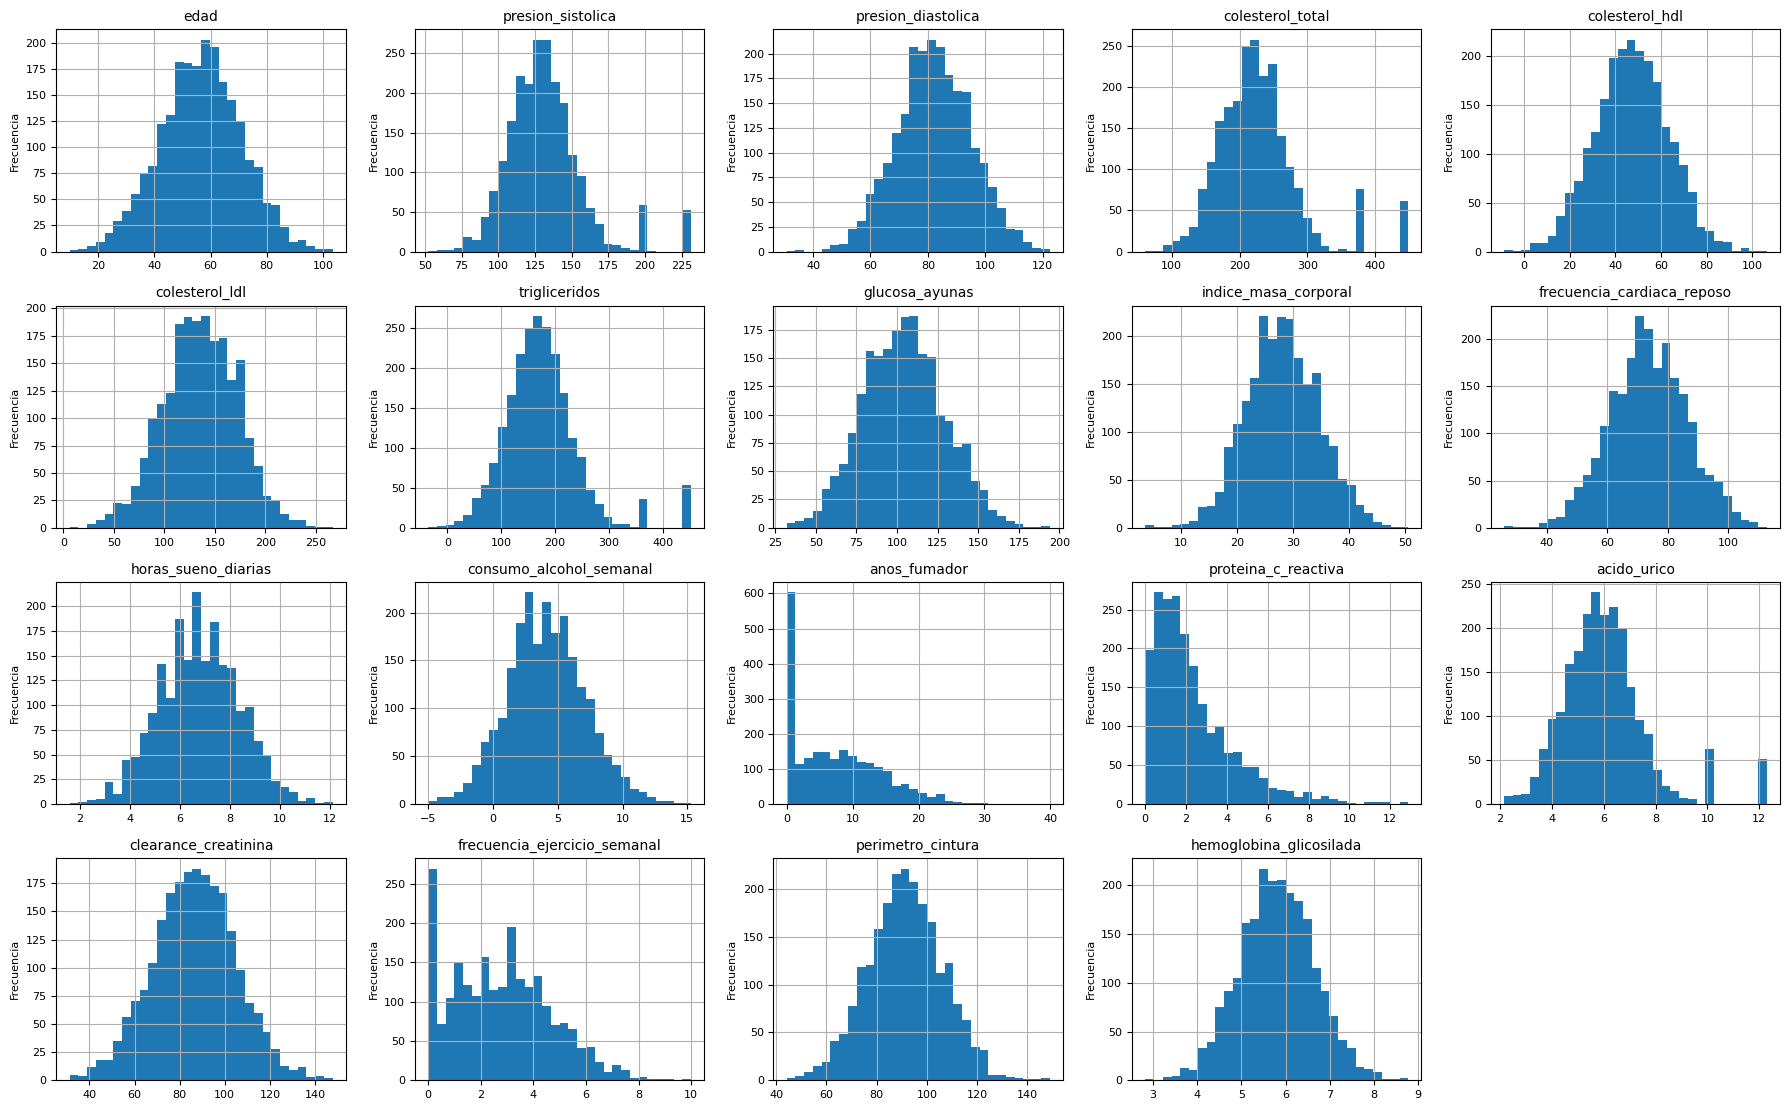

In [10]:
# Configuración de la cuadrícula
n_columnas = 5
n_filas = math.ceil(len(COLS_NUMERICAS) / n_columnas)

fig, axes = plt.subplots(
    nrows=n_filas,
    ncols=n_columnas,
    figsize=(18, n_filas * 2.8)
)

# Aplanar la matriz de ejes para recorrerla fácilmente
axes = axes.flatten()

# Generar los histogramas
for i, col in enumerate(COLS_NUMERICAS):
    df[col].hist(bins=30, ax=axes[i])

    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frecuencia", fontsize=8)
    axes[i].tick_params(labelsize=8)

# Ocultar los gráficos vacíos
for ax in axes[len(COLS_NUMERICAS):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

A partir de la visualización de los histogramas, podemos indicar:

- La mayoría muestran una forma acampanada y simétrica: edad, presion_sistolica, presion_diastolica, colesterol_total, colesterol_hdl, colesterol_ldl, trigliceridos, glucosa_ayunas, indice_masa_corporal, frecuencia_cardiaca_reposo, horas_sueno_diarias, consumo_alcohol_semanal, acido_urico, clearance_creatinina, perimetro_cintura y hemoglobina_glicosilada.
- Cuatro de ellas (`presion_sistolica`, `colesterol_total`, `trigliceridos` y `acido_urico`) presentan además **picos aislados en la cola derecha**, separados de la masa principal de la distribución. Se analizan en el apartado 3.6.5.
- Se observa **asimetría hacia la derecha** en `anos_fumador`, `frecuencia_ejercicio_semanal` y `proteina_c_reactiva`, donde la gran mayoría de los registros se concentran en valores bajos (o cero) y existe una cola larga hacia la derecha. Es marcada en `proteina_c_reactiva` (asimetría de 1,59) y moderada en `anos_fumador` (0,72) y `frecuencia_ejercicio_semanal` (0,39).

También podemos observar que hay diferencias en las magnitudes y rangos de las variables, lo que invita a aplicar un proceso de normalización o estandarización más adelante.

Además, hay variables con valores extremos o repetidos en sus extremos que deben ser evaluados para determinar si son errores.

Calculamos para cada variable numérica, sus valores más frecuentes.

In [11]:
for col in COLS_NUMERICAS:
    print(col, df[col].nunique(), df[col].value_counts().head(5).to_dict())

edad 607 {60.9: 12, 69.4: 12, 59.2: 11, 54.9: 11, 56.7: 11}
presion_sistolica 755 {196.95: 59, 231.36: 53, 133.7: 10, 129.8: 9, 122.6: 9}
presion_diastolica 571 {80.0: 12, 78.6: 12, 84.9: 12, 94.4: 12, 73.9: 11}
colesterol_total 1223 {371.24: 74, 448.59: 61, 242.2: 8, 247.6: 7, 195.0: 7}
colesterol_hdl 657 {46.3: 14, 48.8: 13, 44.8: 11, 51.6: 11, 47.9: 11}
colesterol_ldl 1105 {136.6: 7, 125.0: 7, 144.5: 6, 142.1: 6, 121.0: 6}
trigliceridos 1351 {452.7: 54, 357.56: 36, 177.6: 6, 170.2: 6, 189.2: 6}
glucosa_ayunas 872 {83.2: 9, 88.2: 9, 118.1: 8, 102.6: 8, 122.5: 8}
indice_masa_corporal 319 {25.0: 22, 26.1: 20, 24.9: 20, 26.0: 19, 27.9: 19}
frecuencia_cardiaca_reposo 565 {74.8: 14, 72.6: 14, 69.8: 13, 71.2: 12, 67.3: 12}
horas_sueno_diarias 92 {6.8: 64, 6.7: 58, 6.2: 53, 6.0: 52, 7.6: 51}
consumo_alcohol_semanal 167 {2.6: 47, 2.4: 43, 2.9: 37, 4.9: 36, 3.7: 36}
anos_fumador 260 {0.0: 503, 12.2: 17, 6.5: 17, 9.2: 16, 10.1: 16}
proteina_c_reactiva 619 {1.35: 13, 1.79: 13, 1.17: 12, 0.7: 11

De este cálculo llaman la atención varias variables ya vistas en la visualización de las distribuciones, por tener valores que se repiten mucho:

- `presion_sistolica` tiene 755 valores distintos en 2254 registros (cada valor debería aparecer, de media, unas 3 veces). El primero (196.95) y el segundo valor (231.36, que además es el máximo) más repetidos aparecen 59 y 53 veces. Los siguientes se repiten, como mucho, 10 veces. Además, esos dos valores tienen 2 decimales mientras el resto solo tiene uno.
- Se observa un comportamiento análogo en `colesterol_total` (371.24 y 448.59 aparecen 74 y 61 veces; el siguiente, 8) y en `trigliceridos` (452.7 y 357.56 aparecen 54 y 36 veces; el siguiente, 6). En `colesterol_total` los dos valores tienen 2 decimales y el resto de la columna uno; en `trigliceridos` solo 357.56 tiene 2 decimales.
- También tenemos el caso de `acido_urico`, donde los dos primeros (10.13 y 12.29) se repiten 61 y 51 veces (el siguiente, 16), aunque aquí el número de decimales no los distingue, porque la mayoría de los valores de la columna ya tiene 2.
- Por último, tenemos los casos de `anos_fumador` y `frecuencia_ejercicio_semanal`, donde el valor más repetido (0.0 en ambos, 503 y 204 veces) es mucho mayor que el resto, aunque en estos casos hay muchos menos valores distintos y tiene sentido que ese valor aparezca más que los demás (no fumar, no hacer ejercicio).

### 3.2 Estudio de las variables booleanas y nominales

Para las variables booleanas comprobamos que solo toman 0 y 1. Para el caso de las nominales que solo contienen las categorías del enunciado, sin espacios sobrantes, mayúsculas distintas ni errores ortográficos. 

In [12]:
print('VARIABLES BOOLEANAS')
for col in COLS_BOOLEANAS:
    valores = df[col].unique().tolist()
    print(f'  {col:24s} valores = {valores}, % de 1s = {df[col].mean() * 100:.1f} %')

print('\nVARIABLES NOMINALES')
for col in COLS_NOMINALES:
    obtenidas = set(df[col].dropna().unique())
    print(f'  {col}: categorías obtenidas = {obtenidas}')
    print('   ', df[col].value_counts()) #, f'{col / df[col].value_counts() * 100:.1f %}')

print('\nVARIABLE OBJETIVO, valores:', sorted(df[TARGET].unique().tolist()))

VARIABLES BOOLEANAS
  fumador_actual           valores = [1, 0], % de 1s = 26.4 %
  hipertension_previa      valores = [1, 0], % de 1s = 36.7 %
  diabetes_mellitus        valores = [1, 0], % de 1s = 22.8 %
  tratamiento_estatinas    valores = [0, 1], % de 1s = 27.2 %
  uso_antihipertensivos    valores = [1, 0], % de 1s = 34.9 %

VARIABLES NOMINALES
  tipo_alimentacion: categorías obtenidas = {'Baja en carbohidratos', 'Vegetariana', 'Occidental', 'Mediterránea'}
    tipo_alimentacion
Occidental               881
Mediterránea             706
Baja en carbohidratos    349
Vegetariana              318
Name: count, dtype: int64
  nivel_actividad: categorías obtenidas = {'Moderadamente activo', 'Muy activo', 'Sedentario', 'Ligeramente activo'}
    nivel_actividad
Ligeramente activo      695
Sedentario              687
Moderadamente activo    563
Muy activo              309
Name: count, dtype: int64
  antecedentes_familiares_tipo: categorías obtenidas = {'Ambos', 'Materno', 'Ninguno', 'Paterno

Los dominios coinciden con lo indicado en el enunciado: booleanas en {0, 1}, nominales con sus cuatro categorías exactas y sin ausentes, y variable objetivo en {0, 1, 2}. Destacar que algunas categorías no están equilibradas.

### 3.3 Registros duplicados

In [13]:
print('Filas duplicadas:', df.duplicated().sum())

Filas duplicadas: 0


No hay duplicados

### 3.4 Valores ausentes (*missing*)

Antes de tomar ninguna decisión sobre qué hacer con los valores ausentes, hay que saber cuántos son, cómo se reparten y si la ausencia aporta información.

In [14]:
COLS_CON_NULOS = df.columns[df.isna().any()].tolist()

tabla_nulos = pd.DataFrame({
    'ausentes': df[COLS_CON_NULOS].isna().sum(),
    'porcentaje (%)': (df[COLS_CON_NULOS].isna().mean() * 100).round(2),
}).sort_values('ausentes', ascending=False)
display(tabla_nulos)

,ausentes,porcentaje (%)
horas_sueno_diarias,180,7.99
proteina_c_reactiva,157,6.97
colesterol_ldl,135,5.99
glucosa_ayunas,112,4.97


Podemos observar los siguientes valores missing:

1. Para la variable colesterol_ldl, faltan 135 registros.
2. Para la variable glucosa_ayunas tenemos 112 nulos.
3. La variable horas_sueno_diarias tiene 180 nulos.
4. La variable proteina_c_reactiva tiene 157 nulos.

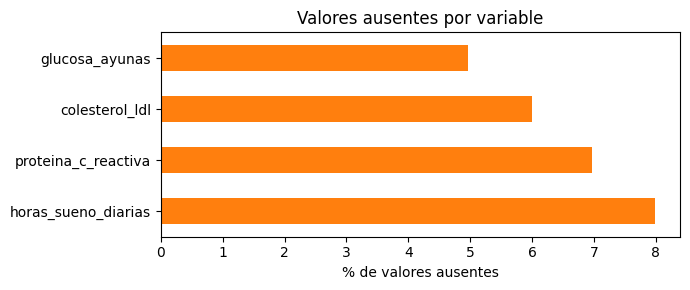

In [15]:
# Gráfico de barras con iformación de missing
fig, ax = plt.subplots(figsize=(7, 3))
tabla_nulos['porcentaje (%)'].plot.barh(ax=ax, color='tab:orange')
ax.set_xlabel('% de valores ausentes')
ax.set_title('Valores ausentes por variable')
plt.tight_layout()
plt.show()

Entre el 5 % y el 8 % de valores ausentes por variable. Parece un nivel bajo, lo que permite imputar.

La forma de tratar los ausentes depende de por qué faltan. Si faltan al azar, imputar no introduce sesgo. Si la ausencia depende de la clase o de otras variables, el propio hecho de faltar es información y convendría conservarlo (por ejemplo, con una variable indicadora). Lo comprobamos de tres formas: (1) porcentaje de ausentes por nivel de riesgo, con un contraste χ² de independencia; (2) si las ausencias de distintas variables coinciden en los mismos pacientes; (3) cuántos pacientes se perderían si se eliminaran las filas incompletas.

Para las variables que contienen tantos nulos, vamos a ver cómo se relacionan con la variable objetivo.

In [16]:
# El objetivo no debe tener ausentes: si los tuviera, hay que verlo.
assert df[TARGET].notna().all(), 'El objetivo tiene ausentes: revisar antes de continuar'

# Solo los predictores con ausentes (el objetivo queda fuera)
COLS_CON_NULOS = [c for c in df.columns if df[c].isna().any() and c != TARGET]

# (1) ¿La ausencia depende del nivel de riesgo?
filas = []
for col in COLS_CON_NULOS:
    falta = df[col].isna()
    pct_por_clase = falta.groupby(df[TARGET]).mean() * 100
    _, p_valor, _, _ = stats.chi2_contingency(pd.crosstab(falta, df[TARGET]))
    filas.append({
        'variable': col,
        '% ausentes riesgo 0': pct_por_clase[0],
        '% ausentes riesgo 1': pct_por_clase[1],
        '% ausentes riesgo 2': pct_por_clase[2],
        'p-valor (chi2)': p_valor,
    })
display(pd.DataFrame(filas).set_index('variable').round(3))

# (2) ¿Las ausencias coinciden en los mismos pacientes?
print('Correlación entre los indicadores de ausencia:')
display(df[COLS_CON_NULOS].isna().astype(int).corr().round(2))

# (3) ¿Cuántos pacientes tienen algún ausente?
nulos_por_fila = df[COLS_CON_NULOS].isna().sum(axis=1)
print('Pacientes según su número de ausentes:', nulos_por_fila.value_counts().sort_index().to_dict())
print(f'Pacientes con al menos un ausente: {(nulos_por_fila > 0).sum()} '
      f'({(nulos_por_fila > 0).mean() * 100:.1f} %)')
esperados_completos = np.prod(1 - df[COLS_CON_NULOS].isna().mean()) * len(df)
print(f'Pacientes completos: {(nulos_por_fila == 0).sum()} observados '
      f'frente a {esperados_completos:.0f} esperados si las ausencias fueran independientes')

,% ausentes riesgo 0,% ausentes riesgo 1,% ausentes riesgo 2,p-valor (chi2)
variable,,,,
colesterol_ldl,6.389,6.065,4.878,0.518
glucosa_ayunas,4.437,4.586,6.874,0.114
horas_sueno_diarias,8.252,7.692,7.761,0.896
proteina_c_reactiva,8.163,5.769,5.765,0.082


Correlación entre los indicadores de ausencia:


,colesterol_ldl,glucosa_ayunas,horas_sueno_diarias,proteina_c_reactiva
colesterol_ldl,1.00,-0.02,-0.03,0.03
glucosa_ayunas,-0.02,1.00,0.02,-0.01
horas_sueno_diarias,-0.03,0.02,1.00,-0.00
proteina_c_reactiva,0.03,-0.01,-0.00,1.00


Pacientes según su número de ausentes: {0: 1721, 1: 484, 2: 47, 3: 2}
Pacientes con al menos un ausente: 533 (23.6 %)
Pacientes completos: 1721 observados frente a 1724 esperados si las ausencias fueran independientes


- El porcentaje de ausentes es parecido en las tres clases de riesgo y ningún contraste χ² es significativo al 5 % (p entre 0,082 y 0,896). Las variables más cercanas a la significación son `proteina_c_reactiva` (8,2 % en riesgo bajo frente a 5,8 % en las otras dos; p = 0,082) y `glucosa_ayunas` (6,9 % en riesgo alto frente a 4,4–4,6 % en las otras dos; p = 0,114). Con cuatro contrastes, diferencias de este tamaño son compatibles con el azar.
- La correlación entre indicadores de ausencia es prácticamente nula (|r| ≤ 0,03) y hay 1.721 pacientes completos, casi exactamente los 1.724 que se esperarían si cada variable perdiera datos de forma independiente. Las ausencias no se agrupan.
- Aunque cada variable pierde solo entre el 5 % y el 8 %, las ausencias caen en pacientes distintos: 533 pacientes (23,6 %) tienen al menos un ausente. Eliminar esas filas supondría perder casi una cuarta parte del dataset.

Todo es compatible con un mecanismo MCAR: los contrastes no aportan evidencia de que la ausencia dependa del riesgo ni de otras ausencias (no se puede demostrar, solo no encontrar indicios en contra). 

Conclusión: se imputará en lugar de eliminar filas, y no hay indicios de que haga falta una variable indicadora de ausencia. El método de imputación (mediana, k-NN...) se decidirá posteriormente, solo con los datos de entrenamiento.

### 3.5 Validación automática con reglas

Para auditar el dataset de forma sistemática usamos `src/validador_datos_cardiovasculares_v1.py`, que implementa  tres niveles del estudio de validación. **No modificamos el DataFrame**: devuelve una tabla con cada incidencia (fila, variable, valor, gravedad, regla) y un resumen por regla.

Las gravedades son `ERROR` (imposible o inconsistente) y `REVISION` (posible pero sospechoso). Varias reglas del validador todavía **no están decididas** (por ejemplo, que la edad con decimales sea un error). Aquí se ejecuta tal cual para ver qué detecta.

In [17]:
# Validador (antes de las decisiones del EDA)
from src.validador_datos_cardiovasculares_v1 import validar_datos_cardiovasculares

incidencias, resumen_incidencias = validar_datos_cardiovasculares(df)

filas_error = incidencias.loc[incidencias['gravedad'] == 'ERROR', 'posicion'].nunique()
print(f'Incidencias totales: {len(incidencias)}')
print(f'Filas con al menos un ERROR: {filas_error} de {len(df)}')
resumen_incidencias


# Ruta de archivos de validacion
RUTA_VALIDACION = RAIZ / 'reports' / 'generated'
RUTA_VALIDACION.mkdir(parents=True, exist_ok=True)


# Guarda la tabla de incidencias y el resumen de una ejecución del validador
incidencias.to_csv(
    RUTA_VALIDACION / 'incidencias_validacion.csv', 
    index=False,
    encoding="utf-8-sig",
)
resumen_incidencias.to_csv(
    RUTA_VALIDACION / 'resumen_validacion.csv', 
    index=False,
    encoding="utf-8-sig",
)
print(f'Guardado en {RUTA_VALIDACION.relative_to(RAIZ)}: '
          f'incidencias_validacion.csv ({len(incidencias)} filas), resumen_validacion.csv')

Incidencias totales: 5347
Filas con al menos un ERROR: 2224 de 2254
Guardado en reports\generated: incidencias_validacion.csv (5347 filas), resumen_validacion.csv


Según el validador, **2.224 de los 2.254 pacientes (98,7 %) tienen algún error**. Es un porcentaje demasiado alto. Hay que revisar los resultados:

- **`EDAD_NO_ENTERA` (2.046) y `EJERCICIO_NO_ENTERO` (1.836).** Casi todos los valores de esas columnas tienen decimales. Cuando mas del 90 % de valores incumple una regla de formato, lo más probable es que la regla de formao no se ajuste a cómo se registró la variable. Lo contrario, que mas del 90 % sean errores, tiene poco sentido.
- **`SUEÑO_FUERA_RANGO` (180): es un falso positivo del validador.** Ningún valor de sueño está fuera de 0–24 h. Lo que ocurre es que esas incidencias son exactamente los 180 **ausentes** de la variable que hemos detectado anteriormente. 
- **`VALOR_NEGATIVO` (185):** 4 en HDL, 4 en triglicéridos y **177 en alcohol**.
- **Relaciones cruzadas:** 44 presiones con sistólica ≤ diastólica, 140 LDL mayores que el colesterol total y 559 LDL mayores que el colesterol no HDL.
- **`VALOR_CLINICO_EXTREMO` (188):** marcados para revisión, no son errores. Se tendrían que revisar caso a caso.

Actualizamos el validador con `src/validador_datos_cardiovasculares_v3.py`. Respecto a la versión anterior:

- **Detecta más tipos de problema:** valores inválidos por definición (`INVALIDO`), inconsistencias entre variables (`INCONSISTENCIA`), valores extremos (`EXTREMO`), alertas clínicas (`ALERTA_CLINICA`) y los valores repetidos de 3.6.5 (`ARTEFACTO`).
- **Cada incidencia lleva una columna `decision`** con el tratamiento previsto en el apartado 4: `corregir` (la limpieza la elimina), `conservar` (se mantiene a propósito y se registra) o `revision` (aviso informativo, no se modifica).
- **Los valores ausentes y los decimales de edad y ejercicio no cuentan como incidencias** por defecto (parámetros `incluir_ausentes` y `exigir_enteros`), porque son decisiones ya tomadas.
- **Los límites** se definen en `src/reglas_datos.py`, el mismo fichero que usará la limpieza del apartado 5.

Una incidencia no es un paciente: una misma celda puede incumplir dos reglas (por ejemplo, los 177 alcoholes negativos aparecen como `INVALIDO` y como `EXTREMO`), así que el total de incidencias supera al número de celdas afectadas. Por eso se muestra también el número de registros.

In [18]:
# Validador v3: auditoría de los datos originales (antes de las decisiones del EDA)
from src.validador_datos_cardiovasculares_v3 import validar_datos_cardiovasculares

# Ruta de archivos de validacion
RUTA_VALIDACION = RAIZ / 'reports' / 'generated'
RUTA_VALIDACION.mkdir(parents=True, exist_ok=True)

def auditar_datos(df, etiqueta, guardar=True, **kwargs):
    """Ejecuta el validador, muestra el resumen y guarda los CSV.

    etiqueta : sufijo de los ficheros (p. ej. 'v3_original', 'v3_limpio').
    kwargs   : se pasan al validador (exigir_enteros, incluir_ausentes).
    """
    incidencias, resumen = validar_datos_cardiovasculares(df, **kwargs)
    
    registros_afectados = incidencias['indice'].dropna().nunique()

    registros_corregir = (
        incidencias.loc[
            incidencias['decision'] == 'corregir',
            'indice'
        ]
        .nunique()
    )

    print(f"=== {etiqueta}: {len(df)} registros ===")
    print(f"Incidencias detectadas: {len(incidencias)}")
    print(f"Registros afectados: {registros_afectados}")
    print(f"Registros que requieren corrección: {registros_corregir}")

    if incidencias.empty:
        print("\nNo se han detectado incidencias.")
    else:
        print("\nPor decisión prevista:")
        display(
            incidencias.groupby('decision')
                       .size()
                       .rename('incidencias')
                       .to_frame()
        )

    print("\nResumen por variable y regla:")
    display(resumen)
    if guardar:
        for nombre, tabla in [
            ('incidencias', incidencias),
            ('resumen', resumen)
        ]:
            tabla.to_csv(
                RUTA_VALIDACION / f'{nombre}_validacion_{etiqueta}.csv',
                index=False,
                encoding='utf-8-sig'
            )

        print(
            f"\nGuardado en {RUTA_VALIDACION.relative_to(RAIZ)}: "
            f"incidencias_validacion_{etiqueta}.csv "
            f"({len(incidencias)} filas) y "
            f"resumen_validacion_{etiqueta}.csv"
        )

    return incidencias, resumen


incidencias, resumen = auditar_datos(df, 'v3_original')

display(incidencias.head(10))

=== v3_original: 2254 registros ===
Incidencias detectadas: 1888
Registros afectados: 1124
Registros que requieren corrección: 638

Por decisión prevista:


,incidencias
decision,
conservar,699
corregir,734
revision,455



Resumen por variable y regla:


,variable,tipo,regla,decision,casos
0,colesterol_ldl,INCONSISTENCIA,LDL > colesterol no-HDL,conservar,559
1,consumo_alcohol_semanal,EXTREMO,Inferior al límite de plausibilidad,revision,177
2,consumo_alcohol_semanal,INVALIDO,Valor negativo,corregir,177
3,colesterol_ldl,INCONSISTENCIA,LDL > colesterol total,conservar,140
4,colesterol_total,ARTEFACTO,Valor repetido anómalo,corregir,135
5,presion_sistolica,ALERTA_CLINICA,Sistólica > 180 mmHg,revision,121
6,acido_urico,ARTEFACTO,Valor repetido anómalo,corregir,112
7,presion_sistolica,ARTEFACTO,Valor repetido anómalo,corregir,112
8,trigliceridos,ARTEFACTO,Valor repetido anómalo,corregir,90
9,presion_sistolica,INCONSISTENCIA,Sistólica <= diastólica,corregir,44



Guardado en reports\generated: incidencias_validacion_v3_original.csv (1888 filas) y resumen_validacion_v3_original.csv


,indice,variable,valor,tipo,regla,decision,detalle
0,85,colesterol_hdl,-7.5,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
1,900,colesterol_hdl,-8.8,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
2,1231,colesterol_hdl,-0.3,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
3,1679,colesterol_hdl,-3.7,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
4,173,trigliceridos,-12.0,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
5,1849,trigliceridos,-35.7,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
6,2191,trigliceridos,-3.1,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
7,2224,trigliceridos,-8.7,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
8,4,consumo_alcohol_semanal,-4.9,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.
9,13,consumo_alcohol_semanal,-0.2,INVALIDO,Valor negativo,corregir,La variable no admite valores negativos.


### 3.6 Análisis detallado de anomalías

#### 3.6.1 Valores negativos
Las variables 'colesterol_hdl', 'trigliceridos' y 'consumo_alcohol_semanal' tienen valores negativos. Hay que ver si son errores de captura o nulos camuflados.

In [19]:
print('Análisis de variables negativas:')
for col in ['colesterol_hdl', 'trigliceridos', 'consumo_alcohol_semanal']:
    negativos = df.loc[df[col] < 0, col]
    print(f'{col}: {len(negativos)} negativos ({len(negativos) / len(df) * 100:.1f} %)'
          f' | mín = {negativos.min()} ')

Análisis de variables negativas:
colesterol_hdl: 4 negativos (0.2 %) | mín = -8.8 
trigliceridos: 4 negativos (0.2 %) | mín = -35.7 
consumo_alcohol_semanal: 177 negativos (7.9 %) | mín = -5.0 


De lo anteior podems indicar que:
- colesterol_hdl y triglicéridos: Son pocos casos (4 y 4) y aislados (0,2 % en ambos). Se comportan como errores puntuales de captura.
- La variable consumo_alcohol_semanal tiene muchos casos (177) siendo un 7,9 %. No parecen errores al azar.

Estudiamos los datos de consumo semanal de alcohol.

In [20]:
# Consumo semanal de alcohol
alcohol = pd.to_numeric(
    df['consumo_alcohol_semanal'],
    errors='coerce'
)

# Definición de intervalos
cortes = [-np.inf, 0, 2, 4, 6, np.inf]
etiquetas = ['negativo', '0 a <2', '2 a <4', '4 a <6', '6 o más']

# Clasificación por intervalos
tramo = pd.cut(
    alcohol,
    bins=cortes,
    labels=etiquetas,
    right=False
)

# Crear subconjunto con consumo y clase de riesgo conocidos
base = pd.DataFrame({
    'tramo': tramo,
    TARGET: df[TARGET]
}).dropna()

# Número de pacientes por intervalo
pacientes = (
    base['tramo']
    .value_counts()
    .reindex(etiquetas, fill_value=0)
)

# Número de pacientes de cada clase de riesgo
conteos_riesgo = pd.crosstab(
    base['tramo'],
    base[TARGET]
).reindex(
    index=etiquetas,
    columns=[0, 1, 2],
    fill_value=0
)

# Porcentajes dentro de cada intervalo
porcentajes = (
    conteos_riesgo
    .div(conteos_riesgo.sum(axis=1).replace(0, np.nan), axis=0)
    * 100
)

# Tabla final
tabla_alcohol = pd.DataFrame({
    'Pacientes': pacientes,
    '% riesgo bajo': porcentajes[0],
    '% riesgo moderado': porcentajes[1],
    '% riesgo alto': porcentajes[2]
})

tabla_alcohol.index.name = 'Consumo semanal (UBE)'

tabla_alcohol

,Pacientes,% riesgo bajo,% riesgo moderado,% riesgo alto
Consumo semanal (UBE),,,,
negativo,177,82.485876,15.819209,1.694915
0 a <2,330,71.818182,22.424242,5.757576
2 a <4,600,54.666667,32.000000,13.333333
4 a <6,553,46.473779,33.453888,20.072333
6 o más,594,26.767677,33.164983,40.067340


Con los datos negativos de consumo_alcohol_semanal podemos:
- Convertirlos en `NaN` e imputar con la media o la mediana asignaría un consumo moderado a 177 pacientes que presentan mayoritariamente un bajo riesgo.
- Recortarlos a 0 (es decir, asignarlos al grupo que no consume alcohol) conserva el sentido clínico.

Hay que decidir si convertir valores negativos de consumo_alcohol_semanal en `NaN` o recortarlos a 0.

#### 3.6.2 Valores positivos pero fisiológicamente imposibles o muy improbables

Para diferenciar entre valores imposibles o muy improbables habría que contar con la opinión de un experto del campo. De entre todos los valores extremos, con nuestro conocimiento, solo pondríamos los siguientes límites de corte entre extremo raro e imposible:
- indice_masa_corporal o IMC: presenta valores que no corresponden a ningún adulto vivo. Aunque no existe un mínimo absoluto universal establecido por la OMS, los valores menores de 10 son extremadamente bajos y podrían considerarse errores.
- frecuencia_cardiaca_reposo: Valores de menos de 30 lpm en reposo se pueden considerar Bradicardia extrema y requieren atención urgente. Aunque podrían ser reales, son tan poco probables en un estudio como el del proyecto que podríamos considerarlos valores imposibles.
- perimetro_cintura:  Valores de menos de 40 cm son extremadamente pequeños para un adulto.

In [21]:
# Umbrales
UMBRALES_FISIOLOGICOS = {
    'indice_masa_corporal': 10,
    'frecuencia_cardiaca_reposo': 30,
    'perimetro_cintura': 40,
}

filas = []
for col, umbral in UMBRALES_FISIOLOGICOS.items():
    bajo = df[col] < umbral
    filas.append({
        'variable': col,
        'umbral de revisión': umbral,
        'num por debajo': int(bajo.sum()),
        'num negativos': int((df[col] < 0).sum()),
        'valores más bajos': df[col].nsmallest(5).round(1).tolist(),
    })
pd.DataFrame(filas)

,variable,umbral de revisión,num por debajo,num negativos,valores más bajos
0,indice_masa_corporal,10,8,0,"[3.6, 4.9, 5.1, 6.4, 8.2]"
1,frecuencia_cardiaca_reposo,30,2,0,"[25.8, 26.6, 30.7, 32.6, 34.5]"
2,perimetro_cintura,40,0,0,"[44.2, 46.1, 48.0, 48.7, 48.8]"


Utilizaremos IMC < 10 y FC < 30 como límites operativos de plausibilidad extrema. Entre nuestros datos de perimetro_cintura no hay valores < 40.

### 3.6.3 Edad y frecuencia_ejercicio_semanal con decimales

La edad parece estar registrada como variable continua, no en años cumplidos como dice el enunciado. Marcar 2046 registros como erróneos no tiene sentido. Hay que decidir es si se acepta como continua o se trunca a años cumplidos.

Algo parecido sucede con frecuencia_ejercicio_semanal, donde 1836 valores (81 %) indican el número de días como variable continua. Podría interpretarse como días por semana en promedio, y en ese caso los decimales tienen sentido.

### 3.6.4 Frecuencia_ejercicio_semanal con valores 0 y mayores que 7

Análisis de Frecuencia_ejercicio_semanal:
Valores > 7: 41  ->  [7.1, 7.1, 7.1, 7.1, 7.1, 7.1, 7.1, 7.1, 7.2, 7.2, 7.2, 7.2, 7.2, 7.3, 7.3, 7.4, 7.4, 7.4, 7.4, 7.4, 7.5, 7.5, 7.5, 7.5, 7.5, 7.6, 7.6, 7.6, 7.8, 7.9, 7.9, 8.1, 8.1, 8.3, 8.3, 8.4, 8.5, 8.8, 9.0, 9.7, 10.0]
Valores = 0: 204


C:\Users\Kanenas\AppData\Local\Temp\ipykernel_15376\484872593.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


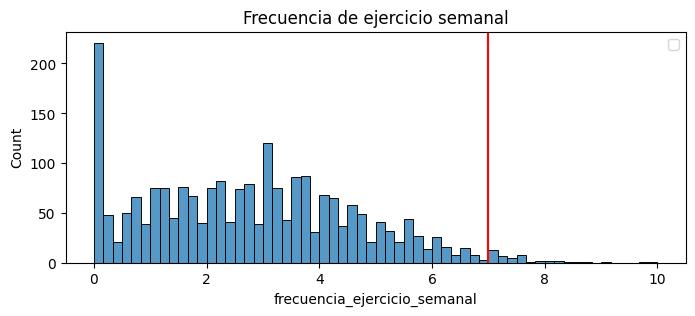

In [22]:
print('Análisis de Frecuencia_ejercicio_semanal:')
ejercicio = df['frecuencia_ejercicio_semanal']
print(f'Valores > 7: {(ejercicio > 7).sum()}  ->  {sorted(ejercicio[ejercicio > 7].tolist())}')
print(f'Valores = 0: {(ejercicio == 0).sum()}')

fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(ejercicio, bins=60, ax=ax)
ax.axvline(7, color='red')
ax.set_title('Frecuencia de ejercicio semanal')
ax.legend()
plt.show()

- 41 valores superan los 7 días de la semana. De ellos, la mayoría están entre 7,1 y 7,9.
- Hay un pico de 204 ceros al principio del histograma. Aquí el cero parece un valor válido y con sentido (no hace ejercicio).

#### 3.6.5 Valores repetidos en el extremo superior

Las variables `presion_sistolica`, `colesterol_total`, `trigliceridos` y `acido_urico` presentan, cada una, **dos valores que se repiten decenas de veces** (entre 36 y 74), mientras que ningún otro valor de esas columnas pasa de 16 repeticiones. Para decidir si son valores reales o introducidos por algún procedimiento comprobamos cuatro cosas: (1) cómo se ven en el histograma y dónde caen respecto al resto de la distribución; (2) si su nivel de riesgo difiere del general; (3) si los pacientes afectados se parecen al resto en las demás variables; (4) si tienen un formato distinto (número de decimales).

Los valores repetidos son los que aparecen más de 20 veces en cada una de estas cuatro variables.

{'presion_sistolica': [196.95, 231.36], 'colesterol_total': [371.24, 448.59], 'trigliceridos': [357.56, 452.7], 'acido_urico': [10.13, 12.29]}


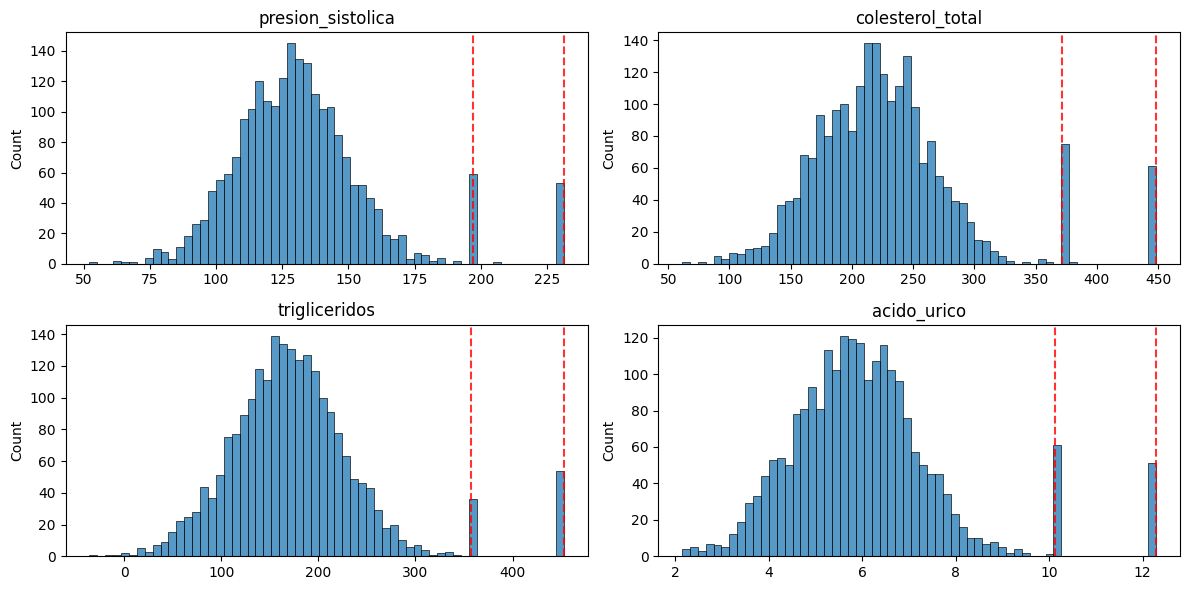

In [23]:
COLS_REPETIDOS = ['presion_sistolica', 'colesterol_total', 'trigliceridos', 'acido_urico']

# Mismo criterio que el análisis visual: valores que aparecen más de 20 veces
VALORES_REPETIDOS = {
    col: sorted(df[col].value_counts().loc[lambda x: x > 20].index)
    for col in COLS_REPETIDOS
}
print(VALORES_REPETIDOS)

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (col, valores) in zip(axes.flatten(), VALORES_REPETIDOS.items()):
    sns.histplot(df[col], bins=60, ax=ax)
    for valor in valores:
        ax.axvline(valor, color='red', ls='--', alpha=0.8)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

Las cuatro variables tienen una forma simétrica con dos picos aislados en la cola derecha (líneas rojas), separados de la masa principal de la distribución. Una población real no produce picos así: el resto de valores de cada columna se repite como mucho 16 veces, y las colas deberían descender de forma gradual, sin saltos.

In [24]:
def mas_de_un_decimal(valores):
    valores = np.asarray(valores, dtype=float)
    return ~np.isclose(valores * 10, np.round(valores * 10))

filas = []
for col, valores in VALORES_REPETIDOS.items():
    es_repetido = df[col].isin(valores)
    resto = df.loc[~es_repetido, col]
    # ¿El nivel de riesgo de estos pacientes difiere del de los demás?
    _, p_valor, _, _ = stats.chi2_contingency(pd.crosstab(es_repetido, df[TARGET]))
    for valor in valores:
        filas.append({
            'variable': col,
            'valor': valor,
            'veces': int((df[col] == valor).sum()),
            'máx. del resto': resto.max(),
            'z respecto al resto': (valor - resto.mean()) / resto.std(),
            'decimales (1 o 2)': 2 if mas_de_un_decimal([valor])[0] else 1,
            '% del resto con 2 decimales': mas_de_un_decimal(resto).mean() * 100,
            '% riesgo alto': (df.loc[df[col] == valor, TARGET] == 2).mean() * 100,
            'p-valor riesgo (chi2)': p_valor,
        })
display(pd.DataFrame(filas).round(2))

afectadas = pd.concat([df[c].isin(v) for c, v in VALORES_REPETIDOS.items()], axis=1)
print(f'Filas con al menos un valor repetido: {afectadas.any(axis=1).sum()} '
      f'({afectadas.any(axis=1).mean() * 100:.1f} %)')
print('Filas según cuántas variables afectadas tienen:',
      afectadas.sum(axis=1).value_counts().sort_index().to_dict())
print(f'% de riesgo alto en todo el dataset: {(df[TARGET] == 2).mean() * 100:.1f} %')

# Asimetría con y sin esos valores
asimetria = pd.DataFrame({
    'asimetría con ellos': {c: df[c].skew() for c in VALORES_REPETIDOS},
    'asimetría sin ellos': {c: df.loc[~df[c].isin(v), c].skew() for c, v in VALORES_REPETIDOS.items()},
})
display(asimetria.round(2))

# ¿Se parecen al resto de pacientes en las demás variables?
afectada = afectadas.any(axis=1)
otras = [c for c in COLS_NUMERICAS if c not in VALORES_REPETIDOS]

def dif_estandarizada(col):
    a, b = df.loc[afectada, col].dropna(), df.loc[~afectada, col].dropna()
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

dif = pd.Series({c: dif_estandarizada(c) for c in otras})
print(f'Mayor diferencia estandarizada en las otras {len(otras)} variables numéricas: '
      f'{dif.abs().max():.2f} ({dif.abs().idxmax()})')

,variable,valor,veces,máx. del resto,z respecto al resto,decimales (1 o 2),% del resto con 2 decimales,% riesgo alto,p-valor riesgo (chi2)
0,presion_sistolica,196.95,59,204.60,3.50,2,0.0,18.64,0.82
1,presion_sistolica,231.36,53,204.60,5.25,2,0.0,26.42,0.82
2,colesterol_total,371.24,74,378.90,3.51,2,0.0,18.92,0.71
3,colesterol_total,448.59,61,378.90,5.26,2,0.0,19.67,0.71
4,trigliceridos,357.56,36,344.00,3.50,2,0.0,11.11,0.30
5,trigliceridos,452.70,54,344.00,5.25,1,0.0,18.52,0.30
6,acido_urico,10.13,61,9.94,3.51,2,90.1,13.11,0.62
7,acido_urico,12.29,51,9.94,5.26,2,90.1,25.49,0.62


Filas con al menos un valor repetido: 420 (18.6 %)
Filas según cuántas variables afectadas tienen: {0: 1834, 1: 391, 2: 29}
% de riesgo alto en todo el dataset: 20.0 %


,asimetría con ellos,asimetría sin ellos
presion_sistolica,1.29,-0.00
colesterol_total,1.29,-0.05
trigliceridos,1.32,-0.05
acido_urico,1.28,-0.00


Mayor diferencia estandarizada en las otras 15 variables numéricas: 0.09 (indice_masa_corporal)


Resultados de la tabla:

- Misma posición relativa en las cuatro variables. Los dos valores repetidos están a 3,5 y 5,25 desviaciones típicas de la media del resto de la variable (3,50–3,51 y 5,25–5,26). Que cuatro magnitudes clínicas distintas, con unidades y rangos muy diferentes, coincidan en la misma posición relativa no puede ser casualidad: es la huella de un procedimiento automático.
- No es un recorte en el máximo (*top-coding*). En `presion_sistolica` y `colesterol_total` hay valores reales por encima del primer valor repetido (204,6 frente a 196,95 y 378,9 frente a 371,24), y un recorte dejaría un único pico, no dos.
- No se relacionan con el riesgo. Los pacientes afectados tienen un reparto de clases parecido al del resto (p entre 0,30 y 0,82). Si fueran pacientes reales con valores extremos cabría esperar más riesgo alto, y no se observa. Con 36–74 pacientes por valor la potencia del contraste es limitada, por lo que este es un argumento de apoyo y no el principal.
- Se parecen al resto en las demás variables. La mayor diferencia estandarizada en las otras 15 variables numéricas es 0,09 (IMC), por debajo del 0,1 que suele considerarse despreciable. Los pacientes afectados son un subconjunto sin rasgos propios.
- Afectan a 420 pacientes (18,6 %), casi siempre en una sola variable (391) y en dos variables en 29 casos.
- Distorsionan la forma de las distribuciones. Con ellos, las cuatro variables parecen asimétricas (asimetría ≈ 1,3); sin ellos son simétricas (≈ 0).
- El número de decimales solo delata a algunas. En `presion_sistolica` y `colesterol_total`, los dos valores tienen 2 decimales y ningún otro valor de la columna. En `trigliceridos` solo 357,56 tiene 2 decimales (452,7 tiene uno) y en `acido_urico` el 90 % de los valores ya tiene 2, por lo que no distingue nada.

**Conclusión:** son valores artificiales que sustituyen al dato real, que desconocemos. Aportan ruido y una falsa asimetría, y no corresponden a pacientes con valores extremos reales. Lo coherente es tratarlos como datos ausentes y no conservarlos como si fueran mediciones.

#### 3.6.6 Coherencia entre variables

Hay valores posibles por separado que juntos son incompatibles. Se revisan las relaciones que propone el estudio de validación.

**Presión arterial: la sistólica debe ser mayor que la diastólica.**

In [25]:
pas, pad = df['presion_sistolica'], df['presion_diastolica']
incoherente = pas <= pad
print(f'Pacientes con sistólica <= diastólica: {incoherente.sum()} ({incoherente.mean() * 100:.1f} %)')
df.loc[incoherente, ['presion_sistolica', 'presion_diastolica']].describe().round(1).T

Pacientes con sistólica <= diastólica: 44 (2.0 %)


,count,mean,std,min,25%,50%,75%,max
presion_sistolica,44.0,87.9,14.0,52.2,78.4,89.4,97.5,116.5
presion_diastolica,44.0,98.3,12.5,74.9,88.7,97.4,107.7,122.5


44 pacientes (2 %) tienen la sistólica igual o menor que la diastólica (43 con la diastólica mayor y 1 con ambas iguales), lo que es fisiológicamente imposible.

**Lípidos: el LDL forma parte del colesterol total.** 

Por la fórmula de Friedewald, el colesterol total es aproximadamente igual a HDL + LDL + triglicéridos/5, así que el LDL no puede superar al total. Para valorar el número de incoherencias las comparamos con las que aparecerían simplemente por azar si las dos variables no tuvieran ninguna relación (para ello, barajamos una de ellas).

In [26]:
rng = np.random.default_rng(SEMILLA)

def incoherencias_esperadas(mayor, menor, n_permutaciones=500):
    # Número medio de casos con menor > mayor si ambas columnas fueran independientes
    validas = mayor.notna() & menor.notna()
    a, b = mayor[validas].to_numpy(), menor[validas].to_numpy()
    return np.mean([(rng.permutation(b) > a).sum() for _ in range(n_permutaciones)])

pares = {
    'LDL > colesterol total': ('colesterol_total', 'colesterol_ldl'),
    'Diastólica > sistólica': ('presion_sistolica', 'presion_diastolica'),
}
filas = []
for regla, (col_mayor, col_menor) in pares.items():
    filas.append({
        'regla': regla,
        'observadas': int((df[col_menor] > df[col_mayor]).sum()),
        'esperadas por azar': incoherencias_esperadas(df[col_mayor], df[col_menor]),
        'correlación de Spearman': df[col_mayor].corr(df[col_menor], method='spearman'),
    })
display(pd.DataFrame(filas).set_index('regla').round(2))

# ¿Qué valores se perderían con cada regla?
ldl_incoherente = df['colesterol_ldl'] > df['colesterol_total']
print(f"LDL medio en los incoherentes: {df.loc[ldl_incoherente, 'colesterol_ldl'].mean():.1f} "
      f"(global: {df['colesterol_ldl'].mean():.1f})")
print(f"Colesterol total medio en los incoherentes: {df.loc[ldl_incoherente, 'colesterol_total'].mean():.1f} "
      f"(global: {df['colesterol_total'].mean():.1f})")

friedewald = df['colesterol_hdl'] + df['colesterol_ldl'] + df['trigliceridos'] / 5
print(f"Correlación entre colesterol total y HDL + LDL + TG/5: "
      f"{df['colesterol_total'].corr(friedewald, method='spearman'):.2f}")

,observadas,esperadas por azar,correlación de Spearman
regla,,,
LDL > colesterol total,140,155.71,0.03
Diastólica > sistólica,43,54.76,0.01


LDL medio en los incoherentes: 180.2 (global: 135.6)
Colesterol total medio en los incoherentes: 154.2 (global: 228.1)
Correlación entre colesterol total y HDL + LDL + TG/5: 0.03


In [27]:
# ¿Es el LDL registrado compatible con la fórmula de Friedewald? (válida con TG < 400 mg/dL)
COLS_LIPIDOS = ['colesterol_total', 'colesterol_hdl', 'colesterol_ldl', 'trigliceridos']

def comparar_friedewald(lipidos):
    """Compara el LDL registrado con el estimado: CT - HDL - TG/5 (mg/dL)."""
    estimado = lipidos['colesterol_total'] - lipidos['colesterol_hdl'] - lipidos['trigliceridos'] / 5
    dif = (lipidos['colesterol_ldl'] - estimado).abs()
    return {
        'pacientes': len(lipidos),
        'r LDL registrado vs Friedewald': lipidos['colesterol_ldl'].corr(estimado),
        'diferencia mediana (mg/dL)': dif.median(),
        '% diferencias <= 10 mg/dL': (dif <= 10).mean() * 100,
        'r LDL-total': lipidos['colesterol_ldl'].corr(lipidos['colesterol_total']),
        'r LDL-HDL': lipidos['colesterol_ldl'].corr(lipidos['colesterol_hdl']),
    }

# Sin depurar: solo triglicéridos entre 0 y 400
bruta = df[COLS_LIPIDOS].dropna()
bruta = bruta[bruta['trigliceridos'].between(0, 400, inclusive='neither')]

# Depurada: sin las anomalías de 3.6 (menores, negativos y valores repetidos).
# No se excluyen los LDL > total: es justo la relación que se estudia.
depurada = df.loc[df['edad'] >= 18, COLS_LIPIDOS].dropna()
depurada = depurada[(depurada[['colesterol_total', 'colesterol_hdl', 'colesterol_ldl']] > 0).all(axis=1)
                    & depurada['trigliceridos'].between(0, 400, inclusive='neither')]
for col in ['colesterol_total', 'trigliceridos']:
    depurada = depurada[~depurada[col].isin(VALORES_REPETIDOS[col])]

pd.DataFrame({'sin depurar': comparar_friedewald(bruta),
              'depurada (referencia)': comparar_friedewald(depurada)}).round(2)

,sin depurar,depurada (referencia)
pacientes,2066.00,1906.00
r LDL registrado vs Friedewald,0.04,0.04
diferencia mediana (mg/dL),44.74,41.48
% diferencias <= 10 mg/dL,12.58,13.48
r LDL-total,0.03,0.04
r LDL-HDL,-0.04,-0.03


La muestra depurada (1.906 pacientes) excluye las anomalías identificadas previamente en 3.6 (menores, valores negativos y valores repetidos), pero no excluye las incoherencias LDL > colesterol total. Así, la comprobación no está condicionada a encontrar concordancia entre las variables lipídicas: estos registros forman parte de las incoherencias que se pretende analizar, por lo que excluirlos introduciría un sesgo de seleccióna. Se muestra también la muestra sin depurar como contraste.

En la muestra depurada, el LDL registrado presenta una correlación prácticamente nula con el LDL estimado mediante la fórmula de Friedewald (r = 0,04), y únicamente el 13,5 % de los registros muestra diferencias absolutas inferiores o iguales a 10 mg/dL. Las correlaciones LDL–colesterol total (r = 0,04) y LDL–HDL (r = −0,03) también son prácticamente nulas. Sin depurar, las conclusiones son similares (r = 0,04; 12,6 %).

El LDL registrado no parece haberse calculado sistemáticamente mediante Friedewald y el conjunto de datos no reproduce las relaciones fisiológicas esperadas entre las variables lipídicas. Es compatible con una generación artificial con escasa dependencia entre ellas, aunque unas correlaciones próximas a cero no demuestran independencia estadística.

Por tanto, cuando el LDL supera al colesterol total, no existe evidencia suficiente para atribuir el error exclusivamente al LDL. Se decide conservar inicialmente ambos valores, documentar la incoherencia y evaluar mediante un análisis de sensibilidad el impacto de las posibles correcciones.

- Algunas variables que, en pacientes reales, suelen estar claramente relacionadas, no muestran esa relación en este conjunto de datos. Por ejemplo, la presión arterial sistólica y la diastólica aparecen prácticamente independientes entre sí. Algo similar ocurre con el colesterol LDL y el colesterol total, que tampoco presentan la relación esperable desde un punto de vista clínico (correlación de Spearman de 0,03).
- Las inconsistencias detectadas parecen deberse a la forma en que se generaron los datos y no a errores puntuales de registro. Se observan 140 casos de LDL > total y 43 de diastólica > sistólica (y 1 con ambas iguales), situaciones que no deberían producirse en condiciones normales. La cantidad de estos casos es la esperable cuando las variables se generan de manera independiente y sin respetar las relaciones que existen entre ellas en pacientes reales. Parece que las variables se generaron de forma independiente.
- Corregir estas inconsistencias eliminando esos valores o tratándolos como datos ausentes también tiene consecuencias. Los registros afectados suelen corresponder a valores extremos, especialmente en el caso del colesterol LDL. Los 140 LDL incoherentes son LDL altos (media 180 frente a 136) emparejados con colesteroles totales bajos (154 frente a 228). Si se eliminan y posteriormente se sustituyen por valores más representativos de la media, se reduce la variabilidad de la variable y podría alterarse la distribución original de los datos.

Esta es una limitación importante del dataset que debe reflejarse en la memoria. Cualquier decisión de limpieza o corrección de estos datos debe valorar el impacto que puede tener sobre los resultados posteriores del análisis..

**Tabaco: años de fumador frente a edad y frente a fumador actual.**

In [28]:
fumador, anos, edad = df['fumador_actual'], df['anos_fumador'], df['edad']
print('Años de fumador > edad: ', (anos > edad).sum())
print('Empezó a fumar antes de los 10 años (edad - años < 10):', (edad - anos < 10).sum())
print('Fumador actual con 0 años de exposición: ', ((fumador == 1) & (anos == 0)).sum())
print('No fumador con años de exposición (exfumador):', ((fumador == 0) & (anos > 0)).sum())
pd.crosstab(df['fumador_actual'], df['anos_fumador'] == 0,
            rownames=['fumador_actual'], colnames=['anos_fumador = 0'])

Años de fumador > edad:  1
Empezó a fumar antes de los 10 años (edad - años < 10): 18
Fumador actual con 0 años de exposición:  123
No fumador con años de exposición (exfumador): 1279


anos_fumador = 0,False,True
fumador_actual,,
0,1279,380
1,472,123


- 1 paciente con más años fumando que años de vida (imposible) y 18 que habrían empezado a fumar antes de los 10 años. Entre estos últimos están los menores de 18 años.
- 123 fumadores actuales con 0 años de exposición: podría ser alguien que acaba de empezar (menos de un año). Es para revisar.
- 1279 no fumadores con años de exposición: en parte podrían ser exfumadores, pero la proporción con 0 años es casi igual entre fumadores (21 %) y no fumadores (23 %), lo que parece indicar que ambas variables apenas están relacionadas.

### 3.7 Valores atípicos

Un valor atípico (*outlier*) es un valor estadísticamente alejado del resto, no necesariamente un error. Usamos el criterio de Tukey: valores situados a más de 1,5 veces el rango intercuartílico (IQR) por debajo de Q1 o por encima de Q3. 
Solo se aplica a las variables numéricas continuas: en las booleanas y en el objetivo no tiene sentido (con un 23 % de unos en `diabetes_mellitus`, Q1 y Q3 valen 0 y el IQR es 0, así que los 513 pacientes con diabetes saldrían como atípicos solo por el método).

Lo calculamos dos veces: con los datos originales y apartando las principales anomalías ya identificadas en 3.6 (negativos, valores repetidos), para saber cuántos atípicos quedan una vez descontados los errores. Como referencia, en una distribución normal este criterio marca en torno al 0,7 % de los valores (unos 16 de 2.254) sin que haya ningún error.

In [29]:
def contar_atipicos_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())

# Copia de trabajo SOLO para este recuento: se apartan las anomalías ya identificadas
datos_sin_anomalias = df[COLS_NUMERICAS].copy()
for col, valores in VALORES_REPETIDOS.items():
    datos_sin_anomalias[col] = datos_sin_anomalias[col].mask(datos_sin_anomalias[col].isin(valores))
for col in ['colesterol_hdl', 'trigliceridos']:
    datos_sin_anomalias[col] = datos_sin_anomalias[col].mask(datos_sin_anomalias[col] < 0)
datos_sin_anomalias['consumo_alcohol_semanal'] = datos_sin_anomalias['consumo_alcohol_semanal'].clip(lower=0)

tabla_atipicos = pd.DataFrame({
    'atípicos (datos originales)': {c: contar_atipicos_iqr(df[c]) for c in COLS_NUMERICAS},
    'atípicos (sin anomalías conocidas)': {c: contar_atipicos_iqr(datos_sin_anomalias[c]) for c in COLS_NUMERICAS},
    'asimetría (sin anomalías conocidas)': datos_sin_anomalias.skew(),
})
tabla_atipicos['% sobre el total'] = tabla_atipicos['atípicos (sin anomalías conocidas)'] / len(df) * 100
display(tabla_atipicos.sort_values('atípicos (datos originales)', ascending=False).round(2))

# Referencia: un 0,7 % de atípicos es lo esperable en una normal con 2.254 datos
print(f'Esperables en una normal: {0.007 * len(df):.0f} de {len(df)}')

,atípicos (datos originales),atípicos (sin anomalías conocidas),asimetría (sin anomalías conocidas),% sobre el total
colesterol_total,147,16,-0.05,0.71
acido_urico,120,14,-0.00,0.62
presion_sistolica,120,17,-0.00,0.75
trigliceridos,107,18,0.00,0.80
proteina_c_reactiva,89,89,1.59,3.95
consumo_alcohol_semanal,25,15,0.47,0.67
horas_sueno_diarias,17,17,0.02,0.75
clearance_creatinina,16,16,0.01,0.71
presion_diastolica,16,16,-0.03,0.71
perimetro_cintura,15,15,0.03,0.67


Esperables en una normal: 16 de 2254


In [30]:
# 1) Por qué el criterio IQR no se aplica a las variables binarias
col = 'diabetes_mellitus'
print(f'{col}: {df[col].mean() * 100:.1f} % de unos | Q1 = {df[col].quantile(0.25):.0f}, '
      f'Q3 = {df[col].quantile(0.75):.0f} | «atípicos» según IQR: {contar_atipicos_iqr(df[col])}')

# 2) proteina_c_reactiva: ¿son errores o es una cola larga?
pcr = df['proteina_c_reactiva'].dropna()
pcr_log = np.log1p(pcr)
print(f'\nproteina_c_reactiva, asimetría: {pcr.skew():.2f} -> {pcr_log.skew():.2f} con log1p')
print(f'proteina_c_reactiva, atípicos (IQR): {contar_atipicos_iqr(pcr)} -> {contar_atipicos_iqr(pcr_log)} con log1p')

# 3) Los tres valores más bajos de presion_sistolica
print('\nTres presiones sistólicas más bajas:')
display(df.nsmallest(3, 'presion_sistolica')[['presion_sistolica', 'presion_diastolica']])

diabetes_mellitus: 22.8 % de unos | Q1 = 0, Q3 = 0 | «atípicos» según IQR: 513

proteina_c_reactiva, asimetría: 1.59 -> 0.24 con log1p
proteina_c_reactiva, atípicos (IQR): 89 -> 3 con log1p

Tres presiones sistólicas más bajas:


,presion_sistolica,presion_diastolica
1187,52.2,90.6
1681,62.8,92.3
2175,63.5,90.5


- Casi todos los atípicos eran los valores repetidos. En `colesterol_total`, `acido_urico`, `presion_sistolica` y `trigliceridos`, los atípicos pasan de 147, 120, 120 y 107 a 16, 14, 17 y 18 al apartar las anomalías.
- El resto es lo esperable en la cola de una distribución. Descontadas las anomalías, todas las variables salvo `proteina_c_reactiva` quedan entre 6 y 18 atípicos (menos del 1 %), cifra comparable a los 16 que produciría una normal. Son pacientes con valores extremos pero plausibles: no se eliminan ni se recortan.
- `proteina_c_reactiva` es la excepción (89 atípicos, 3,95 %, asimetría 1,59). No son errores: es un marcador de inflamación con cola larga a la derecha, y el criterio IQR supone simetría. Al aplicar el logaritmo (`log1p`) la asimetría baja a 0,24 y los atípicos a 3. Su máximo (12,88 mg/L) es clínicamente posible, y los 4 ceros pueden corresponder a valores por debajo del límite de detección de la técnica. Por tanto no se corrigen los valores: si el modelo lo necesita, se aplicará una transformación logarítmica o un escalado robusto dentro del pipeline.
- `anos_fumador` (0,72), `consumo_alcohol_semanal` (0,47) y `frecuencia_ejercicio_semanal` (0,39) muestran asimetría moderada por la acumulación de valores en cero o cerca de cero. En principio, no requieren tratamiento.
- Los valores clínicamente extremos que se mantienen (por ejemplo, el ácido úrico máximo, que tras apartar los valores repetidos es 9,94 mg/dL, una hiperuricemia marcada pero posible) podrían ser pacientes reales y graves, y convendría validarlos con el equipo clínico.
- Ojo con los mínimos de `presion_sistolica`. Los tres valores más bajos (52,2; 62,8; 63,5 mmHg) no son hipotensión extrema: pertenecen a los 44 casos vistos con sistólica ≤ diastólica, con diastólicas de unos 90 mmHg.

### 3.8 Distribución de las variables numéricas por nivel de riesgo

Hasta ahora hemos auditado la calidad de los datos. Ahora nos preguntamos qué variables ayudan a distinguir los tres niveles de riesgo. 
Empezamos comparando la distribución de cada variable numérica en cada clase con diagramas de caja: 
- si las cajas se desplazan de una clase a otra, la variable discrimina.
- si se solapan por completo, aporta poco por sí sola. Se usan los datos originales.
- los valores anómalos ya identificados alargan los bigotes y apenas alteran las medianas (menos de un 2 %).

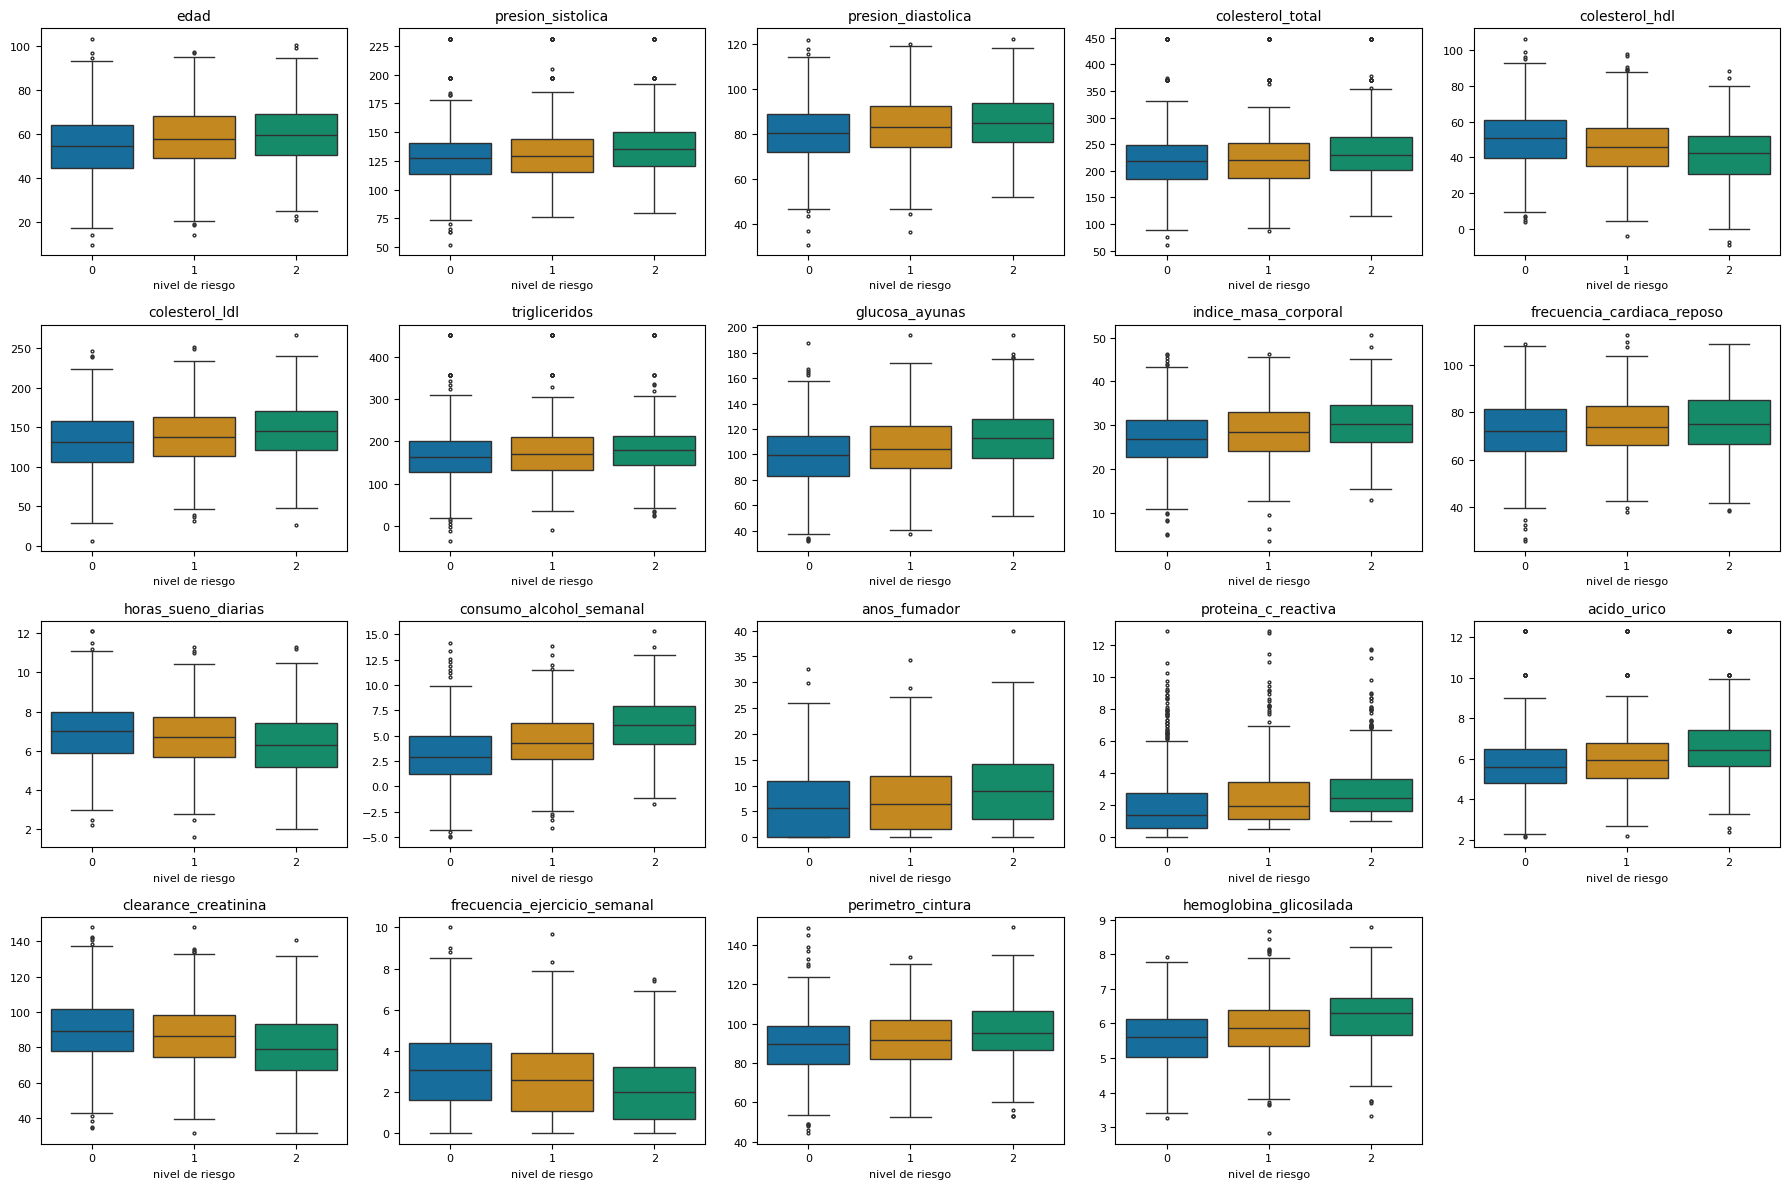

,0 - bajo,1 - moderado,2 - alto,diferencia alto - bajo
edad,54.90,57.80,59.60,4.70
presion_sistolica,127.70,129.10,135.60,7.90
presion_diastolica,80.30,82.95,85.00,4.70
colesterol_total,218.00,221.10,229.00,11.00
colesterol_hdl,50.60,45.65,42.20,-8.40
colesterol_ldl,131.80,137.00,144.80,13.00
trigliceridos,163.80,171.50,180.20,16.40
glucosa_ayunas,99.60,104.60,112.60,13.00
indice_masa_corporal,26.80,28.50,30.20,3.40
frecuencia_cardiaca_reposo,72.30,73.70,75.30,3.00


In [31]:
n_columnas = 5
n_filas = math.ceil(len(COLS_NUMERICAS) / n_columnas)
fig, axes = plt.subplots(n_filas, n_columnas, figsize=(18, n_filas * 3))
axes = axes.flatten()

for i, col in enumerate(COLS_NUMERICAS):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette='colorblind',
                legend=False, fliersize=2, ax=axes[i])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('nivel de riesgo', fontsize=8)
    axes[i].set_ylabel('')
    axes[i].tick_params(labelsize=8)

for ax in axes[len(COLS_NUMERICAS):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

# Medianas por nivel de riesgo
medianas = df.groupby(TARGET)[COLS_NUMERICAS].median().T
medianas.columns = [ETIQUETAS_RIESGO[c] for c in medianas.columns]
medianas['diferencia alto - bajo'] = medianas['2 - alto'] - medianas['0 - bajo']
medianas.round(2)

- Todas las variables se ordenan de forma monótona con el riesgo. La mediana sube (o baja) de la clase 0 a la 1 y de la 1 a la 2, sin excepciones. Esto respalda tratar el objetivo como una escala ordenada.
- Los sentidos son los esperables desde un punto de vista clinico. Suben con el riesgo el alcohol (2,9 > 4,3 > 6,1 UBE), la HbA1c (5,60 > 5,87 > 6,30 %), la proteína C reactiva, el ácido úrico, la glucosa, el IMC, la edad y las presiones. Bajan el HDL (50,6 > 42,2 mg/dL), el ejercicio (3,1 > 2,0 días), el filtrado renal y las horas de sueño.
- Ninguna variable separa las clases por si sola. En todas ellas las cajas se solapan ampliamente: la diferencia entre clases es un desplazamiento pequeño comparado con la dispersión dentro de cada clase. La señal está repartida entre muchas variables débiles, así que habrá que combinarlas en un modelo multivariante.
- La clase 1 (moderado) queda siempre entre las otras dos y se solapa con ambas: previsiblemente será la más difícil de clasificar.

### 3.9 Relación de los predictores con el riesgo cardiovascular

#### Variables numéricas

Cuantificamos lo que se ve en los diagramas de caja con dos medidas que no exigen normalidad y son poco sensibles a los valores extremos, porque trabajan con rangos:
- Correlación de Spearman (ρ) entre cada variable y el nivel de riesgo. Es adecuada porque el objetivo es ordinal (0 < 1 < 2). Su signo indica el sentido de la relación.
- Contraste de Kruskal-Wallis, que comprueba si la distribución de la variable es la misma en las tres clases, junto con su tamaño del efecto ε² (proporción de la variabilidad explicada por la clase; orientativamente, < 0,01 despreciable, 0,01–0,06 pequeño, 0,06–0,14 moderado, > 0,14 grande).

Con 2.254 pacientes casi cualquier diferencia resulta estadísticamente significativa, así que lo que importa es el tamaño del efecto, no el p-valor.

,n,rho de Spearman,H de Kruskal-Wallis,p-valor,epsilon2
variable,,,,,
consumo_alcohol_semanal,2254,0.388,346.5,5.872099e-76,0.154
hemoglobina_glicosilada,2254,0.283,189.0,9.116444e-42,0.084
proteina_c_reactiva,2097,0.282,167.7,3.903802e-37,0.080
acido_urico,2254,0.213,111.2,6.988414e-25,0.049
frecuencia_ejercicio_semanal,2254,-0.207,100.5,1.522599e-22,0.045
glucosa_ayunas,2142,0.210,95.3,1.976050e-21,0.045
colesterol_hdl,2254,-0.200,90.3,2.525685e-20,0.040
indice_masa_corporal,2254,0.196,89.3,4.003136e-20,0.040
clearance_creatinina,2254,-0.184,84.1,5.424542e-19,0.037


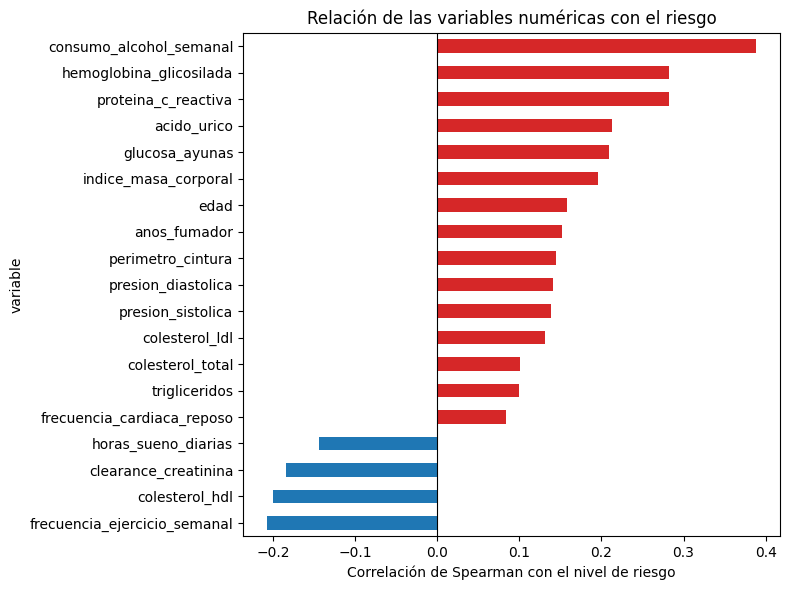

In [32]:
filas = []
for col in COLS_NUMERICAS:
    grupos = [df.loc[df[TARGET] == clase, col].dropna() for clase in (0, 1, 2)]
    h, p_valor = stats.kruskal(*grupos)
    n = sum(len(g) for g in grupos)
    rho = df[col].corr(df[TARGET], method='spearman')
    filas.append({
        'variable': col,
        'n': n,
        'rho de Spearman': rho,
        'H de Kruskal-Wallis': h,
        'p-valor': p_valor,
        'epsilon2': h / (n - 1)
    })

relacion_numericas = (pd.DataFrame(filas).set_index('variable')
                      .sort_values('epsilon2', ascending=False))
display(relacion_numericas.round({'rho de Spearman': 3, 'H de Kruskal-Wallis': 1, 'epsilon2': 3}))

fig, ax = plt.subplots(figsize=(8, 6))
orden = relacion_numericas['rho de Spearman'].sort_values()
colores = ['tab:blue' if v < 0 else 'tab:red' for v in orden]
orden.plot.barh(ax=ax, color=colores)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Correlación de Spearman con el nivel de riesgo')
ax.set_title('Relación de las variables numéricas con el riesgo')
plt.tight_layout()
plt.show()

- Las 19 variables numéricas presentan asociaciones estadísticamente significativas con el riesgo cardiovascular (p < 0,001), aunque de intensidad débil o moderada. La mayor correlación de Spearman en valor absoluto es 0,39.
- `consumo_alcohol_semanal` presenta la mayor asociación individual (ρ = 0,388; ε² = 0,154), seguido de `hemoglobina_glicosilada` y `proteina_c_reactiva` (ρ ≈ 0,28; ε² ≈ 0,08). A continuación, un conjunto amplio de variables presenta tamaños del efecto pequeños, como ácido úrico, glucosa en ayunas, ejercicio semanal, IMC, colesterol HDL y filtrado renal.
- Las variables `colesterol_total` y `trigliceridos` muestran asociaciones individuales débiles (ρ ≈ 0,10; ε² ≈ 0,01), mientras que las presiones arteriales presentan correlaciones ligeramente superiores (ρ ≈ 0,14; ε² ≈ 0,02). El colesterol HDL destaca dentro del perfil lipídico por su asociación negativa (ρ = −0,20; ε² = 0,04). La variable `frecuencia_cardiaca_reposo` presenta la asociación más débil (ρ = 0,084; ε² = 0,007).
- Consecuencia para la limpieza: `consumo_alcohol_semanal` es la variable con mayor asociación individual con el riesgo cardiovascular y presenta 177 valores negativos inválidos. Su tratamiento constituye una decisión de limpieza potencialmente importante, cuyo impacto sobre los modelos deberá evaluarse mediante un análisis de sensibilidad.
- Selección de variables: no se descarta ninguna variable en esta fase. Una asociación individual débil puede aportar información útil en combinación con otros predictores. Cualquier selección de características basada en los datos deberá realizarse dentro del proceso de validación cruzada, evitando fugas de información.

#### Variables booleanas y nominales

Para las variables categóricas usamos la tabla de contingencia con el nivel de riesgo. El contraste χ² de independencia indica si hay relación y la V de Cramér mide su intensidad en una escala de 0 (ninguna) a 1 (perfecta), comparable entre variables con distinto número de categorías.

,V de Cramér,p-valor
variable,,
uso_antihipertensivos,0.237,0.0
hipertension_previa,0.214,0.0
nivel_actividad,0.205,0.0
antecedentes_familiares_tipo,0.192,0.0
tratamiento_estatinas,0.187,0.0
diabetes_mellitus,0.186,0.0
tipo_alimentacion,0.180,0.0
fumador_actual,0.178,0.0



tipo_alimentacion (% por fila)
                       0 - bajo  1 - moderado  2 - alto
tipo_alimentacion                                      
Baja en carbohidratos      50.4          29.5      20.1
Mediterránea               64.3          23.8      11.9
Occidental                 36.8          33.9      29.3
Vegetariana                54.4          33.3      12.3

nivel_actividad (% por fila)
                      0 - bajo  1 - moderado  2 - alto
nivel_actividad                                       
Sedentario                33.6          35.1      31.3
Ligeramente activo        46.6          33.8      19.6
Moderadamente activo      62.0          24.9      13.1
Muy activo                72.2          19.4       8.4

antecedentes_familiares_tipo (% por fila)
                              0 - bajo  1 - moderado  2 - alto
antecedentes_familiares_tipo                                  
Ambos                             24.5          35.6      39.9
Materno                           45.8  

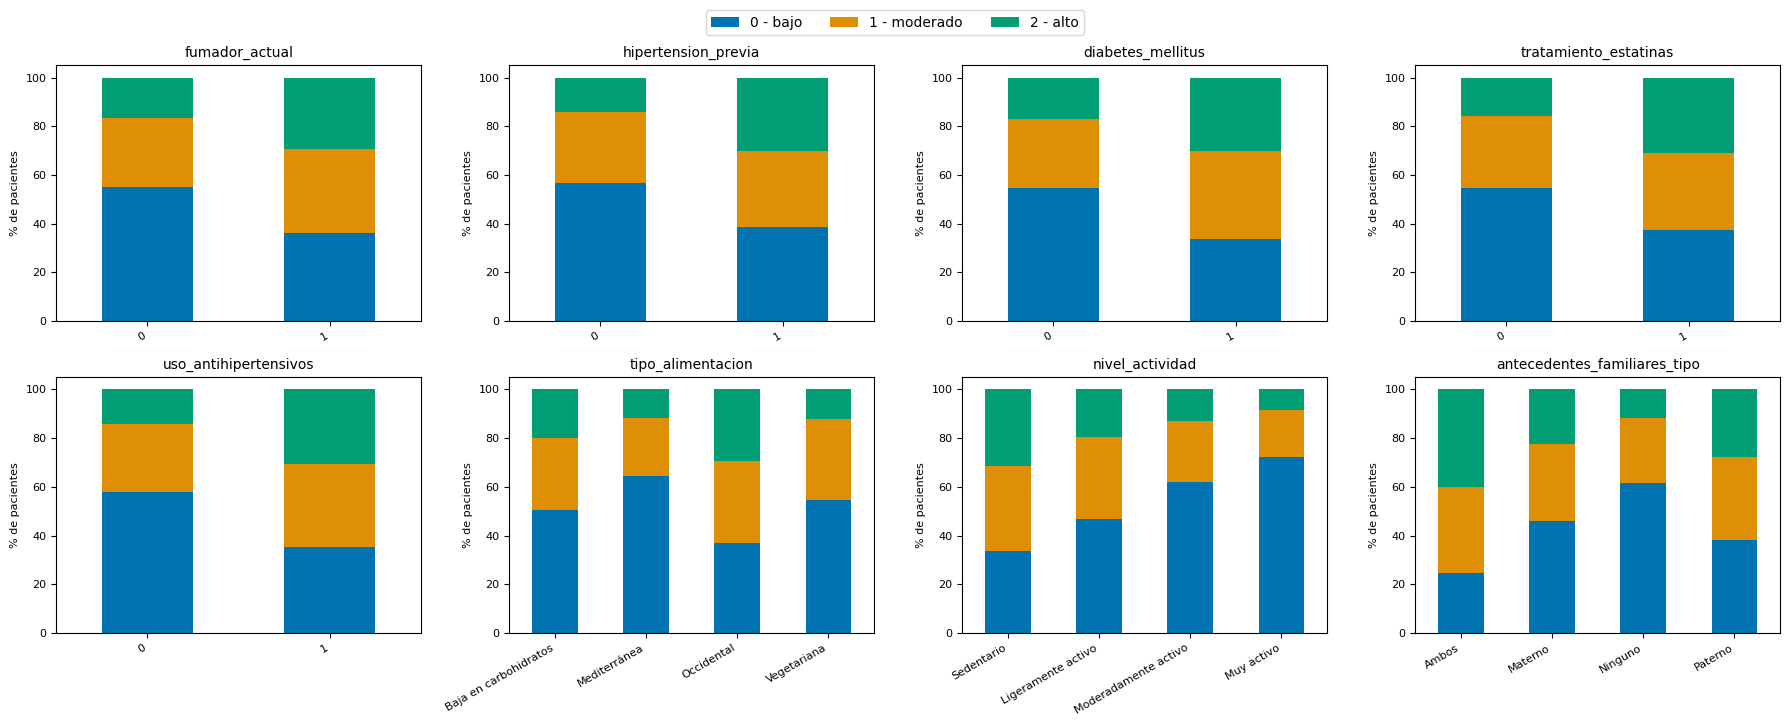

In [33]:
def v_de_cramer(tabla):
    chi2, p_valor, _, esperadas = stats.chi2_contingency(tabla)
    n = tabla.to_numpy().sum()

    if esperadas.min() < 1 or (esperadas < 5).mean() > 0.20:
        print("Advertencia: frecuencias esperadas insuficientes")

    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1))), p_valor

filas = []
for col in COLS_BOOLEANAS + COLS_NOMINALES:
    v, p_valor = v_de_cramer(pd.crosstab(df[col], df[TARGET]))
    filas.append({'variable': col, 'V de Cramér': v, 'p-valor': p_valor})
display(pd.DataFrame(filas).set_index('variable').sort_values('V de Cramér', ascending=False).round(3))

# Reparto del riesgo dentro de cada categoría (% por fila)
ORDEN_ACTIVIDAD = ['Sedentario', 'Ligeramente activo', 'Moderadamente activo', 'Muy activo']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
axes = axes.flatten()
for i, col in enumerate(COLS_BOOLEANAS + COLS_NOMINALES):
    reparto = pd.crosstab(df[col], df[TARGET], normalize='index') * 100
    if col == 'nivel_actividad':
        reparto = reparto.loc[ORDEN_ACTIVIDAD]
    reparto.columns = [ETIQUETAS_RIESGO[c] for c in reparto.columns]
    reparto.plot.bar(stacked=True, ax=axes[i], rot=30, legend=False,
                     color=sns.color_palette('colorblind')[:3])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('% de pacientes', fontsize=8)
    axes[i].tick_params(labelsize=8)
    for etiqueta in axes[i].get_xticklabels():
        etiqueta.set_ha('right')
    if col in COLS_NOMINALES:
        print(f'\n{col} (% por fila)')
        print(reparto.round(1).to_string())
simbolos, nombres = axes[0].get_legend_handles_labels()
fig.legend(simbolos, nombres, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
plt.show()

- Las ocho variables categóricas presentan asociaciones estadísticamente significativas con el riesgo cardiovascular (p < 0,001), con tamaños del efecto de intensidad baja a moderada (V de Cramér entre 0,178 y 0,237).
- Variables booleanas: `uso_antihipertensivos` presenta la mayor asociación individual (V = 0,237), seguido de `hipertension_previa` (V = 0,214). La proporción de pacientes con riesgo alto es aproximadamente el doble entre quienes presentan estas condiciones (30,6 % frente a 14,3 % y 30,4 % frente a 14,0 %, respectivamente). La asociación positiva entre tratamiento antihipertensivo y riesgo puede explicarse por confusión por indicación: el tratamiento identifica a pacientes con factores de riesgo preexistentes, sin implicar que el medicamento incremente el riesgo.
- Nivel de actividad: presenta un gradiente ordinal claro. La proporción de riesgo alto disminuye progresivamente desde el 31,3 % en pacientes sedentarios hasta el 19,6 %, 13,1 % y 8,4 % en los niveles de actividad superiores. Aunque inicialmente se clasifique como nominal, sus categorías tienen un orden natural, por lo que resulta razonable evaluar tanto una codificación ordinal como one-hot durante el modelado.
- `antecedentes_familiares_tipo`: la proporción de pacientes con riesgo alto aumenta del 11,9 % sin antecedentes al 39,9 % con antecedentes por ambas ramas. Los antecedentes paternos presentan una proporción de riesgo alto superior a los maternos (27,7 % frente a 22,4 %), aunque no se ha contrastado específicamente la significación de esta diferencia.
- `tipo_alimentacion`: la dieta occidental presenta la mayor proporción de pacientes con riesgo alto (29,3 %), mientras que la mediterránea y la vegetariana presentan las menores (≈ 12 %). Al tratarse de categorías sin orden natural, se considera apropiada la codificación one-hot.
- Tratamiento de las variables categóricas: las tres variables inicialmente clasificadas como nominales no presentan valores ausentes ni categorías de frecuencia especialmente baja (la menos frecuente, «Ambos», cuenta con 188 pacientes). Por tanto, no se considera necesario agrupar categorías. No obstante, `nivel_actividad` tiene un orden natural y podrá tratarse como ordinal durante el modelado.

### 3.10. Relación entre predictores

Si dos predictores están muy correlacionados aportan información redundante: los modelos lineales se vuelven inestables (multicolinealidad) y podría bastar con uno de ellos. Lo comprobamos con la matriz de correlaciones de Spearman entre las variables numéricas.

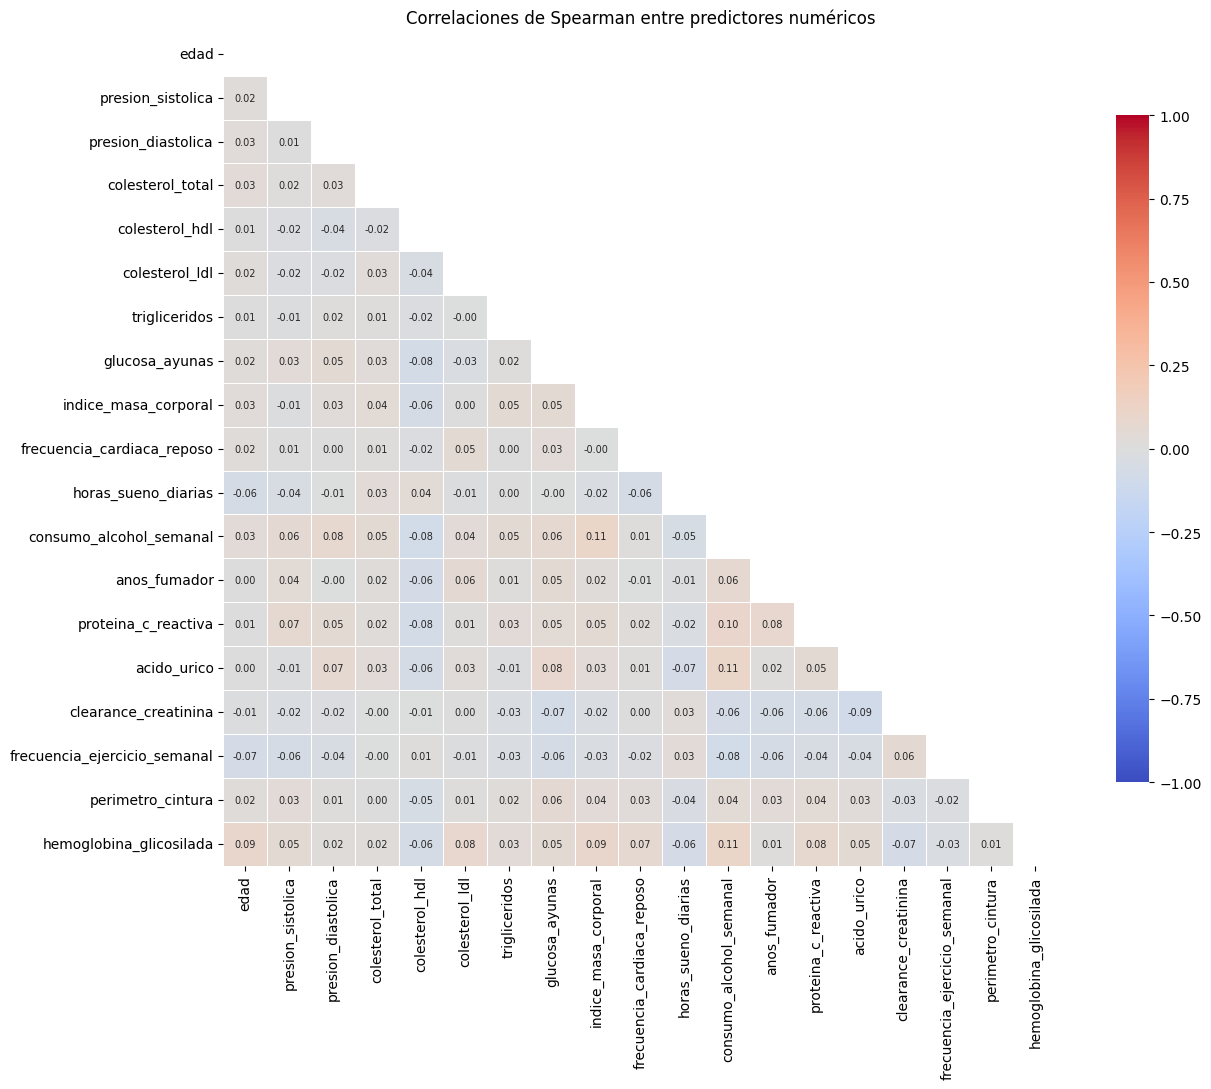

In [34]:
correlaciones = df[COLS_NUMERICAS].corr(method='spearman')
mascara = np.triu(np.ones_like(correlaciones, dtype=bool))

plt.figure(figsize=(14, 11))
sns.heatmap(correlaciones, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
            annot_kws={'size': 7}, cbar_kws={'shrink': 0.8})
plt.title('Correlaciones de Spearman entre predictores numéricos')
plt.tight_layout()
plt.show()

In [35]:
PARES_CLINICOS = [('presion_sistolica', 'presion_diastolica'), ('indice_masa_corporal', 'perimetro_cintura'),
                  ('glucosa_ayunas', 'hemoglobina_glicosilada'), ('colesterol_total', 'colesterol_ldl')]
print('\nPares con correlación clínicamente esperada:')
for a, b in PARES_CLINICOS:
    print(f'  {a} - {b}: rho = {correlaciones.loc[a, b]:.3f}')


Pares con correlación clínicamente esperada:
  presion_sistolica - presion_diastolica: rho = 0.007
  indice_masa_corporal - perimetro_cintura: rho = 0.038
  glucosa_ayunas - hemoglobina_glicosilada: rho = 0.051
  colesterol_total - colesterol_ldl: rho = 0.026


- Redundancia entre predictores: las correlaciones de Spearman entre las variables numéricas son prácticamente nulas (|ρ| ≤ 0,11). No se detectan asociaciones bivariadas suficientemente intensas como para justificar la eliminación de variables por redundancia. No obstante, este análisis no descarta completamente la multicolinealidad, que podrá evaluarse mediante VIF si se utilizan modelos lineales.
- Relaciones entre predictores y riesgo: las pequeñas correlaciones observadas entre algunos predictores podrían deberse parcialmente a su asociación común con el nivel de riesgo cardiovascular. Esta hipótesis puede explorarse calculando las correlaciones dentro de cada clase de riesgo.
- Coherencia clínica del dataset: no aparecen las asociaciones positivas que cabría esperar entre variables fisiológicamente relacionadas: presión sistólica y diastólica (ρ = 0,007), IMC y perímetro de cintura (ρ = 0,038), glucosa y HbA1c (ρ = 0,051), y colesterol total y LDL (ρ = 0,026). La ausencia simultánea de estas relaciones constituye un indicio importante de que el dataset podría haber sido generado sintéticamente, sin preservar adecuadamente las dependencias clínicas entre predictores. Los resultados son compatibles con una generación relativamente independiente de las variables, posiblemente condicionada por la clase de riesgo, aunque no permiten confirmar el mecanismo de generación.

**Consecuencias para el preprocesamiento y el modelado:**

1. **Validación de coherencia:** la ausencia de asociaciones fisiológicas esperadas limita la utilidad de las reglas de coherencia entre variables para identificar posibles errores de captura. Se mantienen las comprobaciones de dominios válidos, valores extremos e inconsistencias clínicas o matemáticas justificadas.

2. **Imputación de ausentes:** dado que los predictores numéricos presentan correlaciones muy débiles entre sí, se plantea la hipótesis de que métodos multivariantes como k-NN o la imputación iterativa podrían ofrecer ventajas limitadas frente a la imputación por mediana. Esta hipótesis se comprobará mediante la comparación de técnicas dentro del proceso de validación, evitando fugas de información.

3. **Validez externa:** la ausencia de dependencias fisiológicas habituales entre predictores constituye una limitación relevante del dataset. Los modelos podrían aprender patrones estadísticos que no reflejen adecuadamente las relaciones presentes en poblaciones clínicas reales, por lo que su rendimiento interno no garantiza su capacidad de generalización a pacientes reales.

### 3.11 Variable objetivo y desbalanceo

,pacientes,porcentaje (%)
0 - bajo,1127,50.00
1 - moderado,676,29.99
2 - alto,451,20.01


Ratio de desbalanceo (mayoritaria / minoritaria): 2.50


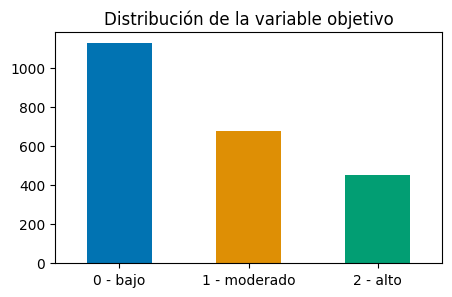

In [36]:
conteo = df[TARGET].value_counts().sort_index()
porcentaje = df[TARGET].value_counts(normalize=True).sort_index() * 100
tabla_clases = pd.DataFrame({'pacientes': conteo, 'porcentaje (%)': porcentaje.round(2)})
tabla_clases.index = ['0 - bajo', '1 - moderado', '2 - alto']
display(tabla_clases)
print(f'Ratio de desbalanceo (mayoritaria / minoritaria): {conteo.max() / conteo.min():.2f}')

fig, ax = plt.subplots(figsize=(5, 3))
tabla_clases['pacientes'].plot.bar(ax=ax, rot=0, color=sns.color_palette('colorblind')[:3])
ax.set_title('Distribución de la variable objetivo')
plt.show()

- Distribución de clases: el riesgo cardiovascular presenta una distribución del 50 % (bajo), 30 % (moderado) y 20 % (alto), con un ratio de desbalanceo de 2,5:1, considerado moderado.
- Importancia clínica: la clase minoritaria corresponde al riesgo alto, cuya detección resulta especialmente relevante. Los falsos negativos de esta clase implican infravalorar el riesgo cardiovascular del paciente, siendo potencialmente más grave clasificarlo como riesgo bajo que como moderado.
- Limitaciones de la exactitud: un clasificador trivial que predijera siempre riesgo bajo alcanzaría un 50 % de exactitud sin capacidad discriminativa. Por tanto, la exactitud no se utilizará como métrica principal, aunque podrá mantenerse como indicador secundario.
- Evaluación de modelos: se priorizarán métricas que consideren el rendimiento por clase y el desbalanceo, especialmente la sensibilidad de la clase de riesgo alto, F1-macro, balanced accuracy y la matriz de confusión. También se considerará el kappa de Cohen ponderado para incorporar el carácter ordinal del objetivo. El clasificador trivial servirá como línea base de comparación.

**Decisiones para el preprocesamiento, la validación y la evaluación:**

- **Particiones estratificadas:** mantener aproximadamente la distribución 50/30/20 de las clases en entrenamiento, test y cada pliegue de validación cruzada.

- **Tratamiento del desbalanceo:** comparar inicialmente modelos sin ponderación y con `class_weight='balanced'`, priorizando esta última como primera alternativa al desbalanceo moderado (2,5:1). Si resulta necesario, evaluar técnicas de remuestreo como SMOTE, aplicadas exclusivamente sobre los datos de entrenamiento mediante `imblearn.pipeline.Pipeline`, dentro de la validación cruzada.

- **Optimización de hiperparámetros:** utilizar explícitamente `scoring='f1_macro'` en `GridSearchCV` o `RandomizedSearchCV`, evitando que la selección de hiperparámetros dependa de la exactitud por defecto. Considerar optimización multimetric mediante `scoring` con varias métricas y `refit='f1_macro'`.

- **Evaluación multiclase:** priorizar F1-macro, balanced accuracy y sensibilidad de la clase de riesgo alto, complementadas con la matriz de confusión y métricas por clase. Mantener la exactitud como métrica secundaria y comparar los resultados con un clasificador trivial.

- **Evaluación ordinal:** incorporar el kappa de Cohen ponderado cuadrático para penalizar más los errores entre clases extremas (0 ↔ 2) que entre clases contiguas (0 ↔ 1 o 1 ↔ 2), sin asumir que esas ponderaciones reflejan necesariamente los costes clínicos reales.

### 3.12 Escalas de las variables

In [37]:
escalas = df[COLS_NUMERICAS].agg(['min', 'max', 'std']).T
escalas['rango'] = escalas['max'] - escalas['min']
escalas.sort_values('rango', ascending=False).round(2)

,min,max,std,rango
trigliceridos,-35.70,452.70,72.74,488.40
colesterol_total,61.10,448.59,62.73,387.49
colesterol_ldl,6.10,266.70,36.73,260.60
presion_sistolica,52.20,231.36,26.93,179.16
glucosa_ayunas,32.00,194.00,24.94,162.00
clearance_creatinina,31.20,147.80,18.37,116.60
colesterol_hdl,-8.80,106.30,15.99,115.10
perimetro_cintura,44.20,148.90,14.87,104.70
edad,9.80,103.50,14.45,93.70
presion_diastolica,30.80,122.50,13.08,91.70


**Diferencias de escala entre predictores numéricos:**

Los rangos observados presentan diferencias importantes, desde aproximadamente 6 unidades para la hemoglobina glicosilada (HbA1c) hasta 488 para los triglicéridos. También existen diferencias considerables en las desviaciones típicas.

Estas diferencias pueden afectar especialmente a los modelos basados en distancias, como k-NN, y a los modelos lineales regularizados, como la regresión logística.

**Decisión para el preprocesamiento:** incorporar escalado cuando el algoritmo lo requiera, comparando `StandardScaler` y `RobustScaler` si resulta pertinente. El escalador se ajustará exclusivamente con los datos de entrenamiento de cada partición, dentro del pipeline, para evitar fugas de información.

Los modelos basados en árboles se evaluarán, en principio, sin escalado. Los valores clínicamente inválidos deberán tratarse antes de aplicar las transformaciones.

## 4. Decisiones de limpieza de datos

Este apartado recoge, sin ejecutar código, las decisiones que se derivan del EDA (apartado 3). El apartado 5 las automatiza en una función. Se distinguen dos tipos de operación:

- **Reglas deterministas de dominio** (eliminar menores, recortar, convertir en NaN valores imposibles): no aprenden ningún parámetro de los datos, así que pueden aplicarse a todo el conjunto antes de dividir sin riesgo de fuga de información. Se aplican a un paciente nuevo exactamente igual.
- **Transformaciones aprendidas** (imputación, escalado, remuestreo): dependen de los datos y se ajustan **solo con el entrenamiento de cada pliegue**, dentro de un *pipeline* (apartado de modelado). No se aplican aquí.
- **Transformaciones deterministas de modelado** (`log1p` de la PCR): no aprenden parámetros, así que no hay riesgo de fuga, pero no son limpieza. Se incluyen en el *pipeline* por reproducibilidad y para comparar con y sin transformación (los árboles no la necesitan).

### 4.1 Decisiones

| # | Problema | Decisión | Afectados | Justificación |
|---|---|---|---|---|
| 1 | Edad con decimales (91 %) | Aceptarla como variable continua | — | Es una convención del registro, no un error de cada paciente; los decimales aportan precisión. |
| 2 | Menores de 18 años | Eliminar las filas | 4 filas (0,2 %) | Están fuera de la población definida en el enunciado y dos son absurdos (9,8 años con 12,6 años fumando). Quedan 2250 pacientes. |
| 3 | Ejercicio semanal > 7 | Aceptar decimales (promedio semanal) y **recortar a 7** | 41 valores | 7 es el máximo permitido por la definición de la variable (días por semana). No se puede conocer el valor real: 31 de los 41 están entre 7,1 y 7,9, pero hay 10 entre 8,1 y 10, por lo que el recorte es una decisión operativa y no recupera el dato. |
| 4 | Alcohol semanal negativo | **Recortar a 0** como decisión operativa; se compara con NaN en el análisis de sensibilidad (`regla_alcohol`) | 177 valores | Son inválidos por definición (de −5 a −0,1; media −1,3), pero no se conoce el valor real: convertir −5 en 0 es una asunción. Se prefiere al NaN porque son la cola baja de la variable, no ausentes al azar, y una imputación con la mediana (4,0) los llevaría al centro. Que 146 de los 177 sean de clase 0 apoya descartar esa imputación, pero no justifica el recorte. **Limitaciones:** el recorte crea un pico de 184 ceros (8,2 %) frente a 7 originales, y el alcohol es la variable más asociada al riesgo (ρ = 0,39), por lo que la decisión se evalúa con la sensibilidad. |
| 5 | Valores imposibles o implausibles | Convertir en **NaN** el valor (no el paciente) | Ver tabla 4.2 | Incompatibles con un adulto vivo o con la propia definición de la variable. |
| 6 | Valores anómalos repetidos en cuatro variables (`presion_sistolica`, `colesterol_total`, `trigliceridos`, `acido_urico`) | Convertir en **NaN solo los valores repetidos**, conservando a los pacientes | 448 celdas en 419 pacientes (18,6 %) tras retirar a los menores (449 y 420 en el conjunto completo) | Ver el análisis de 3.6.5, resumido en 4.2 bis. Las evidencias de 4.2 bis apuntan a generación o sustitución artificial, aunque el mecanismo no se puede demostrar. No parecen mediciones fiables: aportan ruido y una falsa asimetría, y no corresponden a pacientes con valores extremos reales, por lo que se tratan como ausentes y no como mediciones. |
| 7 | Sistólica ≤ diastólica | **Ambas presiones a NaN** | 44 filas | Es incompatible con la fisiología y no se puede saber cuál de las dos es errónea. Incluye las tres sistólicas más bajas (52,2; 62,8; 63,5). |
| 8 | LDL > colesterol total | **Conservar** los valores, registrarlos como incidencia y evaluar su impacto con un análisis de sensibilidad (conservar / LDL a NaN / ambos a NaN) | 140 filas (6,2 %) | Es incoherente por definición (el LDL es una fracción del total), pero no hay base para atribuir el error a una de las dos variables. El LDL registrado no es compatible con la fórmula de Friedewald a partir de total, HDL y triglicéridos (muestra depurada de 3.6.6: excluye las anomalías identificadas, es decir, menores, negativos y valores repetidos, pero **no** las incoherencias LDL > total, de modo que la comprobación no depende de encontrar concordancia entre las variables; n = 1.906 con triglicéridos entre 0 y 400: r = 0,04 con el valor calculado; solo el 13,5 % de las diferencias es ≤ 10 mg/dL), y las correlaciones LDL–total (0,04) y LDL–HDL (−0,03) son ≈ 0. Es compatible con una generación artificial con escasa dependencia entre las variables lipídicas (las correlaciones no demuestran independencia), y no hay evidencia para atribuir el error al LDL y no al total. Anular una de ellas introduciría ausencias artificiales (sobre los 2.250 pacientes tras aplicar el resto de reglas, las filas con algún NaN subirían del 39,2 % al 43,5 %) sin certeza de corregir nada. El validador la mantiene como `INCONSISTENCIA` (revisión). |
| 9 | Años de fumador > edad | **Años de fumador a NaN** | 1 fila, que ya se elimina en la decisión 2 (0 tras aplicar el orden de 4.4) | Es imposible. Se mantiene como regla de validación por si llegan datos nuevos. |

### 4.2 Límites de plausibilidad (decisión 5)

Se convierte en NaN el valor que queda por debajo del límite indicado. En HDL y triglicéridos el límite es ≤ 0 porque ningún paciente tiene un valor exactamente nulo (los 4 casos de cada variable son negativos).

| Variable | Valor no plausible | Justificación | Afectados |
|---|---|---|---|
| `colesterol_hdl` | ≤ 0 | Una concentración no puede ser nula ni negativa | 4 |
| `trigliceridos` | ≤ 0 | Ídem | 4 |
| `indice_masa_corporal` | < 10 kg/m² | Cerca del límite de supervivencia en desnutrición extrema; los 8 valores son de 3,6 a 9,7 | 8 |
| `frecuencia_cardiaca_reposo` | < 30 lpm | Bradicardia extrema, excepcional en una medición rutinaria de frecuencia cardíaca en reposo; se considera no plausible para este estudio | 2 |
| `perimetro_cintura` | < 40 cm | Extremadamente pequeño para un adulto; mínimo observado 44,2 cm, por lo que no hay ningún caso y la regla solo actúa como validación de datos nuevos | 0 |


> **Nota sobre los umbrales.** IMC < 10 y FC < 30 son límites de plausibilidad extrema, elegidos para identificar valores extremadamente implausibles en la población adulta estudiada, sin asumir que constituyen límites fisiológicos absolutos. No se establece un umbral inferior de anulación para HbA1c. Aunque se observan valores muy bajos (2,82 %–3,6 %), su interpretación requiere una valoración clínica específica. Por tanto, se conservan y se registran como posibles alertas cuando corresponda.

### 4.2 bis Evidencia sobre los valores repetidos (decisión 6)

Resultados de la tabla de 3.6.5. En conjunto son evidencias sólidas de generación o sustitución artificial; ninguna demuestra por sí sola el mecanismo.

- **Misma posición relativa en las cuatro variables.** Los dos valores repetidos de cada variable están a 3,50–3,51 y 5,25–5,26 desviaciones típicas de la media del resto (la media y la desviación típica se calcularon excluyendo previamente los valores repetidos). Que cuatro magnitudes clínicas con unidades y rangos distintos coincidan en esa posición apunta a un procedimiento automático.
- **No es compatible con un recorte simple a un único máximo (*top-coding*).** En `presion_sistolica` y `colesterol_total` se observan valores superiores al primer valor repetido (204,6 frente a 196,95 y 378,9 frente a 371,24), y un recorte dejaría un único pico, no dos.
- **No se detecta asociación estadísticamente significativa con el riesgo** (χ² por variable, p entre 0,30 y 0,82). Cada variable tiene entre 90 y 135 pacientes afectados (36–74 por valor), por lo que la potencia estadística es limitada y el resultado se considera evidencia complementaria.
- **Se parecen al resto en las demás variables.** La mayor diferencia estandarizada de medias en las otras 15 variables numéricas es 0,09 (IMC), por debajo de 0,1
- **Efecto de estos valores sobre la distribución.** Con ellos la asimetría es ≈ 1,3 y sin ellos ≈ 0.
- **Los decimales solo delatan a algunas variables.** En `presion_sistolica` y `colesterol_total`, los dos valores tienen 2 decimales y ningún otro valor de la columna. En `trigliceridos` solo 357,56 los tiene y en `acido_urico` el 90 % de los valores ya tiene 2, por lo que no distinguen nada.

### 4.3 Qué no se hace y limitaciones

**No se modifican:**
- **Valores atípicos por rango intercuartílico (IQR).** En 3.7, una vez retirados los valores anómalos, las variables continuas conservan entre 6 y 18 atípicos, y la PCR 89. Son valores plausibles (la PCR tiene una asimetría natural), por lo que se conservan. La PCR se transforma con `log1p` (asimetría 0,24, resultado de aplicar `log1p`) en el *pipeline*: es determinista, pero es una decisión de modelado y no de limpieza.
- **Variables binarias** (diabetes, hipertensión, etc.): el criterio IQR no tiene sentido en ellas (en diabetes, Q1 = Q3 = 0).
- **Valores ausentes originales** (23,6 % de las filas): no se tratan aquí. La imputación se hace dentro del *pipeline* con los datos de entrenamiento de cada pliegue. El EDA (3.4) no detecta evidencias suficientes para rechazar un mecanismo MCAR en los valores ausentes originales, aunque no permite confirmarlo.

**Limitaciones asumidas:**
- Los valores repetidos son altos (+3,5 y +5,25 desviaciones). Si sustituyen a valores reales también altos, los NaN introducidos podrían ser MNAR y una imputación por la mediana los infraestimaría. Se evaluará su impacto comparando estrategias de imputación e incorporando indicadores de ausencia en las cuatro variables con valores repetidos (`presion_sistolica`, `colesterol_total`, `trigliceridos` y `acido_urico`). Ninguna tenía ausentes originales, por lo que sus NaN proceden de las reglas de limpieza, principalmente de los valores repetidos. Estos indicadores no garantizan corregir el posible sesgo MNAR.
- Tras aplicar las reglas, el 39,2 % de las filas tiene al menos un NaN (el 43,5 % si se anulase el LDL incoherente). Esto exige una imputación robusta y justifica comparar estrategias de imputación en la validación.
- Las incoherencias entre variables (sistólica ≤ diastólica, LDL > total y LDL > no HDL, con 559 casos) son compatibles con una generación con escasa dependencia entre ellas: los casos observados (44, 140 y 559) son próximos a los esperados bajo independencia (≈ 56, ≈ 156 y ≈ 565, permutando una de las dos columnas), aunque eso no demuestra independencia ni permite determinar su origen. Presión y tabaco se anulan por coherencia fisiológica y lógica; LDL > total se conserva y se evalúa con el análisis de sensibilidad. No se atribuyen automáticamente a errores de captura, pero tampoco se descarta que lo sean.

### 4.4 Orden de aplicación

El orden importa porque unas reglas dejan sin efecto a otras (el caso de tabaco desaparece al eliminar al menor):

1. Eliminar menores de 18 años (decisión 2).
2. Aplicar recortes: ejercicio a 7 y alcohol a 0 (decisiones 3 y 4).
3. Convertir en NaN los valores fuera de los límites de plausibilidad (decisión 5, tabla 4.2).
4. Convertir en NaN los valores repetidos anómalos (decisión 6).
5. Aplicar las reglas entre variables: anular ambas presiones cuando sistólica ≤ diastólica y los años de fumador cuando superen la edad (decisiones 7 y 9). Las incoherencias LDL > colesterol total se conservan y se documentan mediante el validador (decisión 8).

La función del apartado 5 devolverá, además del *DataFrame* limpio, un registro de cuántos valores cambia cada regla, para contrastarlo con esta tabla, y se contrastará con el validador (apartado 4.5).

### 4.5 Relación con el validador

Se usa `validador_datos_cardiovasculares_v3.py`. Los tipos de incidencia se interpretan así:

| Tipo del validador | Qué hace la limpieza |
|---|---|
| `INVALIDO` por dominio (negativos, > 7 días, menores) | Se corrige según las decisiones 2–5. |
| `EXTREMO` | Es un aviso de revisión, **no** una regla de eliminación: solo se anulan los de la tabla 4.2. |
| `INCONSISTENCIA` | El tipo describe la naturaleza del problema y la columna `decision`, su tratamiento. Presión y tabaco: `corregir` (se anulan, decisiones 7 y 9). LDL > total y LDL > no HDL: `conservar` (se mantienen y se registran, decisión 8). |
| `ALERTA_CLINICA` | No se modifica: son valores plausibles. |
| `ARTEFACTO` | Valores repetidos de la decisión 6: se anulan. |
| Edad y días no enteros, valores ausentes | No son incidencias por defecto (decisiones 1 y 3 y apartado 4.3). |

La limpieza no pretende dejar el validador a cero incidencias. Debe comprobarse que no queda ninguna incidencia con decisión `corregir`, mientras que las clasificadas como `conservar` o `revision` pueden permanecer. En el apartado 5 se ejecutará `verificar_limpieza` y se realizará una comprobación explícita de las correcciones pendientes.

## 5. Limpieza basada en reglas

La función `limpiar_datos_cardiovasculares` (`src/limpieza.py`) automatiza las decisiones del apartado 4. Trabaja sobre una copia (**`df` no se modifica**), no aprende parámetros de los datos y devuelve el *DataFrame* limpio (`df_limpio`) y un registro de cuántas celdas modifica cada regla. Las constantes (límites, valores repetidos) están en `src/reglas_datos.py` y las usa también el validador v3, para que ambos sean coherentes.

A partir de aquí, el trabajo de modelado parte de `df_limpio`. La imputación no se hace aquí: va en el *pipeline*, ajustada solo con el entrenamiento de cada pliegue.

In [38]:
from src.limpieza import limpiar_datos_cardiovasculares
from src.validador_datos_cardiovasculares_v3 import resumen_ausentes

df_limpio, registro = limpiar_datos_cardiovasculares(df, regla_lipidos='conservar')
print(f'Filas: {len(df)} -> {len(df_limpio)}')
registro

Filas: 2254 -> 2250


,decision,regla,variable,celdas,filas
0,2,Eliminar menores de 18,(fila),4,4
1,3,Ejercicio > 7 recortado,frecuencia_ejercicio_semanal,41,41
2,4,Alcohol negativo recortado a 0,consumo_alcohol_semanal,177,177
3,5,colesterol_hdl <= 0 a NaN,colesterol_hdl,4,4
4,5,trigliceridos <= 0 a NaN,trigliceridos,4,4
5,5,indice_masa_corporal < 10 a NaN,indice_masa_corporal,8,8
6,5,frecuencia_cardiaca_reposo < 30 a NaN,frecuencia_cardiaca_reposo,2,2
7,5,perimetro_cintura < 40 a NaN,perimetro_cintura,0,0
8,6,"presion_sistolica: valores repetidos (196.95, ...",presion_sistolica,112,112
9,6,"colesterol_total: valores repetidos (371.24, 4...",colesterol_total,135,135


### 5.1 Contraste con la tabla 4.1

Coincide con el apartado 4: 4 menores; 41 ejercicios; 177 alcoholes; 4 + 4 + 8 + 2 + 0 por límites de plausibilidad; 449 valores repetidos en el conjunto completo, que son **448 celdas en 419 pacientes** una vez retirados los menores (uno de ellos tenía un valor repetido); 44 filas con sistólica ≤ diastólica (88 celdas); 140 filas con LDL > total, que se conservan; 0 con años de fumador > edad.

In [39]:
esperado = {2: 4, 3: 41, 4: 177, 7: 44}
obtenido = registro.groupby('decision')['filas'].sum()
for decision, n in esperado.items():
    assert obtenido[decision] == n, (decision, obtenido[decision], n)
assert registro.query("regla == 'Total valores repetidos'")['celdas'].iloc[0] == 448
assert registro.query('decision == 8')['filas'].iloc[0] == 140
print('Registro coherente con la tabla 4.1')

Registro coherente con la tabla 4.1


### 5.2 Verificación con el validador v3

Se pasa el validador al conjunto limpio con la función `auditar_datos` de 3.5. La limpieza es correcta si no queda ninguna incidencia con decisión `corregir`. Las de `conservar` (LDL > total y LDL > no HDL) pueden permanecer, porque se conservan a propósito, y las de `revision` son avisos que no requieren corrección automática.

In [40]:
incidencias_limpio, resumen_limpio = auditar_datos(df_limpio, 'v3_limpio')

pendientes = incidencias_limpio.query("decision == 'corregir'")
assert pendientes.empty, f'Quedan {len(pendientes)} incidencias por corregir'
print('Sin incidencias pendientes de corregir')
resumen_limpio.query("decision == 'conservar'")

=== v3_limpio: 2250 registros ===
Incidencias detectadas: 807
Registros afectados: 639
Registros que requieren corrección: 0

Por decisión prevista:


,incidencias
decision,
conservar,698
revision,109



Resumen por variable y regla:


,variable,tipo,regla,decision,casos
0,colesterol_ldl,INCONSISTENCIA,LDL > colesterol no-HDL,conservar,558
1,colesterol_ldl,INCONSISTENCIA,LDL > colesterol total,conservar,140
2,glucosa_ayunas,ALERTA_CLINICA,Glucosa < 54 mg/dL,revision,34
3,hemoglobina_glicosilada,ALERTA_CLINICA,HbA1c < 4 %,revision,31
4,colesterol_hdl,EXTREMO,Inferior al límite de plausibilidad,revision,16
5,proteina_c_reactiva,ALERTA_CLINICA,PCR > 10 mg/L,revision,10
6,presion_sistolica,ALERTA_CLINICA,Sistólica > 180 mmHg,revision,9
7,glucosa_ayunas,EXTREMO,Inferior al límite de plausibilidad,revision,6
8,colesterol_ldl,EXTREMO,Inferior al límite de plausibilidad,revision,1
9,horas_sueno_diarias,EXTREMO,Inferior al límite de plausibilidad,revision,1



Guardado en reports\generated: incidencias_validacion_v3_limpio.csv (807 filas) y resumen_validacion_v3_limpio.csv
Sin incidencias pendientes de corregir


,variable,tipo,regla,decision,casos
0,colesterol_ldl,INCONSISTENCIA,LDL > colesterol no-HDL,conservar,558
1,colesterol_ldl,INCONSISTENCIA,LDL > colesterol total,conservar,140


In [41]:
RUTA_PROCESADOS = RAIZ / 'data' / 'processed'
RUTA_PROCESADOS.mkdir(parents=True, exist_ok=True)
df_limpio.to_csv(RUTA_PROCESADOS / 'enfermedad_cardiovascular_limpio.csv', index=False)

### 5.3 Valores ausentes tras la limpieza

Los NaN que crean las reglas se suman a los originales (23,6 % de las filas con algún ausente). La imputación se hace dentro del *pipeline*, con los datos de entrenamiento de cada pliegue.

In [42]:
print(f"Filas con algún NaN: original {df.isna().any(axis=1).mean():.1%} -> limpio {df_limpio.isna().any(axis=1).mean():.1%}")
resumen_ausentes(df_limpio)

Filas con algún NaN: original 23.6% -> limpio 39.2%


,ausentes,porcentaje
horas_sueno_diarias,180,8.00
proteina_c_reactiva,157,6.98
presion_sistolica,156,6.93
colesterol_total,135,6.00
colesterol_ldl,134,5.96
glucosa_ayunas,112,4.98
acido_urico,111,4.93
trigliceridos,94,4.18
presion_diastolica,44,1.96
indice_masa_corporal,8,0.36


## 6. Preprocesamiento para el modelado

Este apartado decide cómo se preparan los datos para los modelos. Dividimos el preprocesamiento en los siguentes subapartados: partición y validación (6.1), imputación (6.2), codificación (6.3), escalado (6.4) y desbalanceo (6.5). 

Todas estas técnicas aprenden parámetros de los datos (medianas, escalas, categorías, pacientes sintéticos), así que para evitar data leakage se ajustan dentro de un pipeline y solo con el entrenamiento de cada pliegue.

### 6.1 Partición y validación

En este apartado interemos responder a la pregunta: ¿Cómo podemos medir el rendimiento del modelo con datos que no ha visto previamente?

Así, explicaremos cómo separar los datos en distintos conjuntos para entrenar y evaluar los modelos. El objetivo es evitar que el modelo memorice los datos disponibles y obtener una estimación realista de su capacidad de generalización a nuevos pacientes.

Vamos a reservar un conjunto de test que no interviene en ninguna decisión (Hold-out estratificado). Se estratifica por la clase para conservar el reparto 50/30/20 en ambos conjuntos. Se parte de `df_limpio` (configuración base de la limpieza).

In [43]:
X = df_limpio.drop(columns=TARGET)
y = df_limpio[TARGET]
X.head(10)

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,horas_sueno_diarias,consumo_alcohol_semanal,anos_fumador,proteina_c_reactiva,acido_urico,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo
0,57.4,192.0,78.9,NaN,62.6,149.1,245.6,NaN,30.4,95.1,6.5,7.6,9.4,3.80,3.70,69.5,3.3,110.4,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno
1,51.7,131.2,80.0,270.2,35.4,NaN,173.8,137.5,29.7,85.3,5.0,8.7,0.0,4.07,4.67,87.5,5.6,88.4,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos
2,56.7,127.1,92.5,202.3,47.7,134.1,60.9,157.4,29.4,87.5,8.7,9.7,20.8,3.39,7.15,100.6,1.2,123.8,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno
3,54.9,112.8,97.9,179.2,53.9,137.9,174.4,92.0,28.6,47.4,5.7,5.6,10.0,0.75,4.81,92.0,1.5,93.3,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno
4,47.2,115.1,97.0,242.2,56.5,159.2,195.7,63.5,18.5,69.0,6.7,0.0,5.5,NaN,NaN,93.7,5.7,91.0,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno
5,55.5,136.0,76.6,214.5,51.1,134.3,230.7,105.6,28.8,85.5,NaN,6.4,17.3,2.00,5.61,64.8,1.6,79.7,6.38,0,1,1,0,0,Baja en carbohidratos,Sedentario,Paterno
6,48.5,115.1,96.4,194.0,48.2,147.5,199.2,92.6,15.4,103.6,8.0,0.3,0.0,4.11,7.25,78.1,5.9,95.7,6.22,0,0,0,0,0,Vegetariana,Sedentario,Ambos
7,60.9,132.1,92.4,181.4,41.7,156.0,163.6,98.7,31.2,103.7,NaN,5.9,6.1,1.85,6.88,94.1,2.6,124.3,6.25,1,0,1,1,0,Vegetariana,Sedentario,Ninguno
8,52.7,98.3,70.5,213.7,47.0,165.9,246.9,90.4,35.1,87.7,5.8,8.7,15.1,3.40,5.80,73.8,2.9,93.9,6.43,0,1,1,1,1,Occidental,Sedentario,Paterno
9,68.1,141.7,88.3,154.7,50.8,133.6,145.2,102.3,33.1,96.2,6.1,1.0,24.4,1.23,5.06,71.4,3.9,102.8,5.92,1,1,0,0,1,Baja en carbohidratos,Ligeramente activo,Paterno


In [44]:
from sklearn.model_selection import train_test_split

# train_test_split con SEMILLA
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

# Tamaño de cada conjunto
print('Tamaño de cada conjunto:')
print(f"X original: {X.shape}")
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")

# Porcentaje de registros
#¿Cuántos registros han ido a cada partición?
print('\nPorcentaje de registros:')
print(f"Train: {len(X_train)/len(X):.1%}")
print(f"Test: {len(X_test)/len(X):.1%}")

# Hacemos una copia
X_train_raw = X_train.copy()
X_test_raw = X_test.copy()

# Distribución de la variable objetivo
print('\nDistribución de la variable objetivo:')
pd.DataFrame({
    "Original (%)": y.value_counts(normalize=True).sort_index()*100,
    "Train (%)": y_train.value_counts(normalize=True).sort_index()*100,
    "Test (%)": y_test.value_counts(normalize=True).sort_index()*100,
}).round(2)

Tamaño de cada conjunto:
X original: (2250, 27)
X_train: (1800, 27)
X_test: (450, 27)

Porcentaje de registros:
Train: 80.0%
Test: 20.0%

Distribución de la variable objetivo:


,Original (%),Train (%),Test (%)
riesgo_cardiovascular,,,
0,49.96,49.94,50.0
1,30.00,30.00,30.0
2,20.04,20.06,20.0


In [45]:
# número de pacientes
pd.DataFrame({
    'Total': y.value_counts(),
    'Train': y_train.value_counts(),
    'Test': y_test.value_counts(),
})

,Total,Train,Test
riesgo_cardiovascular,,,
0,1124,899,225
1,675,540,135
2,451,361,90


In [46]:
#¿Se ha conservado la proporción de clases tras la partición?
reparto = pd.DataFrame({
    'dataset limpio': y.value_counts(normalize=True),
    'entrenamiento': y_train.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True),
}).sort_index() * 100

reparto.index = [ETIQUETAS_RIESGO[c] for c in reparto.index]

display(reparto.round(1))

,dataset limpio,entrenamiento,test
0 - bajo,50.0,49.9,50.0
1 - moderado,30.0,30.0,30.0
2 - alto,20.0,20.1,20.0


El conjunto de datos se ha dividido en un 80 % para entrenamiento y un 20 % para prueba mediante train_test_split.
Con 2.250 pacientes, el test queda en 450, de los que 90 son de riesgo alto. Es suficiente para medir la métrica crítica, y deja 1.800 pacientes para entrenar y validar. 

Se ha empleado estratificación sobre la variable objetivo para mantener la proporción de pacientes de cada nivel de riesgo cardiovascular en ambos subconjuntos. 
Tras la partición se ha verificado que la distribución de clases permanece prácticamente inalterada, garantizando una evaluación representativa del modelo.

In [47]:
from sklearn.model_selection import StratifiedKFold
validacion_cruzada = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

Definimos un esquema de validación cruzada.

### 6.2 Imputación

Aquí intentaremos responder a: ¿Qué hacemos con los valores que faltan?

Durante el EDA se identificaron variables con datos ausentes. En este apartado se analizará si esos valores pueden estimarse a partir de la información disponible y qué estrategia de imputación resulta más adecuada para minimizar la pérdida de información y evitar sesgos innecesarios.

In [48]:
# Vamos a imputar los valores faltantes, usando la mediana.

from sklearn.impute import SimpleImputer

# 1. Imputamos con la mediana (calculada SOLO en train)
imputer = SimpleImputer(strategy="median")
X_train[COLS_NUMERICAS] = imputer.fit_transform(X_train[COLS_NUMERICAS])
X_test[COLS_NUMERICAS] = imputer.transform(X_test[COLS_NUMERICAS])

# 2. Tabla de imputación y controlar que ya no hay nulos.
nulos_train = X_train[COLS_NUMERICAS].isna().sum()

tabla_imputacion = pd.DataFrame({
    "variable": COLS_NUMERICAS,
    "valor_imputado": imputer.statistics_,
    "nulos_train": nulos_train.to_numpy(),
})

display(tabla_imputacion)
print(f"Total de nulos en columnas numericas: {nulos_train.sum()}")



,variable,valor_imputado,nulos_train
0,edad,57.05,0
1,presion_sistolica,128.90,0
2,presion_diastolica,81.80,0
3,colesterol_total,217.90,0
4,colesterol_hdl,47.20,0
5,colesterol_ldl,135.50,0
6,trigliceridos,166.90,0
7,glucosa_ayunas,103.70,0
8,indice_masa_corporal,28.00,0
9,frecuencia_cardiaca_reposo,73.10,0


Total de nulos en columnas numericas: 0


Se construye una tabla de imputación, emparejando cada nombre de columna con su valor imputado y comprobamos que ya no hay nulos.

### 6.3 Codificación 

Los modelos de Machine Learning trabajan con números, pero algunas variables de nuestro problema contienen categorías como el tipo de alimentación o el nivel de actividad física. En esta fase se transformarán dichas categorías en representaciones numéricas conservando, en la medida de lo posible, la información original.

Para las variables tipo_alimentacion, y antecedentes_familiares_tipo, los valores representan etiquetas o categorías, sin embargo, para la variable nivel_actividad, sí podemos considerar que los valores represenatan una escala:

- 0: Sedentario
- 1: Ligeramente activo
- 2: Moderadamente activo
- 3: Muy activo

Por ello, para esta variable no vamos a aplicar dummies, sino que vamos a sustituir los valores por la escala numérica de [0,3].

In [49]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

cols_dummies = ["tipo_alimentacion", "antecedentes_familiares_tipo"]

ohe = OneHotEncoder(
    drop="first",  # O drop=None si quieres todas las columnas
    sparse_output=False,  # Devuelve array denso para pasarlo a DataFrame
    handle_unknown="ignore",  # Evita errores si aparece una categoría nueva en test
)

# 1. Ajustamos en train y transformamos train y test
dummies_train = ohe.fit_transform(X_train[cols_dummies])
dummies_test = ohe.transform(X_test[cols_dummies])

# 2. Recuperamos los nombres de las nuevas columnas
nombres_cols = ohe.get_feature_names_out(cols_dummies)

# 3. Sustituimos las columnas originales por las nuevas dummies
X_train = pd.concat(
    [
        X_train.drop(columns=cols_dummies),
        pd.DataFrame(dummies_train, columns=nombres_cols, index=X_train.index),
    ],
    axis=1,
)

X_test = pd.concat(
    [
        X_test.drop(columns=cols_dummies),
        pd.DataFrame(dummies_test, columns=nombres_cols, index=X_test.index),
    ],
    axis=1,
)

In [50]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1800 entries, 879 to 655
Data columns (total 31 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   edad                                  1800 non-null   float64
 1   presion_sistolica                     1800 non-null   float64
 2   presion_diastolica                    1800 non-null   float64
 3   colesterol_total                      1800 non-null   float64
 4   colesterol_hdl                        1800 non-null   float64
 5   colesterol_ldl                        1800 non-null   float64
 6   trigliceridos                         1800 non-null   float64
 7   glucosa_ayunas                        1800 non-null   float64
 8   indice_masa_corporal                  1800 non-null   float64
 9   frecuencia_cardiaca_reposo            1800 non-null   float64
 10  horas_sueno_diarias                   1800 non-null   float64
 11  consumo_alcohol_seman

In [51]:
from sklearn.preprocessing import OrdinalEncoder

orden_categorias = [[
    "Sedentario",
    "Ligeramente activo",
    "Moderadamente activo",
    "Muy activo",
]]

encoder = OrdinalEncoder(categories=orden_categorias, dtype=int)

X_train["nivel_actividad"] = encoder.fit_transform(X_train[["nivel_actividad"]])
X_test["nivel_actividad"] = encoder.transform(X_test[["nivel_actividad"]])

In [52]:
X_train.info()

X_train["nivel_actividad"].head(10)

<class 'pandas.core.frame.DataFrame'>
Index: 1800 entries, 879 to 655
Data columns (total 31 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   edad                                  1800 non-null   float64
 1   presion_sistolica                     1800 non-null   float64
 2   presion_diastolica                    1800 non-null   float64
 3   colesterol_total                      1800 non-null   float64
 4   colesterol_hdl                        1800 non-null   float64
 5   colesterol_ldl                        1800 non-null   float64
 6   trigliceridos                         1800 non-null   float64
 7   glucosa_ayunas                        1800 non-null   float64
 8   indice_masa_corporal                  1800 non-null   float64
 9   frecuencia_cardiaca_reposo            1800 non-null   float64
 10  horas_sueno_diarias                   1800 non-null   float64
 11  consumo_alcohol_seman

879     0
1927    1
1305    0
900     0
2025    1
1976    0
2075    1
1325    0
209     1
1589    2
Name: nivel_actividad, dtype: int64

### 6.4 Escalado

En este apartado tratamos de dar respuesta a la pregunta: ¿Todas las variables tienen magnitudes comparables?

Algunas características presentan rangos muy diferentes. Por ejemplo, la edad puede variar entre decenas de años mientras que otras variables tienen valores mucho más elevados. En este apartado se evaluará la necesidad de normalizar o estandarizar las variables para evitar que ciertas magnitudes dominen el aprendizaje del modelo.

In [53]:
cols_a_escalar = [col for col in X_train.columns if X_train[col].nunique() > 2]
print(cols_a_escalar)
print([COLS_NUMERICAS + ['nivel_actividad']])

['edad', 'presion_sistolica', 'presion_diastolica', 'colesterol_total', 'colesterol_hdl', 'colesterol_ldl', 'trigliceridos', 'glucosa_ayunas', 'indice_masa_corporal', 'frecuencia_cardiaca_reposo', 'horas_sueno_diarias', 'consumo_alcohol_semanal', 'anos_fumador', 'proteina_c_reactiva', 'acido_urico', 'clearance_creatinina', 'frecuencia_ejercicio_semanal', 'perimetro_cintura', 'hemoglobina_glicosilada', 'nivel_actividad']
[['edad', 'presion_sistolica', 'presion_diastolica', 'colesterol_total', 'colesterol_hdl', 'colesterol_ldl', 'trigliceridos', 'glucosa_ayunas', 'indice_masa_corporal', 'frecuencia_cardiaca_reposo', 'horas_sueno_diarias', 'consumo_alcohol_semanal', 'anos_fumador', 'proteina_c_reactiva', 'acido_urico', 'clearance_creatinina', 'frecuencia_ejercicio_semanal', 'perimetro_cintura', 'hemoglobina_glicosilada', 'nivel_actividad']]


In [54]:
from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, recall_score

# Columnas que se escalan: las no binarias (19 numéricas y nivel_actividad)
cols_a_escalar = [col for col in X_train.columns if X_train[col].nunique() > 2]

# log1p es monótona y no aprende parámetros de los datos: no hay riesgo de fuga
def aplicar_log1p(X):
    X = X.copy()
    X["proteina_c_reactiva"] = np.log1p(X["proteina_c_reactiva"])
    return X

resultados = []

for nombre_scaler, scaler in [
    ("StandardScaler", StandardScaler()),
    ("RobustScaler", RobustScaler()),
]:
    for usar_log in [False, True]:

        pipeline = Pipeline([
            ("log1p", FunctionTransformer(
                aplicar_log1p if usar_log else None,
                validate=False
            )),
            ("escalado", ColumnTransformer(
                [("scaler", scaler, cols_a_escalar)],
                remainder="passthrough"
            )),
            ("modelo", LogisticRegression(
                C=0.01,
                max_iter=1000,
                random_state=SEMILLA
            ))
        ])

        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=validacion_cruzada,
            scoring={
                "f1_macro": "f1_macro",
                "recall_c2": make_scorer(
                    recall_score,
                    labels=[2],
                    average="macro",
                    zero_division=0
                )
            }
        )

        resultados.append({
            "Scaler": nombre_scaler,
            "log1p": usar_log,
            "F1-macro": scores["test_f1_macro"].mean(),
            "Recall C2": scores["test_recall_c2"].mean()
        })

tabla_resultados = pd.DataFrame(resultados)

display(tabla_resultados.sort_values(
    "F1-macro", ascending=False
).round(4))

,Scaler,log1p,F1-macro,Recall C2
1,StandardScaler,True,0.6359,0.6427
0,StandardScaler,False,0.6244,0.6482
3,RobustScaler,True,0.6155,0.6371
2,RobustScaler,False,0.6127,0.6398


In [55]:
# Datos de entrada del pipeline: SIN imputar ni escalar.
# La imputación y el escalado se harán dentro del Pipeline, en cada pliegue de la validación cruzada.
# Se parte de las copias sin imputar guardadas (X_train_raw, X_test_raw)

def codificar(df):
    """Aplica los codificadores de 6.3 a un conjunto sin codificar."""
    df = pd.concat(
        [
            df.drop(columns=cols_dummies),
            pd.DataFrame(ohe.transform(df[cols_dummies]), columns=nombres_cols, index=df.index),
        ],
        axis=1,
    )
    df["nivel_actividad"] = encoder.transform(df[["nivel_actividad"]])[:, 0]
    return df

X_train_procesado = codificar(X_train_raw)
X_test_procesado = codificar(X_test_raw)

# log1p de la PCR (decisión de la tabla anterior: StandardScaler + log1p)
for df_part in (X_train_procesado, X_test_procesado):
    df_part["proteina_c_reactiva"] = np.log1p(df_part["proteina_c_reactiva"])

# Columnas que se escalarán dentro del Pipeline
cols_a_escalar = COLS_NUMERICAS + ["nivel_actividad"]

# Comprobaciones: mismas columnas que en 6.3 y los ausentes siguen ahí (los imputa el Pipeline)
assert list(X_train_procesado.columns) == list(X_train.columns)
print("Dimensiones train:", X_train_procesado.shape)
print("Dimensiones test:", X_test_procesado.shape)
print("Valores ausentes que imputará el Pipeline (train):", int(X_train_procesado.isna().sum().sum()))

Dimensiones train: (1800, 31)
Dimensiones test: (450, 31)
Valores ausentes que imputará el Pipeline (train): 914


### 6.5 Selección de características

El EDA mostró que todas las variables se asocian con el riesgo de forma débil, que la señal está repartida entre muchas de ellas y que no hay variables redundantes (|ρ| ≤ 0,11) ni con varianza casi nula. Por eso no está claro de antemano que convenga quitar variables. En lugar de fijar el número a ojo, se compara con validación cruzada quedarse con las k variables más relacionadas con el riesgo (k = 10, 13, 18) frente a no seleccionar (`k='all'`).

- **Método:** `SelectKBest` con información mutua (`mutual_info_classif`). Es un filtro: evalúa cada variable por separado, por lo que es rápido y tiene menos riesgo de sobreajuste que un método wrapper. La información mutua detecta cualquier tipo de dependencia (no solo lineal) y no supone normalidad. `chi2` no se puede usar porque los datos escalados tienen valores negativos.
- **Reproducibilidad:** la estimación de la información mutua es aleatoria, así que se fija `random_state=SEMILLA`.
- **Sin fuga:** la selección usa la variable objetivo, así que va **dentro del Pipeline**, después del escalado y antes de SMOTE, y se ajusta solo con el entrenamiento de cada pliegue.

In [56]:
from functools import partial

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Información mutua con semilla fija: sin ella, cada ejecución selecciona variables distintas
mi = partial(mutual_info_classif, random_state=SEMILLA)


def estrategia_smote(y):
    """SMOTE para multiclase: lleva las clases 1 y 2 al 65 % de la clase mayoritaria.
    (sampling_strategy=0.65 solo es válido con dos clases.) Se calcula en cada pliegue."""
    conteo = pd.Series(y).value_counts()
    objetivo = int(conteo.max() * 0.65)
    return {clase: max(objetivo, n) for clase, n in conteo.items() if n < conteo.max()}


# Imputación y escalado, ajustados solo con el entrenamiento de cada pliegue
preprocesador = ColumnTransformer(
    transformers=[
        (
            "escalado",
            Pipeline([
                ("imputacion", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            cols_a_escalar,
        )
    ],
    remainder="passthrough",  # booleanas e indicadoras: sin ausentes ni escalado
    verbose_feature_names_out=False,
).set_output(transform="pandas")


# Pipeline común: Imputación + Escalado -> Selección -> SMOTE -> Modelo
# k = número de variables que se conservan; k="all" conserva las 31
def crear_pipeline(modelo, k="all"):
    return Pipeline([
        ("preprocesado", preprocesador),
        ("seleccion", SelectKBest(score_func=mi, k=k)),
        ("smote", SMOTE(sampling_strategy=estrategia_smote, random_state=SEMILLA)),
        ("modelo", modelo),
    ])

In [57]:
# ¿Cuántas variables? Comparación con validación cruzada (solo entrenamiento).
# Modelo de referencia: regresión logística con sus valores por defecto (los hiperparámetros se ajustan en el apartado 7).
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import cross_validate

metricas = {
    "f1_macro": "f1_macro",
    "recall_c2": make_scorer(recall_score, labels=[2], average="macro", zero_division=0),
}

filas = []
for k in [10, 13, 15, 18, "all"]:
    pipe = crear_pipeline(LogisticRegression(max_iter=1000, random_state=SEMILLA), k=k)
    res = cross_validate(pipe, X_train_procesado, y_train,
                         cv=validacion_cruzada, scoring=metricas, n_jobs=-1)
    filas.append({
        "k": k,
        "F1-macro (media)": res["test_f1_macro"].mean(),
        "F1-macro (desv.)": res["test_f1_macro"].std(),
        "Recall C2 (media)": res["test_recall_c2"].mean(),
    })

display(pd.DataFrame(filas).set_index("k").round(4))

,F1-macro (media),F1-macro (desv.),Recall C2 (media)
k,,,
10,0.5486,0.0302,0.6869
13,0.5711,0.0200,0.6869
15,0.5815,0.0184,0.6896
18,0.5946,0.0214,0.7035
all,0.6584,0.0081,0.7674


**Resultado:** cuantas más variables, mejor. Con las 31 variables se obtiene un F1-macro de 0,6584 y una sensibilidad del riesgo alto de 0,7674. Las diferencias son mucho mayores que la variación entre pliegues (desviación típica de 0,008 a 0,030).

**Decisión: no se seleccionan variables** (`k='all'`). 

Vamos a mostrar las variables seleccionadas, ordenadas por puntuación, en base a la función f_classif. Mide la relación lineal entre cada variable y la variable objetivo (y) comparando la varianza entre clases frente a la varianza dentro de cada clase. Tien una limitación, solo detecta relaciones lineales y asume que las variables siguen una distribución aproximadamente normal (esto se ha comprobado que es así en el EDA).

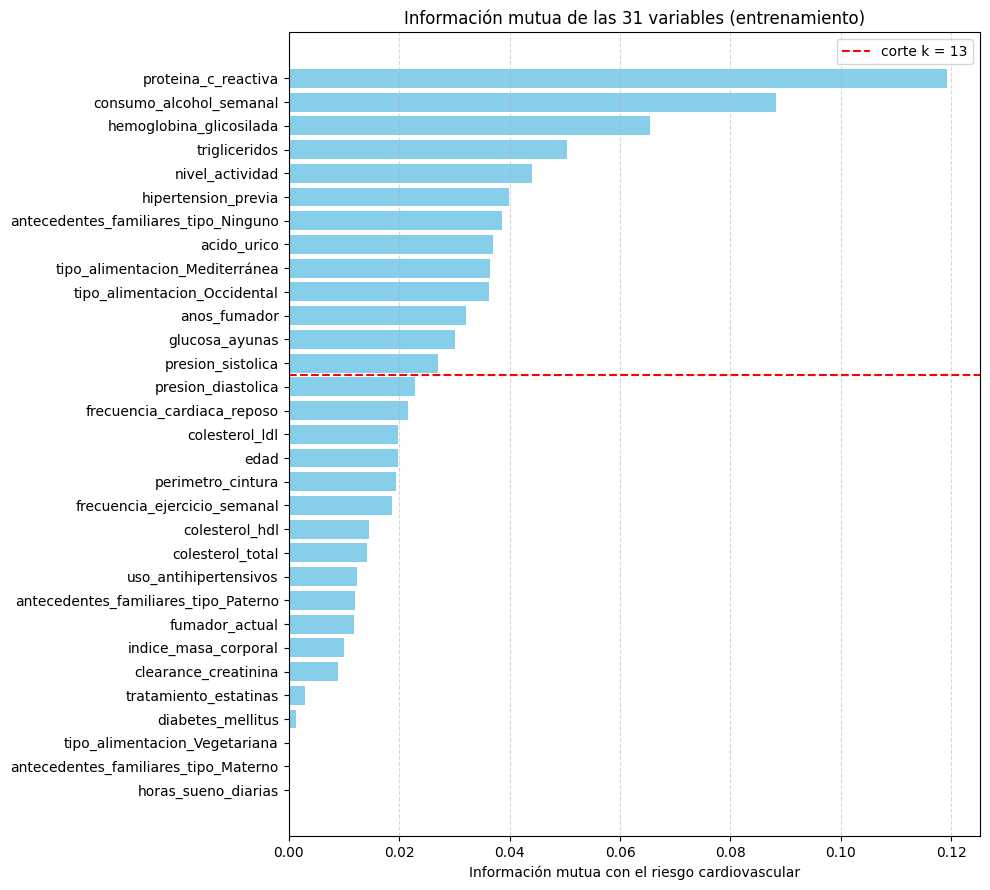

In [58]:
# Puntuación de información mutua de las 31 variables (descriptivo: ajustado con todo el entrenamiento,
# no interviene en ninguna decisión). La línea marca el corte de k = 13.
X_prep = preprocesador.fit_transform(X_train_procesado)
puntuaciones = pd.Series(mi(X_prep, y_train), index=X_prep.columns).sort_values()

plt.figure(figsize=(10, 9))
plt.barh(puntuaciones.index, puntuaciones.values, color="skyblue")
plt.axhline(len(puntuaciones) - 13 - 0.5, color="red", linestyle="--", label="corte k = 13")
plt.xlabel("Información mutua con el riesgo cardiovascular")
plt.title("Información mutua de las 31 variables (entrenamiento)")
plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Las puntuaciones de información mutua son bajas (la máxima, la de la proteina_c_reactiva, es 0,12) y muy próximas entre sí, y tres variables obtienen 0. Además, el orden no coincide con el del EDA: `uso_antihipertensivos`, la categórica más asociada al riesgo (V de Cramér = 0,237), queda en el puesto 22 de 31, y las horas de sueño (ρ = −0,14, p < 0,001) obtienen 0. Con señales tan débiles, la estimación de la información mutua no es fiable para descartar variables: otra razón para no seleccionar.

### 6.6 Desbalanceo

Las clases están desequilibradas de forma moderada: 50 % de riesgo bajo, 30 % moderado y 20 % alto (ratio 2,5:1). El riesgo es que el modelo favorezca la clase mayoritaria y detecte mal la clase de riesgo alto, que es justo la clínicamente crítica: un modelo que respondiera siempre "riesgo bajo" acertaría la mitad de las veces sin detectar a ningún paciente de riesgo alto.

Se comparan, con validación cruzada solo sobre el entrenamiento y dentro del mismo pipeline, cuatro estrategias:

- **Sin balanceo**, como referencia.
- **SMOTE**: genera pacientes sintéticos de las clases 1 y 2 hasta el 65 % de la mayoritaria. No se igualan del todo para no llenar el entrenamiento de pacientes sintéticos.
- **SMOTE-NC**: igual, pero trata las variables categóricas (booleanas e indicadoras) por votación entre vecinos, sin generar valores intermedios como 0,4 de diabetes.
- **`class_weight='balanced'`**: no genera pacientes; da más peso en el entrenamiento a los errores en las clases minoritarias. k-NN no lo admite.

Se usan dos modelos de referencia con sus valores por defecto: la regresión logística y k-NN. El remuestreo va dentro del pipeline, de modo que solo se aplica al entrenamiento de cada pliegue y nunca a los datos con los que se evalúa.

In [59]:
# ¿Cómo tratar el desbalanceo? Comparación con validación cruzada (solo entrenamiento),
# con el mismo pipeline y dos modelos de referencia con valores por defecto.
from imblearn.over_sampling import SMOTENC
from sklearn.neighbors import KNeighborsClassifier

# Posición de las columnas categóricas a la salida del preprocesador (para SMOTE-NC):
# primero van las escaladas y después el resto, en su orden original
orden = cols_a_escalar + [c for c in X_train_procesado.columns if c not in cols_a_escalar]
cat_idx = [orden.index(c) for c in COLS_BOOLEANAS + list(nombres_cols)]

estrategias = {
    "Sin balanceo": dict(smote="passthrough"),
    "SMOTE 65 %": dict(),
    "SMOTE-NC 65 %": dict(smote=SMOTENC(categorical_features=cat_idx,
                                         sampling_strategy=estrategia_smote,
                                         random_state=SEMILLA)),
    "class_weight='balanced'": dict(smote="passthrough", modelo__class_weight="balanced"),
}
modelos_referencia = {
    "Regresión logística": LogisticRegression(max_iter=1000, random_state=SEMILLA),
    "k-NN": KNeighborsClassifier(n_neighbors=15),
}

filas = []
for nombre_modelo, modelo in modelos_referencia.items():
    for nombre_estrategia, params in estrategias.items():
        if "modelo__class_weight" in params and "class_weight" not in modelo.get_params():
            continue  # k-NN no admite class_weight
        pipe = crear_pipeline(modelo).set_params(**params)
        res = cross_validate(pipe, X_train_procesado, y_train,
                             cv=validacion_cruzada, scoring=metricas, n_jobs=-1)
        filas.append({
            "Modelo": nombre_modelo,
            "Estrategia": nombre_estrategia,
            "F1-macro (media)": res["test_f1_macro"].mean(),
            "F1-macro (desv.)": res["test_f1_macro"].std(),
            "Recall C2 (media)": res["test_recall_c2"].mean(),
        })

display(pd.DataFrame(filas).set_index(["Modelo", "Estrategia"]).round(4))

F1-macro (media)  F1-macro (desv.)  Recall C2 (media)
Modelo              Estrategia                                                                    
Regresión logística Sin balanceo                       0.6687            0.0134             0.6981
                    SMOTE 65 %                         0.6584            0.0081             0.7674
                    SMOTE-NC 65 %                      0.6565            0.0061             0.7369
                    class_weight='balanced'            0.6571            0.0086             0.7618
k-NN                Sin balanceo                       0.5373            0.0190             0.4405
                    SMOTE 65 %                         0.5427            0.0099             0.7813
                    SMOTE-NC 65 %                      0.5376            0.0077             0.7534

**Resultado:**

- Sin balanceo, la regresión logística tiene el F1-macro más alto (0,6687), pero detecta peor el riesgo alto (0,6981 frente a 0,7674 con SMOTE). En k-NN, sin balanceo solo detecta al 44 % de los pacientes de riesgo alto.
- **SMOTE al 65 % es la mejor opción en los dos modelos:** la mayor sensibilidad del riesgo alto (0,7674 y 0,7813) con un F1-macro igual al de las demás estrategias.
- **`class_weight`** es similar a SMOTE en la regresión logística, pero k-NN no lo admite.
- **SMOTE-NC**, aunque se supone que es más correcto con variables categóricas, empata en F1-macro y detecta peor el riesgo alto (0,737 y 0,753).

**Decisión**: SMOTE al 65 % dentro del pipeline para los cinco modelos. Limitación asumida: SMOTE genera valores intermedios en las variables 0/1 de los pacientes sintéticos.

## 7. Diseño y entrenamiento de modelos

Se entrenan cinco modelos: dos modelos base (regresión logística y k-NN) y tres ensambles (Random Forest, HistGradientBoosting y stacking). Todos siguen el mismo procedimiento:

1. **Mismo pipeline** (`crear_pipeline`): imputación y escalado, SMOTE al 65 % y el modelo. Todo se ajusta solo con el entrenamiento de cada pliegue.
2. **Hiperparámetros elegidos con validación cruzada** (`GridSearchCV`, los mismos 5 pliegues estratificados), solo sobre el entrenamiento. Criterio único: **F1-macro**. También se registran la sensibilidad del riesgo alto y el F1-macro en entrenamiento, para detectar sobreajuste.
3. **Umbral del riesgo alto elegido sin el test.** El modelo predice riesgo alto si la probabilidad de esa clase alcanza un umbral. Ese umbral se elige con predicciones fuera de pliegue del entrenamiento: el que da mayor F1-macro entre los que detectan al menos al 80 % de los pacientes de riesgo alto. (Este 80 % es un criterio clínico fijado previamente).
4. **Evaluación final sobre el test una sola vez por modelo**, con los hiperparámetros y el umbral ya decididos.

# CODIGO V1 SIMPLIFICADO: EJECUTAR SOLO UN CODIGO V1 o V2

In [ ]:
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score,
                             classification_report, f1_score, recall_score)
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.base import clone

def buscar_hiperparametros(modelo, rejilla):
    busqueda = GridSearchCV(
        estimator=crear_pipeline(modelo),
        param_grid=rejilla,
        scoring=metricas,
        refit="f1_macro",
        cv=validacion_cruzada,
        return_train_score=True,
        n_jobs=-1,
        error_score="raise",
    )
    busqueda.fit(X_train_procesado, y_train)
    return busqueda

def tabla_busqueda(busqueda, n=6):
    res = pd.DataFrame(busqueda.cv_results_)
    res["hiperparámetros"] = res["params"].apply(
        lambda p: ", ".join(f"{k.split('__', 1)[-1]}={v}" for k, v in p.items()))
    res["diferencia F1 (entren. - valid.)"] = res["mean_train_f1_macro"] - res["mean_test_f1_macro"]
    columnas = {"hiperparámetros": "hiperparámetros",
                "mean_test_f1_macro": "F1-macro valid.",
                "std_test_f1_macro": "desv.",
                "mean_train_f1_macro": "F1-macro entren.",
                "diferencia F1 (entren. - valid.)": "diferencia F1 (entren. - valid.)",
                "mean_test_recall_c2": "Recall C2 valid."}
    return (res.sort_values("mean_test_f1_macro", ascending=False)[list(columnas)]
               .rename(columns=columnas).head(n).round(3))
    
    
def predecir_con_umbral(probabilidades, umbral):
    return np.where(
        probabilidades[:, 2] >= umbral,
        2,
        np.argmax(probabilidades[:, :2], axis=1)
    )
    

def elegir_umbral(busqueda, sensibilidad_minima=0.80):
    prob_oof = cross_val_predict(
        busqueda.best_estimator_, X_train_procesado, y_train,
        cv=validacion_cruzada, method="predict_proba", n_jobs=-1
    )

    filas = []
    for u in np.round(np.arange(0.20, 0.55, 0.05), 2):
        pred = predecir_con_umbral(prob_oof, u)
        filas.append({
            "umbral": u,
            "F1-macro": f1_score(y_train, pred, average="macro"),
            "Recall C2": recall_score(
                y_train, pred, labels=[2], average="macro"
            )
        })

    tabla = pd.DataFrame(filas).set_index("umbral")
    candidatos = tabla[tabla["Recall C2"] >= sensibilidad_minima]

    if candidatos.empty:
        print("AVISO: Ningún umbral alcanza la sensibilidad mínima.")
        umbral = tabla["Recall C2"].idxmax()
    else:
        umbral = candidatos["F1-macro"].idxmax()

    return umbral, tabla.round(3)


def evaluar_en_test(busqueda, umbral, titulo):
    pred = predecir_con_umbral(
        busqueda.predict_proba(X_test_procesado), umbral
    )

    print(f"--- {titulo}: evaluación final sobre TEST (umbral C2 = {umbral}) ---")
    print(classification_report(y_test, pred, digits=4, zero_division=0))
    print(f"Balanced accuracy: {balanced_accuracy_score(y_test, pred):.4f}")

    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        labels=[0, 1, 2],
        cmap="Blues",
        ax=ax,
        display_labels=["0 (Bajo)", "1 (Moderado)", "2 (Alto)"]
    )

    plt.title(f"Matriz de confusión - {titulo} (test)")
    plt.tight_layout()
    plt.show()

    return pred

# CODIGO V2 LARGO: EJECUTAR SOLO UN CODIGO V1 o V2

In [60]:
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score,
                             classification_report, f1_score, recall_score)
from sklearn.model_selection import GridSearchCV, cross_val_predict
from sklearn.base import clone

def buscar_hiperparametros(modelo, rejilla):

    busqueda = GridSearchCV(
        estimator=crear_pipeline(modelo),
        param_grid=rejilla,
        scoring=metricas,
        refit="f1_macro",
        cv=validacion_cruzada,
        n_jobs=-1,
        return_train_score=True,
        error_score="raise"
    )

    # datos del apartado 6 (sin imputar y con log1p de la PCR)
    busqueda.fit(X_train_procesado, y_train)

    mejor = busqueda.best_index_

    print("Mejores hiperparámetros:")
    print(busqueda.best_params_)

    print(
        f"F1-macro CV: "
        f"{busqueda.cv_results_['mean_test_f1_macro'][mejor]:.4f}"
    )

    print(
        f"F1-macro entrenamiento: "
        f"{busqueda.cv_results_['mean_train_f1_macro'][mejor]:.4f}"
    )

    print(
        f"Recall C2 CV: "
        f"{busqueda.cv_results_['mean_test_recall_c2'][mejor]:.4f}"
    )

    return busqueda

def tabla_busqueda(busqueda, n=10):

    resultados = pd.DataFrame(busqueda.cv_results_)

    columnas = [
        "params",
        "mean_test_f1_macro",
        "mean_train_f1_macro",
        "mean_test_recall_c2",
        "std_test_f1_macro"
    ]

    tabla = resultados[columnas].copy()

    tabla = tabla.rename(columns={
        "params": "Hiperparámetros",
        "mean_test_f1_macro": "F1-macro CV",
        "mean_train_f1_macro": "F1-macro Train",
        "mean_test_recall_c2": "Recall C2 CV",
        "std_test_f1_macro": "Desv. F1 CV"
    })

    tabla = (
        tabla.sort_values(
            "F1-macro CV",
            ascending=False
        )
        .head(n)
        .reset_index(drop=True)
    )

    display(tabla.round(4))

    return tabla

def predecir_con_umbral(probabilidades, umbral):

    probabilidades = np.asarray(probabilidades)

    if probabilidades.ndim != 2 or probabilidades.shape[1] != 3:
        raise ValueError(
            "Se esperan probabilidades de las clases [0, 1, 2]."
        )

    if not 0 <= umbral <= 1:
        raise ValueError("El umbral debe estar entre 0 y 1.")

    predicciones = np.argmax(
        probabilidades[:, :2],
        axis=1
    )

    predicciones[
        probabilidades[:, 2] >= umbral
    ] = 2

    return predicciones

def elegir_umbral(busqueda, sensibilidad_minima=0.80):

    if not 0 <= sensibilidad_minima <= 1:
        raise ValueError(
            "La sensibilidad mínima debe estar entre 0 y 1."
        )

    # Modelo con los hiperparámetros seleccionados
    modelo = clone(busqueda.best_estimator_)

    # Predicciones fuera de pliegue SOLO en entrenamiento
    probabilidades_oof = cross_val_predict(
        modelo,
        X_train_procesado,   # CAMBIO
        y_train,
        cv=validacion_cruzada,
        method="predict_proba",
        n_jobs=-1
    )

    # Evaluar todos los umbrales relevantes.
    # Las predicciones solo cambian al cruzar una probabilidad.
    umbrales = np.unique(
        np.concatenate((
            [0.0, 1.0],
            probabilidades_oof[:, 2]
        ))
    )

    resultados = []

    for umbral in umbrales:

        predicciones = predecir_con_umbral(
            probabilidades_oof,
            umbral
        )

        f1 = f1_score(
            y_train,
            predicciones,
            average="macro",
            zero_division=0
        )

        recall_c2 = recall_score(
            y_train,
            predicciones,
            labels=[2],
            average="macro",
            zero_division=0
        )

        resultados.append({
            "Umbral": umbral,
            "F1-macro": f1,
            "Recall C2": recall_c2
        })

    tabla = pd.DataFrame(resultados)

    # Conservar umbrales que cumplen la sensibilidad mínima
    candidatos = tabla[
        tabla["Recall C2"] >= sensibilidad_minima
    ]

    if candidatos.empty:
        raise ValueError(
            "Ningún umbral alcanza la sensibilidad mínima."
        )

    # Mayor F1-macro; en empate, mayor recall C2
    mejor = candidatos.sort_values(
        ["F1-macro", "Recall C2", "Umbral"],
        ascending=[False, False, False]
    ).iloc[0]

    umbral_optimo = float(mejor["Umbral"])

    print(f"Umbral elegido: {umbral_optimo:.4f}")
    print(f"F1-macro OOF: {mejor['F1-macro']:.4f}")
    print(f"Recall C2 OOF: {mejor['Recall C2']:.4f}")

    return umbral_optimo, tabla

def evaluar_en_test(busqueda, umbral, titulo):

    modelo = busqueda.best_estimator_

    # Comprobar el orden de las clases
    if not np.array_equal(
        modelo.classes_,
        [0, 1, 2]
    ):
        raise ValueError(
            "Se esperan las clases [0, 1, 2]."
        )

    # Probabilidades en test
    probabilidades = modelo.predict_proba(X_test_procesado)   # CAMBIO

    # Aplicar el umbral elegido en entrenamiento
    predicciones = predecir_con_umbral(
        probabilidades,
        umbral
    )

    # Métricas
    f1 = f1_score(
        y_test,
        predicciones,
        average="macro",
        zero_division=0
    )

    recall_c2 = recall_score(
        y_test,
        predicciones,
        labels=[2],
        average="macro",
        zero_division=0
    )

    print(f"\n--- {titulo} ---")
    print(f"Umbral C2: {umbral:.4f}")
    print(f"F1-macro test: {f1:.4f}")
    print(f"Recall C2 test: {recall_c2:.4f}")
    print(f"Balanced accuracy test: {balanced_accuracy_score(y_test, predicciones):.4f}")

    print("\nReporte de clasificación:")
    print(classification_report(
        y_test,
        predicciones,
        digits=4,
        zero_division=0
    ))

    # Matriz de confusión
    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones,
        labels=[0, 1, 2],
        display_labels=[
            "0 (Bajo)",
            "1 (Medio)",
            "2 (Alto)"
        ],
        cmap="Blues",
        ax=ax
    )

    plt.title(f"Matriz de confusión - {titulo}")
    plt.tight_layout()
    plt.show()

    # CAMBIO: devuelve las predicciones, que usan las comparativas del apartado 8
    return predicciones

### 7.1 Regresión logística

In [61]:
# Regresión logística: búsqueda de hiperparámetros con validación cruzada (solo entrenamiento)
from sklearn.linear_model import LogisticRegression

rejilla_lr = {
    "modelo__C": [0.01, 0.1, 1.0, 10.0],   # inversa de la regularización: C pequeño = coeficientes más pequeños
    "modelo__solver": ["lbfgs", "newton-cg"],
}

busqueda_lr = buscar_hiperparametros(
    LogisticRegression(max_iter=1000, random_state=SEMILLA), rejilla_lr)

print("Mejores hiperparámetros:", busqueda_lr.best_params_)
display(tabla_busqueda(busqueda_lr))

Mejores hiperparámetros:
{'modelo__C': 10.0, 'modelo__solver': 'lbfgs'}
F1-macro CV: 0.6611
F1-macro entrenamiento: 0.6798
Recall C2 CV: 0.7673
Mejores hiperparámetros: {'modelo__C': 10.0, 'modelo__solver': 'lbfgs'}


,Hiperparámetros,F1-macro CV,F1-macro Train,Recall C2 CV,Desv. F1 CV
0,"{'modelo__C': 10.0, 'modelo__solver': 'lbfgs'}",0.6611,0.6798,0.7673,0.0093
1,"{'modelo__C': 10.0, 'modelo__solver': 'newton-...",0.6607,0.6799,0.7673,0.0080
2,"{'modelo__C': 1.0, 'modelo__solver': 'lbfgs'}",0.6584,0.6796,0.7674,0.0081
3,"{'modelo__C': 1.0, 'modelo__solver': 'newton-cg'}",0.6580,0.6797,0.7674,0.0083
4,"{'modelo__C': 0.1, 'modelo__solver': 'lbfgs'}",0.6557,0.6757,0.7701,0.0099
5,"{'modelo__C': 0.1, 'modelo__solver': 'newton-cg'}",0.6557,0.6759,0.7701,0.0099
6,"{'modelo__C': 0.01, 'modelo__solver': 'lbfgs'}",0.6186,0.6450,0.7784,0.0185
7,"{'modelo__C': 0.01, 'modelo__solver': 'newton-...",0.6186,0.6449,0.7784,0.0185


,Hiperparámetros,F1-macro CV,F1-macro Train,Recall C2 CV,Desv. F1 CV
0,"{'modelo__C': 10.0, 'modelo__solver': 'lbfgs'}",0.661064,0.679786,0.767314,0.009327
1,"{'modelo__C': 10.0, 'modelo__solver': 'newton-...",0.660663,0.679948,0.767314,0.007956
2,"{'modelo__C': 1.0, 'modelo__solver': 'lbfgs'}",0.658363,0.679551,0.767352,0.008121
3,"{'modelo__C': 1.0, 'modelo__solver': 'newton-cg'}",0.657982,0.679687,0.767352,0.008279
4,"{'modelo__C': 0.1, 'modelo__solver': 'lbfgs'}",0.655698,0.675671,0.770129,0.009884
5,"{'modelo__C': 0.1, 'modelo__solver': 'newton-cg'}",0.655698,0.675868,0.770129,0.009884
6,"{'modelo__C': 0.01, 'modelo__solver': 'lbfgs'}",0.618590,0.645015,0.778425,0.018475
7,"{'modelo__C': 0.01, 'modelo__solver': 'newton-...",0.618590,0.644892,0.778425,0.018475


In [62]:
# Umbral de decisión para el riesgo alto, elegido SOLO con el entrenamiento
umbral_lr, tabla_umbral_lr = elegir_umbral(busqueda_lr)
display(tabla_umbral_lr)
print("Umbral elegido:", umbral_lr)

Umbral elegido: 0.3611
F1-macro OOF: 0.6503
Recall C2 OOF: 0.8006


,Umbral,F1-macro,Recall C2
0,0.000000,0.111368,1.00000
1,0.000001,0.111368,1.00000
2,0.000003,0.112160,1.00000
3,0.000003,0.112211,1.00000
4,0.000004,0.113001,1.00000
...,...,...,...
1797,0.994846,0.446902,0.01108
1798,0.996643,0.444967,0.00831
1799,0.997694,0.443022,0.00554
1800,0.999199,0.441067,0.00277


Umbral elegido: 0.3610841939816773



--- Regresión logística ---
Umbral C2: 0.3611
F1-macro test: 0.6561
Recall C2 test: 0.8444
Balanced accuracy test: 0.6844

Reporte de clasificación:
              precision    recall  f1-score   support

           0     0.8202    0.8311    0.8256       225
           1     0.5426    0.3778    0.4454       135
           2     0.5938    0.8444    0.6972        90

    accuracy                         0.6978       450
   macro avg     0.6522    0.6844    0.6561       450
weighted avg     0.6916    0.6978    0.6859       450



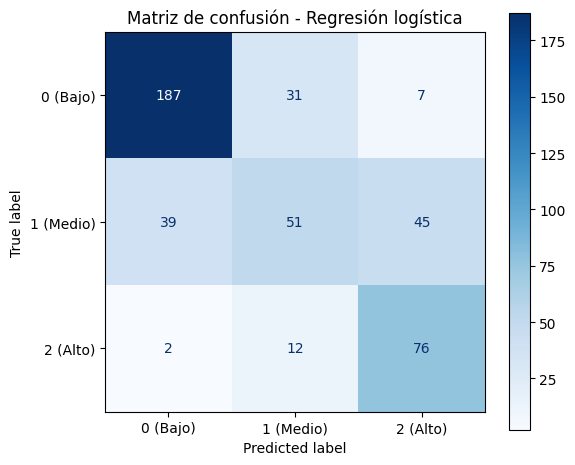

In [63]:
# Evaluación final sobre el test (una sola vez)
y_test_pred_lr = evaluar_en_test(busqueda_lr, umbral_lr, "Regresión logística")

### 7.2 K-NN

In [64]:
from sklearn.neighbors import KNeighborsClassifier

rejilla_knn = {
    "modelo__n_neighbors": [5, 11, 15, 21, 31, 41, 51],  # cuántos pacientes parecidos se consultan
    "modelo__weights": ["uniform", "distance"],          # uniform: todos votan igual; distance: los más cercanos pesan más
    "modelo__metric": ["euclidean", "manhattan"],        # cómo se mide la distancia entre pacientes
}

busqueda_knn = buscar_hiperparametros(KNeighborsClassifier(), rejilla_knn)

print("Mejores hiperparámetros:", busqueda_knn.best_params_)
display(tabla_busqueda(busqueda_knn))

Mejores hiperparámetros:
{'modelo__metric': 'manhattan', 'modelo__n_neighbors': 31, 'modelo__weights': 'distance'}
F1-macro CV: 0.5923
F1-macro entrenamiento: 1.0000
Recall C2 CV: 0.7755
Mejores hiperparámetros: {'modelo__metric': 'manhattan', 'modelo__n_neighbors': 31, 'modelo__weights': 'distance'}


,Hiperparámetros,F1-macro CV,F1-macro Train,Recall C2 CV,Desv. F1 CV
0,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.5923,1.0000,0.7755,0.0201
1,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.5828,0.6445,0.7257,0.0181
2,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.5825,0.6275,0.7617,0.0202
3,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.5823,0.6103,0.8171,0.0228
4,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.5800,1.0000,0.8254,0.0244
5,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.5792,1.0000,0.7396,0.0136
6,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.5761,1.0000,0.7174,0.0143
7,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.5696,0.6531,0.6925,0.0189
8,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.5677,1.0000,0.8198,0.0254
9,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.5657,1.0000,0.6787,0.0234


,Hiperparámetros,F1-macro CV,F1-macro Train,Recall C2 CV,Desv. F1 CV
0,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.592310,1.000000,0.775533,0.020064
1,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.582815,0.644547,0.725685,0.018062
2,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.582541,0.627452,0.761720,0.020248
3,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.582330,0.610276,0.817085,0.022806
4,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.580045,1.000000,0.825381,0.024391
5,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.579241,1.000000,0.739574,0.013557
6,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.576097,1.000000,0.717352,0.014252
7,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.569629,0.653108,0.692466,0.018875
8,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.567724,1.000000,0.819787,0.025399
9,"{'modelo__metric': 'manhattan', 'modelo__n_nei...",0.565744,1.000000,0.678653,0.023396


In [65]:
umbral_knn, tabla_umbral_knn = elegir_umbral(busqueda_knn)
display(tabla_umbral_knn)
print("Umbral elegido:", umbral_knn)

Umbral elegido: 0.3737
F1-macro OOF: 0.5873
Recall C2 OOF: 0.8061


,Umbral,F1-macro,Recall C2
0,0.000000,0.111368,1.00000
1,0.029303,0.237699,1.00000
2,0.029395,0.238260,1.00000
3,0.029451,0.238820,1.00000
4,0.029570,0.239380,1.00000
...,...,...,...
1585,0.934228,0.395872,0.01108
1586,0.935605,0.393945,0.00831
1587,0.938931,0.392007,0.00554
1588,0.968433,0.390060,0.00277


Umbral elegido: 0.37371961945151766



--- k-NN ---
Umbral C2: 0.3737
F1-macro test: 0.6214
Recall C2 test: 0.8333
Balanced accuracy test: 0.6615

Reporte de clasificación:
              precision    recall  f1-score   support

           0     0.7773    0.8844    0.8274       225
           1     0.6207    0.2667    0.3731       135
           2     0.5515    0.8333    0.6637        90

    accuracy                         0.6889       450
   macro avg     0.6498    0.6615    0.6214       450
weighted avg     0.6852    0.6889    0.6584       450



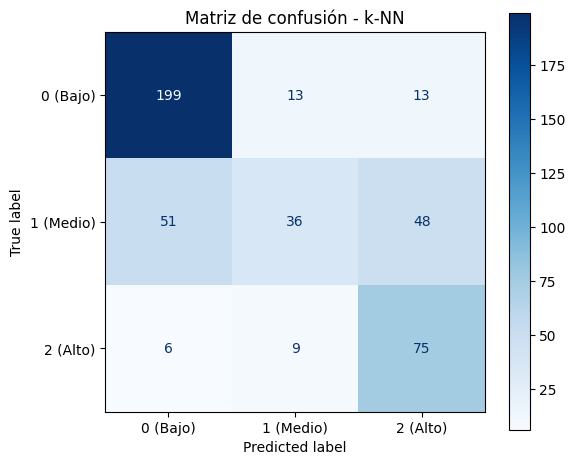

In [66]:
# Evaluación final sobre el test (una sola vez)
y_test_pred_knn = evaluar_en_test(busqueda_knn, umbral_knn, "k-NN")

La regresión logística obtiene mejores resultados que k-NN tanto en validación cruzada (F1-macro 0,661 frente a 0,592) como en el conjunto de prueba (0,656 frente a 0,621). Ambos modelos identifican prácticamente el mismo número de pacientes de riesgo alto (76 frente a 75), pero la regresión logística clasifica mejor a los pacientes de riesgo moderado (38 % frente a 27 %). Además, k-NN alcanza un F1-macro de 1 en entrenamiento, señal de que se ajusta en exceso a los datos utilizados para aprender. Por todo ello, se selecciona la regresión logística.

Una vez trabajado con los modelos básicos, vamos a empezar a trabajar con los modelos de Ensamble.

### 7.3 Random Forest

El primer ensamble, de tipo *bagging*, entrena árboles de decisión sobre distintas muestras de pacientes y variables, y después combina sus predicciones mediante votación. Al combinar múltiples árboles se reducen los errores debidos al azar y se pueden detectar relaciones complejas entre variables que la regresión logística podría no captar. Aunque este modelo no requiere escalado de las variables, se mantiene el mismo pipeline de preprocesamiento para facilitar la comparación con el resto de modelos.

Durante el ajuste se evalúan varios parámetros: el número de árboles, su profundidad máxima, el número mínimo de pacientes por hoja (que controla la complejidad del árbol) y la utilización de pesos para compensar el desbalanceo de clases (balanced_subsample), además del equilibrio ya introducido mediante SMOTE.

In [67]:
# 7.3 Random Forest: búsqueda de hiperparámetros con validación cruzada (solo entrenamiento)
from sklearn.ensemble import RandomForestClassifier

rejilla_rf = {
    "modelo__n_estimators": [100, 200, 300],             # número de árboles
    "modelo__max_depth": [5, 10, 15, None],              # profundidad máxima de cada árbol
    "modelo__min_samples_leaf": [2, 5, 10],              # pacientes mínimos por hoja
    "modelo__class_weight": [None, "balanced_subsample"],
}

busqueda_rf = buscar_hiperparametros(
    RandomForestClassifier(max_features="sqrt", random_state=SEMILLA, n_jobs=-1), rejilla_rf)

print("Mejores hiperparámetros:", busqueda_rf.best_params_)
display(tabla_busqueda(busqueda_rf))

Mejores hiperparámetros:
{'modelo__class_weight': 'balanced_subsample', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}
F1-macro CV: 0.6447
F1-macro entrenamiento: 0.9730
Recall C2 CV: 0.6788
Mejores hiperparámetros: {'modelo__class_weight': 'balanced_subsample', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300}


,Hiperparámetros,F1-macro CV,F1-macro Train,Recall C2 CV,Desv. F1 CV
0,"{'modelo__class_weight': 'balanced_subsample',...",0.6447,0.9730,0.6788,0.0193
1,"{'modelo__class_weight': 'balanced_subsample',...",0.6440,0.9193,0.6926,0.0194
2,"{'modelo__class_weight': 'balanced_subsample',...",0.6430,0.9190,0.6954,0.0190
3,"{'modelo__class_weight': 'balanced_subsample',...",0.6412,0.9133,0.7091,0.0182
4,"{'modelo__class_weight': 'balanced_subsample',...",0.6411,0.9131,0.7119,0.0181
5,"{'modelo__class_weight': 'balanced_subsample',...",0.6409,0.9143,0.7119,0.0189
6,"{'modelo__class_weight': 'balanced_subsample',...",0.6405,0.9192,0.7119,0.0217
7,"{'modelo__class_weight': 'balanced_subsample',...",0.6399,0.9191,0.7092,0.0198
8,"{'modelo__class_weight': 'balanced_subsample',...",0.6388,0.9694,0.6759,0.0233
9,"{'modelo__class_weight': 'balanced_subsample',...",0.6374,0.9946,0.6760,0.0083


,Hiperparámetros,F1-macro CV,F1-macro Train,Recall C2 CV,Desv. F1 CV
0,"{'modelo__class_weight': 'balanced_subsample',...",0.644710,0.973011,0.678767,0.019269
1,"{'modelo__class_weight': 'balanced_subsample',...",0.643996,0.919315,0.692580,0.019377
2,"{'modelo__class_weight': 'balanced_subsample',...",0.642965,0.918981,0.695358,0.019005
3,"{'modelo__class_weight': 'balanced_subsample',...",0.641185,0.913337,0.709132,0.018243
4,"{'modelo__class_weight': 'balanced_subsample',...",0.641106,0.913149,0.711872,0.018126
5,"{'modelo__class_weight': 'balanced_subsample',...",0.640883,0.914305,0.711948,0.018906
6,"{'modelo__class_weight': 'balanced_subsample',...",0.640503,0.919191,0.711948,0.021683
7,"{'modelo__class_weight': 'balanced_subsample',...",0.639911,0.919128,0.709209,0.019816
8,"{'modelo__class_weight': 'balanced_subsample',...",0.638787,0.969432,0.675875,0.023345
9,"{'modelo__class_weight': 'balanced_subsample',...",0.637385,0.994604,0.675989,0.008274


- La mejor configuración utiliza 300 árboles, profundidad máxima 10, un mínimo de 5 pacientes por hoja y compensación de clases mediante class_weight='balanced_subsample'. Con ella se obtiene un F1-macro de 0,645 en validación cruzada.
- Todas las configuraciones con mejores resultados emplean balanced_subsample, lo que indica que los pesos de clase siguen siendo útiles incluso después de aplicar SMOTE. Mientras que SMOTE reduce parcialmente el desequilibrio entre clases, los pesos completan ese ajuste.
- Las diferencias entre las mejores configuraciones son muy pequeñas. De hecho, los diez mejores modelos obtienen valores de F1-macro entre 0,637 y 0,645, una variación menor que la observada de forma natural entre los distintos pliegues de la validación cruzada. Esto sugiere que el resto de hiperparámetros tiene una influencia limitada en el rendimiento.
- Se observa un sobreajuste importante: el F1-macro pasa de 0,973 en entrenamiento a 0,645 en validación. Existen configuraciones con un rendimiento muy similar en validación y un menor ajuste al conjunto de entrenamiento. Por ejemplo, la segunda mejor configuración alcanza 0,644 en validación frente a 0,919 en entrenamiento. Aun así, se mantiene el criterio de seleccionar el modelo con mayor F1-macro en validación, aunque cualquiera de estas alternativas sería razonable.

In [68]:
# Umbral de decisión para el riesgo alto, elegido SOLO con el entrenamiento
umbral_rf, tabla_umbral_rf = elegir_umbral(busqueda_rf)
display(tabla_umbral_rf)
print("Umbral elegido:", umbral_rf)

Umbral elegido: 0.3295
F1-macro OOF: 0.6373
Recall C2 OOF: 0.8006


,Umbral,F1-macro,Recall C2
0,0.000000,0.111368,1.00000
1,0.008020,0.111368,1.00000
2,0.009826,0.112160,1.00000
3,0.012232,0.112951,1.00000
4,0.015097,0.113740,1.00000
...,...,...,...
1797,0.790490,0.434753,0.01108
1798,0.804004,0.432822,0.00831
1799,0.811372,0.430882,0.00554
1800,0.898811,0.428931,0.00277


Umbral elegido: 0.32949531715611696


Con el mismo criterio que en los modelos anteriores, el umbral elegido es 0,33: F1-macro 0,637 y sensibilidad 0,801 en las predicciones fuera de pliegue.


--- Random Forest ---
Umbral C2: 0.3295
F1-macro test: 0.6357
Recall C2 test: 0.8667
Balanced accuracy test: 0.6696

Reporte de clasificación:
              precision    recall  f1-score   support

           0     0.7759    0.8311    0.8026       225
           1     0.5185    0.3111    0.3889       135
           2     0.6094    0.8667    0.7156        90

    accuracy                         0.6822       450
   macro avg     0.6346    0.6696    0.6357       450
weighted avg     0.6654    0.6822    0.6611       450



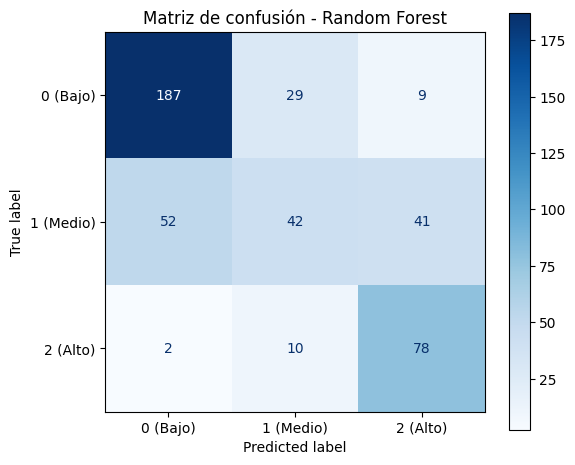

In [69]:
# Evaluación final sobre el test (una sola vez)
y_test_pred_rf = evaluar_en_test(busqueda_rf, umbral_rf, "Random Forest")

En el conjunto de prueba, Random Forest obtiene un F1-macro de 0,636 y detecta correctamente 78 de los 90 pacientes de riesgo alto (86,7 %), siendo el modelo que mejor identifica esta categoría. Además, alcanza una balanced accuracy de 0,670.

Sin embargo, su rendimiento global sigue siendo algo inferior al de la regresión logística, tanto en validación cruzada (0,645 frente a 0,661) como en el conjunto de prueba (0,636 frente a 0,656). Su principal debilidad es la identificación de los pacientes de riesgo moderado, ya que solo clasifica correctamente el 31 % de los casos, el segundo peor resultado de los modelos evaluados, únicamente por delante de k-NN.

### 7.4 Boosting

El segundo ensamble, de tipo *boosting*, es HistGradientBoosting. Si lo comparamos con Random Forest, que reduce la varianza promediando árboles independientes, el *boosting* reduce el sesgo de forma progresiva, a cambio de un mayor riesgo de sobreajuste. 

Se ajustan la tasa de aprendizaje (cuánto corrige cada árbol), el número de árboles, su profundidad, los pacientes mínimos por hoja, la regularización L2 y los pesos de clase.

In [70]:
# 7.4 HistGradientBoosting: búsqueda de hiperparámetros con validación cruzada (solo entrenamiento)
from sklearn.ensemble import HistGradientBoostingClassifier

rejilla_hgb = {
    "modelo__learning_rate": [0.03, 0.05, 0.1],  # cuánto corrige cada árbol los errores de los anteriores
    "modelo__max_iter": [150, 300],              # número de árboles (iteraciones de boosting)
    "modelo__max_depth": [4, 6, 8],              # profundidad de cada árbol: interacciones que puede captar
    "modelo__min_samples_leaf": [5, 10, 20],     # pacientes mínimos por hoja
    "modelo__l2_regularization": [0.0, 2.0],     # penalización de los valores de las hojas
    "modelo__class_weight": [None, "balanced"],
}
busqueda_hgb = buscar_hiperparametros(
    HistGradientBoostingClassifier(random_state=SEMILLA), rejilla_hgb)

print("Mejores hiperparámetros:", busqueda_hgb.best_params_)
display(tabla_busqueda(busqueda_hgb))

Mejores hiperparámetros:
{'modelo__class_weight': 'balanced', 'modelo__l2_regularization': 0.0, 'modelo__learning_rate': 0.03, 'modelo__max_depth': 4, 'modelo__max_iter': 300, 'modelo__min_samples_leaf': 10}
F1-macro CV: 0.6571
F1-macro entrenamiento: 0.9933
Recall C2 CV: 0.6677
Mejores hiperparámetros: {'modelo__class_weight': 'balanced', 'modelo__l2_regularization': 0.0, 'modelo__learning_rate': 0.03, 'modelo__max_depth': 4, 'modelo__max_iter': 300, 'modelo__min_samples_leaf': 10}


,Hiperparámetros,F1-macro CV,F1-macro Train,Recall C2 CV,Desv. F1 CV
0,"{'modelo__class_weight': 'balanced', 'modelo__...",0.6571,0.9933,0.6677,0.0210
1,"{'modelo__class_weight': 'balanced', 'modelo__...",0.6556,0.9789,0.6675,0.0187
2,"{'modelo__class_weight': 'balanced', 'modelo__...",0.6551,0.9460,0.6842,0.0179
3,"{'modelo__class_weight': 'balanced', 'modelo__...",0.6550,0.9872,0.6761,0.0248
4,"{'modelo__class_weight': 'balanced', 'modelo__...",0.6534,0.9847,0.6649,0.0314
5,"{'modelo__class_weight': 'balanced', 'modelo__...",0.6524,0.9685,0.6925,0.0231
6,"{'modelo__class_weight': None, 'modelo__l2_reg...",0.6523,1.0000,0.6621,0.0239
7,"{'modelo__class_weight': None, 'modelo__l2_reg...",0.6521,0.9988,0.6594,0.0218
8,"{'modelo__class_weight': 'balanced', 'modelo__...",0.6513,0.9768,0.6897,0.0235
9,"{'modelo__class_weight': 'balanced', 'modelo__...",0.6512,0.9818,0.6815,0.0156


,Hiperparámetros,F1-macro CV,F1-macro Train,Recall C2 CV,Desv. F1 CV
0,"{'modelo__class_weight': 'balanced', 'modelo__...",0.657127,0.993311,0.667656,0.020967
1,"{'modelo__class_weight': 'balanced', 'modelo__...",0.655552,0.978873,0.667542,0.018730
2,"{'modelo__class_weight': 'balanced', 'modelo__...",0.655063,0.946033,0.684247,0.017891
3,"{'modelo__class_weight': 'balanced', 'modelo__...",0.654966,0.987243,0.676104,0.024764
4,"{'modelo__class_weight': 'balanced', 'modelo__...",0.653380,0.984704,0.664878,0.031431
5,"{'modelo__class_weight': 'balanced', 'modelo__...",0.652428,0.968540,0.692542,0.023097
6,"{'modelo__class_weight': None, 'modelo__l2_reg...",0.652335,1.000000,0.662139,0.023931
7,"{'modelo__class_weight': None, 'modelo__l2_reg...",0.652140,0.998818,0.659437,0.021758
8,"{'modelo__class_weight': 'balanced', 'modelo__...",0.651323,0.976798,0.689726,0.023490
9,"{'modelo__class_weight': 'balanced', 'modelo__...",0.651176,0.981832,0.681545,0.015644


- La mejor configuración utiliza una tasa de aprendizaje de 0,03, 300 árboles con profundidad 4, un mínimo de 10 pacientes por hoja, sin regularización L2 y con compensación de clases mediante class_weight='balanced'. Con ella se obtiene un F1-macro de 0,657 en validación cruzada.
- Los hiperparámetros tienen muy poca influencia en el rendimiento. Las diferencias observadas entre configuraciones son pequeñas y menores que la variación normal entre los distintos pliegues de la validación cruzada. Aunque la profundidad de los árboles es el parámetro que más influye, muchas configuraciones obtienen resultados prácticamente idénticos. Además, los pesos de clase apenas aportan mejora, ya que SMOTE ya corrige buena parte del desequilibrio entre clases.
- Se observa un sobreajuste importante: el modelo alcanza un F1-macro de 0,993 en entrenamiento, pero baja a 0,657 en validación. Esto indica que aprende muy bien los datos de entrenamiento, incluidos los pacientes sintéticos generados por SMOTE, aunque parte de ese rendimiento no se mantiene en datos no vistos. La regularización L2 reduce ligeramente este efecto, pero apenas modifica los resultados de validación. Por ello, la selección final se basa en el F1-macro obtenido durante la validación cruzada.

In [71]:
# Umbral de decisión para el riesgo alto, elegido SOLO con el entrenamiento
umbral_hgb, tabla_umbral_hgb = elegir_umbral(busqueda_hgb)
display(tabla_umbral_hgb)
print("Umbral elegido:", umbral_hgb)

Umbral elegido: 0.2723
F1-macro OOF: 0.6465
Recall C2 OOF: 0.8006


,Umbral,F1-macro,Recall C2
0,0.000000,0.111368,1.00000
1,0.000007,0.111368,1.00000
2,0.000012,0.112160,1.00000
3,0.000015,0.112951,1.00000
4,0.000023,0.113740,1.00000
...,...,...,...
1797,0.989998,0.442875,0.01108
1798,0.991859,0.440941,0.00831
1799,0.995918,0.438997,0.00554
1800,0.996719,0.437044,0.00277


Umbral elegido: 0.27232446463733084


Con el criterio común (mayor F1-macro entre los umbrales que detectan al menos al 80 % del riesgo alto), se selecciona un umbral de 0,27, ya que es el que consigue el mejor equilibrio entre rendimiento global y detección de pacientes de riesgo alto. Con este valor se obtiene un F1-macro de 0,647 y una sensibilidad del 80,1 %, es decir, identifica correctamente aproximadamente 8 de cada 10 pacientes de riesgo alto.

Este es el umbral más bajo de los modelos evaluados. Esto indica que el modelo suele asignar probabilidades relativamente bajas a la clase de riesgo alto, por lo que es necesario reducir bastante el umbral de decisión para alcanzar el objetivo de detectar al menos el 80 % de estos pacientes.


--- HistGradientBoosting ---
Umbral C2: 0.2723
F1-macro test: 0.6332
Recall C2 test: 0.7889
Balanced accuracy test: 0.6585

Reporte de clasificación:
              precision    recall  f1-score   support

           0     0.8235    0.8089    0.8161       225
           1     0.5050    0.3778    0.4322       135
           2     0.5547    0.7889    0.6514        90

    accuracy                         0.6756       450
   macro avg     0.6277    0.6585    0.6332       450
weighted avg     0.6742    0.6756    0.6680       450



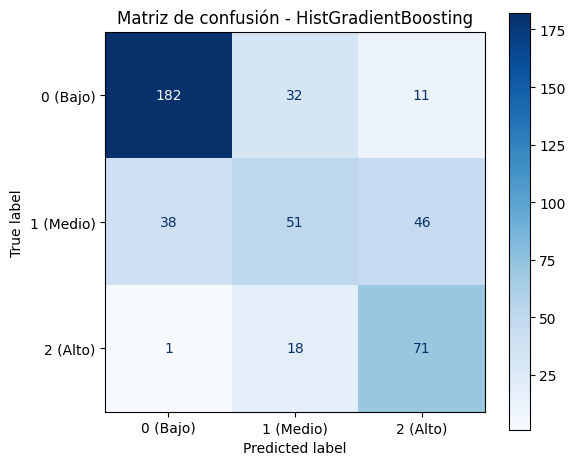

In [73]:
# Evaluación final sobre el test (una sola vez)
y_test_pred_hgb = evaluar_en_test(busqueda_hgb, umbral_hgb, "HistGradientBoosting")

En el conjunto de prueba, HistGradientBoosting obtiene un F1-macro de 0,633 y detecta correctamente 71 de los 90 pacientes de riesgo alto (78,9 %), con una balanced accuracy de 0,659.

Es el único de los modelos evaluados que no alcanza el objetivo de identificar al menos el 80 % de los pacientes de riesgo alto. Esto ocurre porque el umbral seleccionado ya se encontraba muy cerca de ese límite durante el entrenamiento (80,1 %), por lo que unas pocas predicciones diferentes en el conjunto de prueba bastan para situarlo por debajo.

Además, sus resultados son inferiores a los de la regresión logística tanto en validación cruzada (0,657 frente a 0,661) como en el conjunto de prueba (0,633 frente a 0,656). También detecta menos pacientes de riesgo alto (71 frente a 76). A ello se suma que es el modelo que muestra un mayor sobreajuste y uno de los más difíciles de interpretar.

### 7.5 Stacking

El tercer modelo de tipo ensemble combina las predicciones de otros modelos en lugar de trabajar directamente con los datos originales. Para ello utiliza como modelos base los mejores obtenidos anteriormente: Random Forest e HistGradientBoosting. El metamodelo aprende a partir de las probabilidades que estos dos modelos asignan a cada clase.

Para evitar resultados demasiado optimistas, las probabilidades utilizadas para entrenar el metamodelo se obtienen mediante una validación cruzada interna. De este modo, cada paciente recibe predicciones generadas por modelos que no han sido entrenados con ese mismo paciente.

Tratamiento de SMOTE. Si SMOTE se aplicara antes del proceso de stacking, podrían generarse pacientes sintéticos a partir de registros que acabarían en pliegues distintos, introduciendo información indebida entre entrenamiento y validación. Para evitarlo, cada modelo base aplica SMOTE únicamente sobre sus propios datos de entrenamiento, y se desactiva el SMOTE externo del pipeline general.

El único hiperparámetro que se ajusta es el propio metamodelo. Se comparan dos alternativas: una regresión logística, más simple e interpretable, y un perceptrón multicapa (MLP) pequeño, probando distintos tamaños de red y niveles de regularización.

In [74]:
# 7.5 Stacking: combina los mejores Random Forest (7.3) y HistGradientBoosting (7.4)
from imblearn.pipeline import Pipeline as PipelineImb
from sklearn.base import clone
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

# Modelos base: los mejores de 7.3 y 7.4, con sus hiperparámetros ya elegidos.
# Cada uno lleva su propio SMOTE, para que el remuestreo se aplique solo a los datos con que se entrena
# cada modelo base dentro de la validación interna del stacking (cv=5), nunca a los que se predicen.
def base_con_smote(busqueda):
    return PipelineImb([
        ("smote", SMOTE(sampling_strategy=estrategia_smote, random_state=SEMILLA)),
        ("modelo", clone(busqueda.best_estimator_.named_steps["modelo"])),
    ])

stacking = StackingClassifier(
    estimators=[("rf", base_con_smote(busqueda_rf)),
                ("hgb", base_con_smote(busqueda_hgb))],
    final_estimator=LogisticRegression(max_iter=1000, random_state=SEMILLA),
    stack_method="predict_proba",   # el metamodelo aprende de las probabilidades de cada modelo base
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA),
)

# Hiperparámetro del stacking: el metamodelo.
# "smote": "passthrough" desactiva el SMOTE externo del pipeline común, porque ya va dentro de cada modelo base.
rejilla_stack = {
    "smote": ["passthrough"],
    "modelo__final_estimator": [
        LogisticRegression(max_iter=1000, random_state=SEMILLA),
        MLPClassifier(hidden_layer_sizes=(8,), alpha=1.0, max_iter=1000, random_state=SEMILLA),
        MLPClassifier(hidden_layer_sizes=(16,), alpha=1.0, max_iter=1000, random_state=SEMILLA),
        MLPClassifier(hidden_layer_sizes=(8,), alpha=0.1, max_iter=1000, random_state=SEMILLA),
    ],
}

busqueda_stack = buscar_hiperparametros(stacking, rejilla_stack)

print("Mejor metamodelo:", busqueda_stack.best_params_["modelo__final_estimator"])
display(tabla_busqueda(busqueda_stack))

Mejores hiperparámetros:
{'modelo__final_estimator': LogisticRegression(max_iter=1000, random_state=42), 'smote': 'passthrough'}
F1-macro CV: 0.6667
F1-macro entrenamiento: 0.9576
Recall C2 CV: 0.6981
Mejor metamodelo: LogisticRegression(max_iter=1000, random_state=42)


,Hiperparámetros,F1-macro CV,F1-macro Train,Recall C2 CV,Desv. F1 CV
0,{'modelo__final_estimator': LogisticRegression...,0.6667,0.9576,0.6981,0.0241
1,{'modelo__final_estimator': MLPClassifier(alph...,0.6664,0.9596,0.7091,0.0249
2,{'modelo__final_estimator': MLPClassifier(alph...,0.6622,0.9616,0.7091,0.0208
3,{'modelo__final_estimator': MLPClassifier(alph...,0.6614,0.9618,0.6953,0.0234


,Hiperparámetros,F1-macro CV,F1-macro Train,Recall C2 CV,Desv. F1 CV
0,{'modelo__final_estimator': LogisticRegression...,0.666725,0.957579,0.698059,0.024123
1,{'modelo__final_estimator': MLPClassifier(alph...,0.666354,0.959592,0.709132,0.024866
2,{'modelo__final_estimator': MLPClassifier(alph...,0.662239,0.961563,0.709132,0.020789
3,{'modelo__final_estimator': MLPClassifier(alph...,0.661367,0.961822,0.695320,0.023409


- El mejor metamodelo es la regresión logística, con un F1-macro de 0,667 en validación cruzada. Los modelos MLP obtienen resultados muy similares, pero no llegan a superarlo. Dado que el metamodelo solo trabaja con seis entradas (las probabilidades generadas por los modelos base), una solución lineal resulta suficiente y más sencilla.
- Este resultado es el mejor de todos los modelos evaluados, por delante de la regresión logística individual (0,661), HistGradientBoosting (0,657), Random Forest (0,645) y k-NN (0,592). No obstante, la mejora respecto a la regresión logística es pequeña (0,006) y se encuentra dentro de la variación habitual observada entre pliegues.
- También se aprecia sobreajuste: el F1-macro alcanza 0,958 en entrenamiento, pero desciende hasta 0,667 en validación. Esto indica que parte del rendimiento observado durante el entrenamiento no se mantiene cuando el modelo se evalúa sobre datos no utilizados para aprender.

In [75]:
# Umbral de decisión para el riesgo alto, elegido SOLO con el entrenamiento
umbral_stack, tabla_umbral_stack = elegir_umbral(busqueda_stack)
display(tabla_umbral_stack)
print("Umbral elegido:", umbral_stack)

Umbral elegido: 0.3256
F1-macro OOF: 0.6512
Recall C2 OOF: 0.8006


,Umbral,F1-macro,Recall C2
0,0.000000,0.111368,1.00000
1,0.000395,0.111368,1.00000
2,0.000496,0.112160,1.00000
3,0.000503,0.112951,1.00000
4,0.000561,0.113740,1.00000
...,...,...,...
1797,0.902687,0.439619,0.01108
1798,0.910560,0.437686,0.00831
1799,0.915090,0.435743,0.00554
1800,0.929739,0.433790,0.00277


Umbral elegido: 0.325632534383624


Con el criterio común, el umbral elegido es 0,33: F1-macro 0,651 y sensibilidad 0,801 en las predicciones fuera de pliegue. Sin ajustar el umbral, el stacking solo detectaba al 70 % de los pacientes de riesgo alto en validación cruzada (0,698). Ajustar el umbral es lo que le permite cumplir el criterio clínico del 80 %.


--- Stacking ---
Umbral C2: 0.3256
F1-macro test: 0.6614
Recall C2 test: 0.8111
Balanced accuracy test: 0.6822

Reporte de clasificación:
              precision    recall  f1-score   support

           0     0.8103    0.8356    0.8228       225
           1     0.5400    0.4000    0.4596       135
           2     0.6186    0.8111    0.7019        90

    accuracy                         0.7000       450
   macro avg     0.6563    0.6822    0.6614       450
weighted avg     0.6909    0.7000    0.6896       450



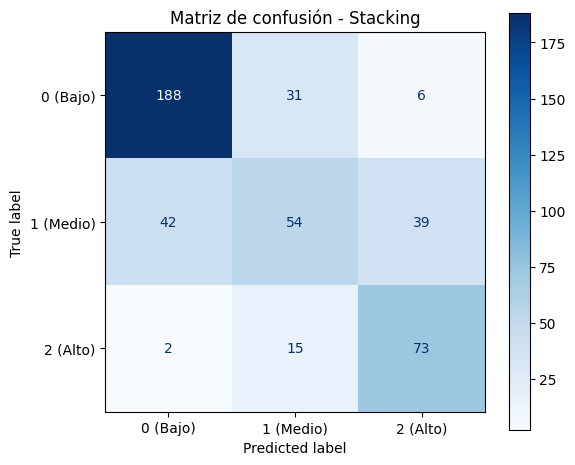

In [76]:
# Evaluación final sobre el test (una sola vez)
y_test_pred_stack = evaluar_en_test(busqueda_stack, umbral_stack, "Stacking")

En el conjunto de prueba, el stacking obtiene el mejor resultado global de los cinco modelos, con un F1-macro de 0,661, y también es el que mejor clasifica a los pacientes de riesgo moderado, identificando correctamente el 40 % de los casos.

Sin embargo, detecta correctamente 73 de los 90 pacientes de riesgo alto (81,1 %), menos que Random Forest (78 pacientes), la regresión logística (76) y k-NN (75). Además, su ventaja sobre la regresión logística es muy pequeña: obtiene un F1-macro de 0,661 frente a 0,656 en el conjunto de prueba y de 0,667 frente a 0,661 en validación cruzada. Estas diferencias son menores que la variación normal observada entre pliegues.

La regresión logística también presenta una balanced accuracy ligeramente superior (0,684 frente a 0,682). Por tanto, el aumento de rendimiento que aporta el stacking es mínimo y se consigue a costa de un modelo más complejo, más lento de entrenar y más difícil de interpretar.

# 8. Comparativa de modelos

Vamos a usar las predicciones obtenidas por cada modelo, para compararlos entre sí.

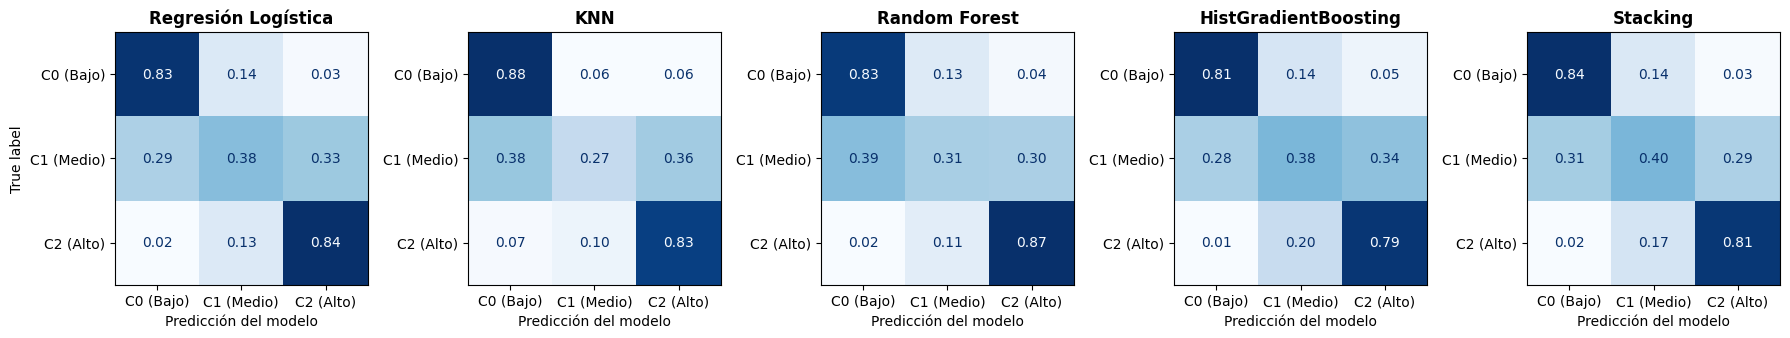

In [77]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

modelos = {
    "Regresión Logística": y_test_pred_lr,
    "KNN": y_test_pred_knn,
    "Random Forest": y_test_pred_rf,
    "HistGradientBoosting": y_test_pred_hgb,
    "Stacking": y_test_pred_stack
}

fig, axes = plt.subplots(1, len(modelos), figsize=(18, 4.5))

for ax, (nombre, y_pred) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["C0 (Bajo)", "C1 (Medio)", "C2 (Alto)"],
        normalize="true",  # Muestra porcentajes por clase real (Recall en la diagonal)
        values_format=".2f",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(nombre, fontweight="bold")
    ax.set_xlabel("Predicción del modelo")
    if ax != axes[0]:
        ax.set_ylabel("")

plt.tight_layout()
plt.show()

# 8.1 Comparativa de los modelos simples -> LR y KNN

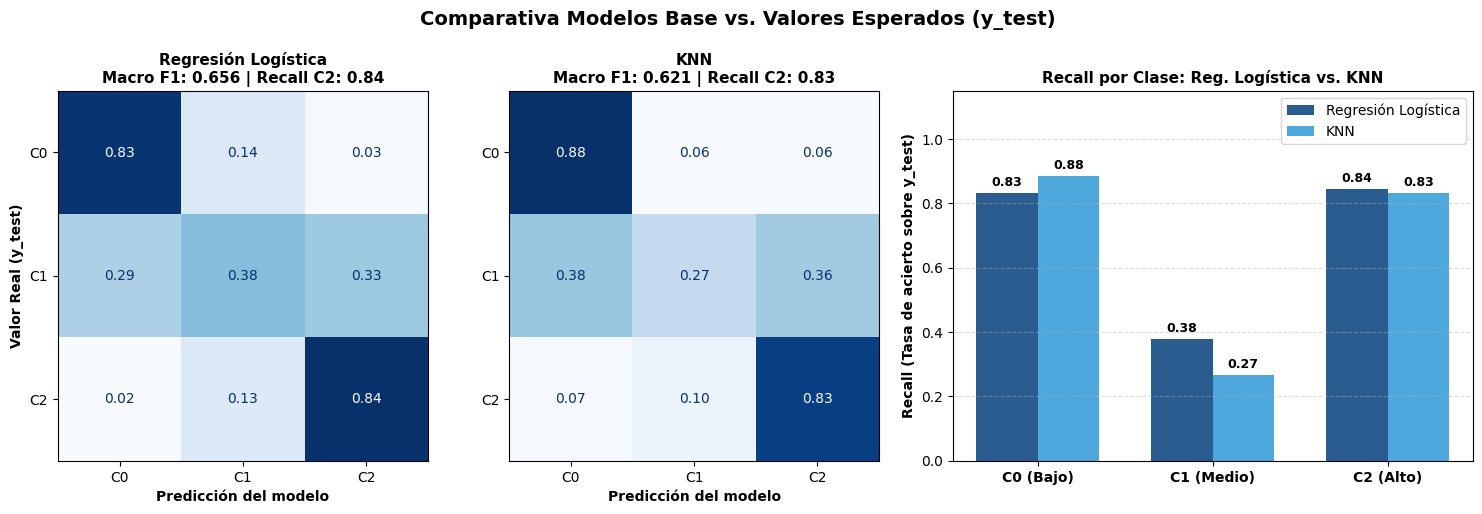

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, recall_score

# 1. Preparamos los datos del primer par de modelos
modelos_simples = {
    "Regresión Logística": y_test_pred_lr, 
    "KNN": y_test_pred_knn, 
}

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.8),
    gridspec_kw={"width_ratios": [1, 1, 1.35]},
)

clases_labels = ["C0 (Bajo)", "C1 (Medio)", "C2 (Alto)"]
recalls_dict = {}

# 2. Dibujamos las Matrices de Confusión (Predicho vs. y_test)
for ax, (nombre, y_pred) in zip(axes[:2], modelos_simples.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["C0", "C1", "C2"],
        normalize="true",  # Normalizado por fila: la diagonal es el Recall real
        values_format=".2f",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    rec_c2 = recall_score(y_test, y_pred, labels=[2], average=None)[0]

    ax.set_title(
        f"{nombre}\nMacro F1: {macro_f1:.3f} | Recall C2: {rec_c2:.2f}",
        fontweight="bold",
        fontsize=11,
    )
    ax.set_xlabel("Predicción del modelo", fontweight="bold")

    if ax == axes[0]:
        ax.set_ylabel("Valor Real (y_test)", fontweight="bold")
    else:
        ax.set_ylabel("")

    # Guardamos el Recall de las 3 clases
    recalls_dict[nombre] = recall_score(
        y_test, y_pred, labels=[0, 1, 2], average=None
    )

# 3. Dibujamos la comparativa directa de Recall por clase
ax_bar = axes[2]
x = np.arange(len(clases_labels))
ancho = 0.35

colores = ["#2b5c8f", "#4ea8de"]
for i, (nombre, recalls) in enumerate(recalls_dict.items()):
    offset = (i - 0.5) * ancho
    barras = ax_bar.bar(
        x + offset, recalls, width=ancho, label=nombre, color=colores[i]
    )
    ax_bar.bar_label(barras, fmt="%.2f", fontsize=9, padding=3, fontweight="bold")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(clases_labels, fontweight="bold")
ax_bar.set_ylim(0, 1.15)
ax_bar.set_ylabel("Recall (Tasa de acierto sobre y_test)", fontweight="bold")
ax_bar.set_title(
    "Recall por Clase: Reg. Logística vs. KNN", fontweight="bold", fontsize=11
)
ax_bar.grid(axis="y", linestyle="--", alpha=0.4)
ax_bar.legend(loc="upper right", frameon=True)

fig.suptitle(
    "Comparativa Modelos Base vs. Valores Esperados (y_test)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

Ambos modelos clasifican correctamente la mayoría de los pacientes de riesgo bajo (83 % la regresión logística y 88 % k-NN) y de riesgo alto (84 % y 83 %, respectivamente). Sin embargo, tienen dificultades para identificar a los pacientes de riesgo moderado: la regresión logística acierta el 38 % de los casos y k-NN solo el 27 %.

En muchos casos, los pacientes de riesgo moderado se confunden con pacientes de riesgo bajo o alto. Este comportamiento era esperable, ya que durante el EDA se observó que la clase intermedia se solapa considerablemente con las otras dos en las variables analizadas.

En términos globales, la regresión logística ofrece mejores resultados que k-NN, alcanzando un F1-macro de 0,656 frente al 0,621 obtenido por este último.

# 8.2 Comparativa de los modelos complejos -> RF, HGB y Stacking

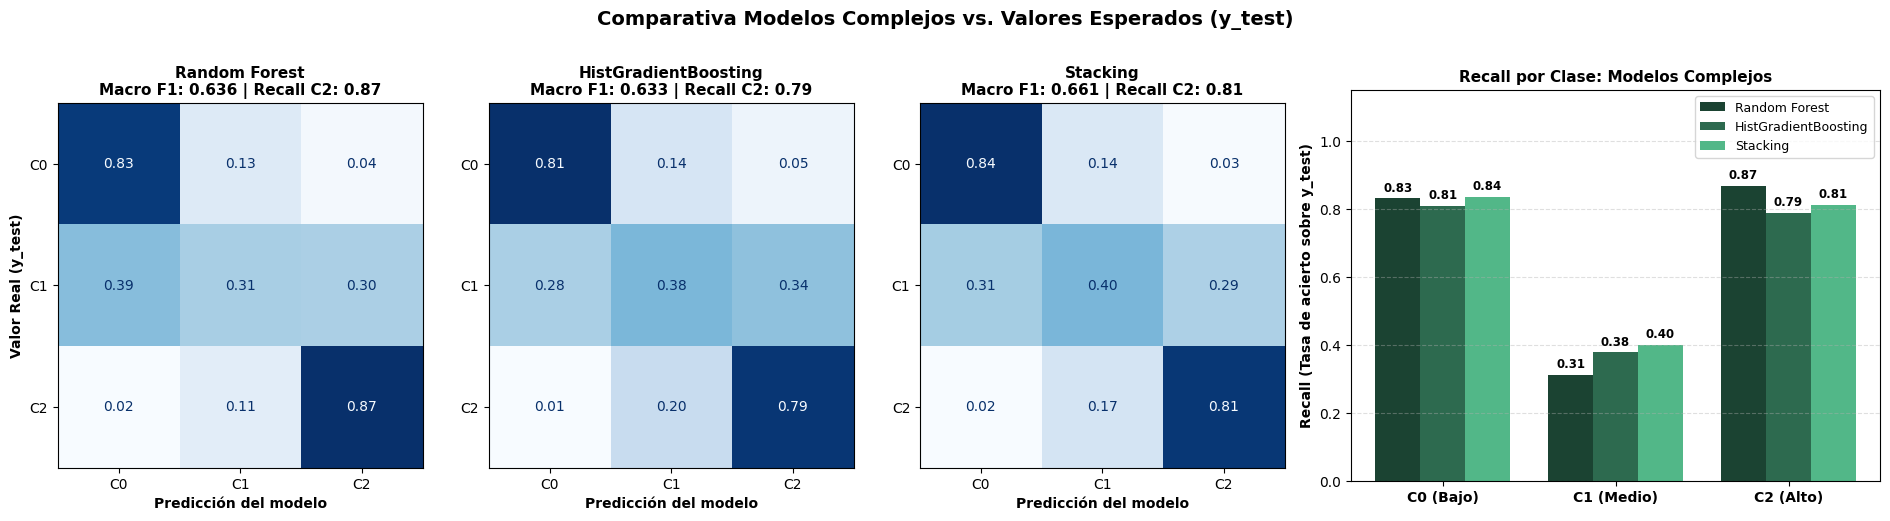

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, recall_score

# 1. Preparamos los datos de los 3 modelos complejos
modelos_complejos = {
    "Random Forest": y_test_pred_rf,
    "HistGradientBoosting": y_test_pred_hgb,
    "Stacking": y_test_pred_stack,
}

fig, axes = plt.subplots(
    1,
    4,
    figsize=(19, 5),
    gridspec_kw={"width_ratios": [1, 1, 1, 1.45]},
)

clases_labels = ["C0 (Bajo)", "C1 (Medio)", "C2 (Alto)"]
recalls_dict = {}

# 2. Dibujamos las 3 Matrices de Confusión (Predicho vs. y_test)
for ax, (nombre, y_pred) in zip(axes[:3], modelos_complejos.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["C0", "C1", "C2"],
        normalize="true",  # Normalizado por fila: la diagonal es el Recall real
        values_format=".2f",
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    rec_c2 = recall_score(y_test, y_pred, labels=[2], average=None)[0]

    ax.set_title(
        f"{nombre}\nMacro F1: {macro_f1:.3f} | Recall C2: {rec_c2:.2f}",
        fontweight="bold",
        fontsize=11,
    )
    ax.set_xlabel("Predicción del modelo", fontweight="bold")

    if ax == axes[0]:
        ax.set_ylabel("Valor Real (y_test)", fontweight="bold")
    else:
        ax.set_ylabel("")

    # Guardamos el Recall de las 3 clases
    recalls_dict[nombre] = recall_score(
        y_test, y_pred, labels=[0, 1, 2], average=None
    )

# 3. Dibujamos la comparativa directa de Recall por clase (3 barras por clase)
ax_bar = axes[3]
x = np.arange(len(clases_labels))
ancho = 0.26

colores = ["#1b4332", "#2d6a4f", "#52b788"]  # Gama verde para diferenciar el bloque complejo
for i, (nombre, recalls) in enumerate(recalls_dict.items()):
    offset = (i - 1) * ancho
    barras = ax_bar.bar(
        x + offset, recalls, width=ancho, label=nombre, color=colores[i]
    )
    ax_bar.bar_label(barras, fmt="%.2f", fontsize=8.5, padding=3, fontweight="bold")

ax_bar.set_xticks(x)
ax_bar.set_xticklabels(clases_labels, fontweight="bold")
ax_bar.set_ylim(0, 1.15)
ax_bar.set_ylabel("Recall (Tasa de acierto sobre y_test)", fontweight="bold")
ax_bar.set_title(
    "Recall por Clase: Modelos Complejos", fontweight="bold", fontsize=11
)
ax_bar.grid(axis="y", linestyle="--", alpha=0.4)
ax_bar.legend(loc="upper right", frameon=True, fontsize=9)

fig.suptitle(
    "Comparativa Modelos Complejos vs. Valores Esperados (y_test)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

Los tres modelos de tipo ensemble muestran un comportamiento muy parecido. Todos clasifican correctamente a la mayoría de los pacientes de riesgo bajo (entre el 81 % y el 84 %) y de riesgo alto (entre el 79 % y el 87 %), pero siguen teniendo dificultades para identificar a los pacientes de riesgo moderado, con porcentajes de acierto entre el 31 % y el 40 %.

Por tanto, ninguno consigue resolver completamente la clasificación de la clase intermedia. Random Forest es el modelo que mejor detecta a los pacientes de riesgo alto, identificando correctamente el 87 % de ellos, aunque a costa de obtener el peor resultado en la clase moderada (31 %). Por su parte, HistGradientBoosting no alcanza el objetivo de detectar al menos el 80 % de los pacientes de riesgo alto. Finalmente, el stacking consigue el mejor rendimiento global (F1-macro = 0,661) y también el mejor resultado en la clasificación de los pacientes de riesgo moderado (40 %).

## 9. Elección del modelo final

Elección del modelo final: regresión logística.

- Su rendimiento es muy similar al del mejor modelo obtenido. En el conjunto de prueba alcanza un F1-macro de 0,656, frente al 0,661 del stacking, y en validación cruzada obtiene 0,661 frente a 0,667. Estas diferencias son muy pequeñas y se encuentran dentro de la variación normal observada entre pliegues.

- Presenta la mejor balanced accuracy (0,684) y cumple cómodamente el objetivo clínico marcado, detectando correctamente el 84,4 % de los pacientes de riesgo alto.

- Es el modelo que mejor generaliza. Su rendimiento es muy parecido en entrenamiento (0,680) y validación (0,661), lo que indica poco sobreajuste. En comparación, el stacking alcanza 0,958 en entrenamiento, pero pierde gran parte de ese rendimiento al evaluarse sobre datos no vistos.

- Por último, es un modelo fácilmente interpretable. Sus coeficientes permiten identificar qué variables contribuyen a aumentar o reducir el riesgo cardiovascular, una característica especialmente valiosa en un entorno clínico.

Que los modelos ensemble no mejoren de forma clara a la regresión logística es coherente con lo observado durante el EDA. Las diferencias entre grupos son moderadas y la información relevante parece estar repartida entre muchas variables, sin patrones complejos o interacciones fuertes que requieran modelos más sofisticados para ser aprovechados.